In [1]:
import os, glob
import numpy as np
import scipy.io as sio

ROOT = "/kaggle/input"
for dirpath, dirs, files in os.walk(ROOT):
    depth = dirpath[len(ROOT):].count(os.sep)
    if depth <= 3:
        print(dirpath, "| dirs:", len(dirs), "| files:", len(files))
        for f in files[:5]:
            print("   ", f, os.path.getsize(os.path.join(dirpath, f)) // 1024, "KB")

mats = glob.glob(f"{ROOT}/**/*.mat", recursive=True)
print("\nTotal .mat files:", len(mats))
if mats:
    m = sio.loadmat(mats[0])
    print("Sample file:", mats[0])
    for k, v in m.items():
        if not k.startswith("__"):
            print(k, getattr(v, "shape", None), getattr(v, "dtype", None))

/kaggle/input | dirs: 1 | files: 0
/kaggle/input/datasets | dirs: 1 | files: 0
/kaggle/input/datasets/marjan15 | dirs: 1 | files: 0
/kaggle/input/datasets/marjan15/ninaprodb2 | dirs: 1 | files: 0

Total .mat files: 120
Sample file: /kaggle/input/datasets/marjan15/ninaprodb2/data/DB2_s40/DB2_s40/S40_E3_A1.mat
emg (874688, 12) float32
acc (874688, 36) float32
stimulus (874688, 1) int8
force (874688, 6) float32
forcecal (2, 6) float32
subject (1, 1) uint8
exercise (1, 1) uint8
activation (874688, 6) float32
repetition (874688, 1) int8
restimulus (874688, 1) int8
rerepetition (874688, 1) int8


In [2]:
#SETUP & CONFIGURATION 
import os, re, glob, json, hashlib, time, pickle, warnings, math, itertools, shutil, sys, subprocess
from collections import defaultdict
import numpy as np, pandas as pd
import scipy.io as sio
from scipy import stats, signal
import matplotlib.pyplot as plt
import seaborn as sns
import networkx as nx
from sklearn.decomposition import PCA
from sklearn.manifold import TSNE
from sklearn.preprocessing import StandardScaler
from tqdm.auto import tqdm
import plotly.graph_objects as go
import plotly.express as px
from plotly.subplots import make_subplots

warnings.filterwarnings("ignore")
pd.set_option("display.width", 220); pd.set_option("display.max_columns", 80); pd.set_option("display.max_rows", 120)
sns.set_theme(style="whitegrid", context="notebook")

CFG = dict(
    DATA_ROOT=os.environ.get("NINAPRO_ROOT", "/kaggle/input"),   # searched recursively for S*_E*_A*.mat
    OUT_DIR=os.environ.get("NINAPRO_OUT", "/kaggle/working/outputs"),
    SEED=42,
    FS_HZ=2000,                  # from the NinaPro DB2 documentation; NOT stored inside the .mat files (see Section A)
    WIN_MS=200, STEP_MS=10,      # INITIAL experimental setting, not claimed optimal
    WIN_GRID_MS=[100, 150, 200, 250, 300, 400], STEP_GRID_MS=[10, 20, 50, 100],
    SAMPLES_PER_FILE=4000,       # random raw samples kept per file (distribution plots, quantiles, Spearman)
    WIN_CAP_PER_FILE_CLASS=8,    # sampled windows kept per (file, class) for features / raw-window PCA
    ZC_EPS_FRAC=0.05,            # zero-crossing dead-band = 5% of that file's per-channel std
    NEAR_CONST_REL=0.01,         # channel flagged if file std < 1% of that channel's median file std
    REPEAT_FRAC_THR=0.5,         # ... or if >50% of consecutive samples are identical
    SAT_FRAC_THR=1e-3,           # flag if >0.1% of samples sit exactly at the channel's file max/min
    CORR_THR=0.9, ROBUST_Z=3.5,  # configurable reporting thresholds
    GRAPH_SIM="rms_envelope",    # similarity for graphs: "rms_envelope" or "raw"
    KNN_K_LIST=[2, 3, 4, 5, 6],
    CORR_THR_LIST=[round(float(t), 2) for t in np.arange(0.1, 1.0, 0.1)],
    TEST_FRAC=0.2, VAL_FRAC=0.1,
    N_FOLDS=5, EDA_FOLD=0,       # 5 subject-wise folds; EDA (scaler/PCA/graph similarity) uses the TRAIN subjects of fold EDA_FOLD
    EMBED_MAX_PER_EXERCISE=3000, # max windows per exercise for t-SNE / UMAP
    DUP_ROWS=True, FORCE_RECOMPUTE=False,
    PLOTLY_JS="cdn",             # 'cdn' (small HTML, needs internet to open) or True (self-contained)
)
SEED = CFG["SEED"]; FS = CFG["FS_HZ"]
W = int(round(CFG["WIN_MS"] * FS / 1000)); S = int(round(CFG["STEP_MS"] * FS / 1000))
np.random.seed(SEED)

OUT = CFG["OUT_DIR"]
FIG_DIR, HTML_DIR, TAB_DIR, REP_DIR = [os.path.join(OUT, d) for d in ("figures", "interactive", "tables", "reports")]
CACHE_DIR = os.path.join(os.path.dirname(OUT.rstrip("/")), "cache")
for d in (FIG_DIR, HTML_DIR, TAB_DIR, REP_DIR, CACHE_DIR): os.makedirs(d, exist_ok=True)

try:
    import umap; HAS_UMAP = True
except Exception:
    try:
        subprocess.run([sys.executable, "-m", "pip", "install", "-q", "umap-learn"], check=True, timeout=300)
        import umap; HAS_UMAP = True
    except Exception as e:
        HAS_UMAP = False
try:
    import torch; HAS_TORCH = True
except Exception:
    HAS_TORCH = False
print(f"UMAP available: {HAS_UMAP} | PyTorch available: {HAS_TORCH}")
print(f"Window = {CFG['WIN_MS']} ms = {W} samples @ {FS} Hz | step = {CFG['STEP_MS']} ms = {S} samples | overlap = {1 - S / W:.1%}")

UMAP available: True | PyTorch available: True
Window = 200 ms = 400 samples @ 2000 Hz | step = 10 ms = 20 samples | overlap = 95.0%


In [3]:
# HELPERS
REPORT = defaultdict(list)            # findings collected for the final report
def note(section, text):
    REPORT[section].append(text); print(f"[{section}] {text}")

def savefig(fig, name, dpi=150):
    path = os.path.join(FIG_DIR, name + ".png"); fig.savefig(path, dpi=dpi, bbox_inches="tight"); plt.show(); return path

def save_table(df, name, index=False):
    df.to_csv(os.path.join(TAB_DIR, name + ".csv"), index=index); return df

def save_html(fig, name):
    path = os.path.join(HTML_DIR, name + ".html"); fig.write_html(path, include_plotlyjs=CFG["PLOTLY_JS"]); return path

def interpret(what, observed, why, cannot):
    print("\n--- Reading of the figure/table ---")
    print("WHAT IS SHOWN       :", what)
    print("OBSERVED (computed) :", observed)
    print("WHY IT MAY MATTER   :", why, "(hypothesis)")
    print("CANNOT BE CONCLUDED :", cannot, "\n")

def fmt(x, nd=3):
    return f"{x:.{nd}g}" if isinstance(x, (float, np.floating)) else str(x)

In [4]:
pat = re.compile(r"S(\d+)_E(\d+)_A(\d+)\.mat$")
paths = sorted(glob.glob(os.path.join(CFG["DATA_ROOT"], "**", "S*_E*_A*.mat"), recursive=True))
assert len(paths) > 0, f"No S*_E*_A*.mat files found under {CFG['DATA_ROOT']} - check the attached dataset."
rows = []
for p in paths:
    m = pat.search(os.path.basename(p))
    if not m: continue
    vs = sio.whosmat(p)                                   # [(name, shape, class), ...]
    vd = {n: (tuple(s), c) for n, s, c in vs}
    rows.append(dict(path=p, file=os.path.basename(p), subject_fn=int(m[1]), exercise_fn=int(m[2]), A=int(m[3]),
                     size_mb=os.path.getsize(p) / 2**20, n_vars=len(vd), var_names=";".join(vd),
                     emg_shape=vd.get("emg", (None, None))[0], emg_class=vd.get("emg", (None, None))[1],
                     var_shapes="; ".join(f"{n}{s}:{c}" for n, (s, c) in vd.items())))
inv = pd.DataFrame(rows).sort_values(["subject_fn", "exercise_fn", "A"]).reset_index(drop=True)
inv["file_id"] = np.arange(len(inv))
print(f"{len(inv)} files | {inv.subject_fn.nunique()} subjects | exercises {sorted(inv.exercise_fn.unique())} | total {inv.size_mb.sum() / 1024:.2f} GB")
print("Distinct root folders:", sorted({os.path.dirname(p) for p in inv.path})[:3], "...")
save_table(inv.drop(columns=["path"]), "file_inventory")
display(inv[["file", "subject_fn", "exercise_fn", "size_mb", "emg_shape", "n_vars"]].head(8))
print("Variables present, with number of files containing each:")
vc = pd.Series([v for s in inv.var_names for v in s.split(";")]).value_counts()
display(vc.to_frame("n_files"))

120 files | 40 subjects | exercises [np.int64(1), np.int64(2), np.int64(3)] | total 17.05 GB
Distinct root folders: ['/kaggle/input/datasets/marjan15/ninaprodb2/data/DB2_s1/DB2_s1', '/kaggle/input/datasets/marjan15/ninaprodb2/data/DB2_s10/DB2_s10', '/kaggle/input/datasets/marjan15/ninaprodb2/data/DB2_s11/DB2_s11'] ...


,file,subject_fn,exercise_fn,size_mb,emg_shape,n_vars
0,S1_E1_A1.mat,1,1,144.467054,"(1808331, 12)",10
1,S1_E2_A1.mat,1,2,233.087475,"(2553289, 12)",10
2,S1_E3_A1.mat,1,3,72.103116,"(877073, 12)",11
3,S2_E1_A1.mat,2,1,163.985737,"(1803711, 12)",10
4,S2_E2_A1.mat,2,2,224.936268,"(2550528, 12)",10
5,S2_E3_A1.mat,2,3,71.246555,"(876373, 12)",11
6,S3_E1_A1.mat,3,1,145.824889,"(1795150, 12)",10
7,S3_E2_A1.mat,3,2,242.263234,"(2541573, 12)",10


Variables present, with number of files containing each:


,n_files
emg,120
acc,120
stimulus,120
exercise,120
subject,120
rerepetition,120
restimulus,120
repetition,120
glove,80
inclin,80


# One streaming pass over all files
Each file is loaded once (only the variables needed), summarised, and released.

In [5]:
REQ_VARS = ["emg", "stimulus", "restimulus", "repetition", "rerepetition", "subject", "exercise"]
FEATS = ["RMS", "MAV", "WL", "ZC", "VAR"]

def rle(*arrs):
    # run-length encode on the stacked label arrays -> start/end indices of constant runs
    a = np.stack(arrs, 1)
    change = np.any(a[1:] != a[:-1], axis=1)
    starts = np.r_[0, np.flatnonzero(change) + 1]
    return starts, np.r_[starts[1:], len(a)]

def longest_true_run(b):
    if b.size == 0 or not b.any(): return 0
    d = np.diff(np.r_[0, b.astype(np.int8), 0])
    return int((np.flatnonzero(d == -1) - np.flatnonzero(d == 1)).max())

def window_features(x, eps):
    # x: (k, C, L); eps: (C,) zero-crossing dead-band. Features are computed per channel over the L samples of the window/segment.
    x = x.astype(np.float64, copy=False)
    d = np.diff(x, axis=-1)
    zc = ((x[..., :-1] * x[..., 1:]) < 0) & (np.abs(d) >= eps[None, :, None])
    return {"RMS": np.sqrt((x ** 2).mean(-1)), "MAV": np.abs(x).mean(-1), "WL": np.abs(d).sum(-1),
            "ZC": zc.sum(-1).astype(np.float64), "VAR": x.var(-1)}

def raw_moments(x):
    x = x.astype(np.float64)
    return dict(n=len(x), s1=x.sum(0), s2=(x ** 2).sum(0), s3=(x ** 3).sum(0), s4=(x ** 4).sum(0), sabs=np.abs(x).sum(0))

def add_moments(ms):
    out = None
    for m in ms:
        if out is None: out = {k: (v.copy() if hasattr(v, "copy") else v) for k, v in m.items()}
        else:
            for k in out: out[k] = out[k] + m[k]
    return out

def central_stats(m):
    # Population (biased) moment estimators. kurtosis = Fisher EXCESS kurtosis (normal distribution = 0).
    n = m["n"]; mu = m["s1"] / n
    m2 = m["s2"] / n - mu ** 2
    m3 = m["s3"] / n - 3 * mu * m["s2"] / n + 2 * mu ** 3
    m4 = m["s4"] / n - 4 * mu * m["s3"] / n + 6 * mu ** 2 * m["s2"] / n - 3 * mu ** 4
    sd = np.sqrt(np.maximum(m2, 0))
    with np.errstate(all="ignore"):
        return dict(count=n, mean=mu, var=m2, std=sd, skew=m3 / sd ** 3, kurt_excess=m4 / m2 ** 2 - 3,
                    rms=np.sqrt(m["s2"] / n), mav=m["sabs"] / n)

def class_key(ex, v): return f"E{ex}_REST" if v == 0 else f"E{ex}_G{int(v):02d}"

def analyse_file(info, cfg):
    rng = np.random.default_rng([cfg["SEED"], info["subject_fn"], info["exercise_fn"], info["A"]])
    m = sio.loadmat(info["path"], variable_names=REQ_VARS)
    ex, sj = info["exercise_fn"], info["subject_fn"]
    emg = np.asarray(m["emg"]); n, C = emg.shape
    g = lambda k: (np.asarray(m[k]).ravel().astype(np.int64) if k in m else None)
    stim, restim, rep, rerep = g("stimulus"), g("restimulus"), g("repetition"), g("rerepetition")
    label_source = "restimulus" if restim is not None else ("stimulus" if stim is not None else "none")
    lab = restim if restim is not None else (stim if stim is not None else np.zeros(n, np.int64))
    rr = rerep if rerep is not None else (rep if rep is not None else np.zeros(n, np.int64))
    # ---- length consistency: emg and label arrays should have equal length. If they differ, every array is trimmed to the
    #      common length (alignment at the START is ASSUMED), and the mismatch is recorded per file - never silently ignored.
    lens = {"emg": n}
    for k_, a_ in (("stimulus", stim), ("restimulus", restim), ("repetition", rep), ("rerepetition", rerep)):
        if a_ is not None: lens[k_] = len(a_)
    n_min = min(lens.values()); trimmed = {k_: v_ - n_min for k_, v_ in lens.items() if v_ != n_min}
    len_issues = [f"length mismatch (original lengths {lens}); all arrays trimmed to {n_min} samples assuming start alignment"] if trimmed else []
    if trimmed:
        emg = emg[:n_min]; lab = lab[:n_min]; rr = rr[:n_min]; n = n_min
        stim = stim[:n_min] if stim is not None else None; restim = restim[:n_min] if restim is not None else None
    xf = emg.astype(np.float64)
    finite = np.isfinite(xf); valid = finite.all(1)
    out = dict(info={k: info[k] for k in ("file_id", "file", "subject_fn", "exercise_fn", "A", "size_mb")}, n=n, C=C,
               label_source=label_source, trimmed=trimmed, lens_original=lens)

    # ---- metadata consistency (missing METADATA, distinct from invalid SIGNAL samples)
    issues = []
    missing_vars = [v for v in REQ_VARS if v not in m]
    if "subject" in m and int(np.asarray(m["subject"]).ravel()[0]) != sj: issues.append("subject variable != file name")
    if "exercise" in m and int(np.asarray(m["exercise"]).ravel()[0]) != ex: issues.append("exercise variable != file name")
    issues += len_issues
    out.update(missing_vars=missing_vars, meta_issues=issues)

    # ---- sample-level quality
    out["nan_c"] = (~np.isfinite(xf) & np.isnan(xf)).sum(0); out["inf_c"] = np.isinf(xf).sum(0)
    out["n_invalid_rows"] = int((~valid).sum())
    xv = xf[valid]
    out["min_c"] = xv.min(0); out["max_c"] = xv.max(0)
    out["frac_at_max_c"] = (xv == xv.max(0)).mean(0); out["frac_at_min_c"] = (xv == xv.min(0)).mean(0)
    same = (xf[1:] == xf[:-1])
    out["frac_repeat_c"] = same.mean(0)
    out["frac_repeat_allch"] = float(same.all(1).mean()); out["longest_flat_run_allch"] = longest_true_run(same.all(1))
    out["n_dup_rows"] = int(pd.DataFrame(emg).duplicated().sum()) if cfg["DUP_ROWS"] else -1
    out["file_md5"] = hashlib.md5(emg.tobytes()).hexdigest()
    out["relabel_diff_frac"] = float((stim != restim).mean()) if (stim is not None and restim is not None) else np.nan
    out["labels_observed"] = sorted(np.unique(lab).tolist()); out["reps_observed"] = sorted(np.unique(rr).tolist())

    # ---- exact moments
    out["mom_all"] = raw_moments(xv)
    act = valid & (lab > 0)
    out["mom_act"] = raw_moments(xf[act]) if act.any() else None
    sd_file = xv.std(0); eps = cfg["ZC_EPS_FRAC"] * sd_file

    # ---- per-class sufficient statistics for exact Pearson matrices
    cst = {}
    tot_n, tot_s, tot_x = 0, 0, 0
    for v in np.unique(lab):
        mk = valid & (lab == v)
        if not mk.any(): continue
        xc = xf[mk]; nn, ss, xx = len(xc), xc.sum(0), xc.T @ xc
        cst[class_key(ex, v)] = (nn, ss, xx)
        tot_n += nn; tot_s = tot_s + ss; tot_x = tot_x + xx
    cst["ALL"] = (tot_n, tot_s, tot_x)
    out["cstats"] = cst

    # ---- segments (constant label & repetition) with per-segment descriptors
    starts, ends = rle(lab, rr)
    cs = np.r_[0, np.cumsum(~valid)]
    seg_rows, seg_feat = [], {f: [] for f in FEATS}
    cand = defaultdict(list)
    for si, (s0, e0) in enumerate(zip(starts, ends)):
        L = e0 - s0; v = int(lab[s0]); ck = class_key(ex, v)
        xs = xf[s0:e0]; xs = xs[np.isfinite(xs).all(1)]
        if len(xs) > 1: ft = window_features(xs.T[None], eps)
        else: ft = {f: np.full((1, C), np.nan) for f in FEATS}
        for f in FEATS: seg_feat[f].append(ft[f][0])
        nw = (L - W) // S + 1 if L >= W else 0
        if L >= W:
            st = np.arange(s0, e0 - W + 1, S)
            ok = (cs[st + W] - cs[st]) == 0
            nwv = int(ok.sum()); st = st[ok]
            if len(st): cand[ck].append(np.c_[st, np.full(len(st), si)])
        else: nwv = 0
        seg_rows.append(dict(file_id=info["file_id"], subject=sj, exercise=ex, seg_idx=si, label=v, class_key=ck,
                             rerep=int(rr[s0]), start=int(s0), end=int(e0), length=int(L), is_rest=(v == 0),
                             n_win=int(nw), n_win_valid=nwv, md5=hashlib.md5(emg[s0:e0].tobytes()).hexdigest(),
                             n_unique_vals=int(len(np.unique(emg[s0:e0, 0]))) ))
    out["seg"] = pd.DataFrame(seg_rows); out["seg_feat"] = {f: np.array(v) for f, v in seg_feat.items()}

    # ---- random raw samples
    vi = np.flatnonzero(valid)
    idx = np.sort(rng.choice(vi, size=min(cfg["SAMPLES_PER_FILE"], len(vi)), replace=False))
    out["samp"] = dict(emg=emg[idx].astype(np.float32), subject=np.full(len(idx), sj), exercise=np.full(len(idx), ex),
                       label=lab[idx], class_key=np.array([class_key(ex, v) for v in lab[idx]]), rerep=rr[idx],
                       file_id=np.full(len(idx), info["file_id"]), t_s=idx / cfg["FS_HZ"])

    # ---- sampled windows (stratified by class within the file; raw + handcrafted features)
    wm, wraw, wf = [], [], {f: [] for f in FEATS}
    for ck, lst in cand.items():
        arr = np.concatenate(lst)
        pick = rng.choice(len(arr), size=min(cfg["WIN_CAP_PER_FILE_CLASS"], len(arr)), replace=False)
        for a in arr[np.sort(pick)]:
            s0 = int(a[0]); wraw.append(emg[s0:s0 + W].T.astype(np.float32))
            wm.append(dict(file_id=info["file_id"], subject=sj, exercise=ex, class_key=ck, label=int(lab[s0]),
                           rerep=int(rr[s0]), seg_idx=int(a[1]), start=s0))
    if wraw:
        wraw = np.stack(wraw); ft = window_features(wraw, eps)
        out["win"] = dict(meta=pd.DataFrame(wm), raw=wraw, feat=ft)
    else: out["win"] = None
    return out

cache_name = f"pass1_W{W}_S{S}_n{CFG['SAMPLES_PER_FILE']}_cap{CFG['WIN_CAP_PER_FILE_CLASS']}_eps{CFG['ZC_EPS_FRAC']}_seed{SEED}_f{len(inv)}.pkl"
cache_path = os.path.join(CACHE_DIR, cache_name)
if os.path.exists(cache_path) and not CFG["FORCE_RECOMPUTE"]:
    print("Loading cached pass:", cache_path)
    res = pickle.load(open(cache_path, "rb"))
else:
    t0 = time.time(); res = []
    for _, r in tqdm(inv.iterrows(), total=len(inv), desc="Analysing files"):
        res.append(analyse_file(r.to_dict(), CFG))
    print(f"Pass finished in {time.time() - t0:.0f} s")
    pickle.dump(res, open(cache_path, "wb"), protocol=4)
print(len(res), "files analysed")

Analysing files:   0%|          | 0/120 [00:00<?, ?it/s]

Pass finished in 1550 s
120 files analysed


In [6]:
#assemble compact analysis tables from the pass
C = res[0]["C"]; CH = [f"ch{c + 1:02d}" for c in range(C)]
file_df = pd.DataFrame([dict(file_id=r["info"]["file_id"], file=r["info"]["file"], subject=r["info"]["subject_fn"],
                             exercise=r["info"]["exercise_fn"], n_samples=r["n"], n_channels=r["C"],
                             duration_s=r["n"] / FS, size_mb=r["info"]["size_mb"], n_invalid_rows=r["n_invalid_rows"],
                             n_nan=int(r["nan_c"].sum()), n_inf=int(r["inf_c"].sum()), n_dup_rows=r["n_dup_rows"],
                             frac_repeat_allch=r["frac_repeat_allch"], longest_flat_run_allch=r["longest_flat_run_allch"],
                             relabel_diff_frac=r["relabel_diff_frac"], label_source=r["label_source"],
                             missing_vars=",".join(r["missing_vars"]), meta_issues="; ".join(r["meta_issues"]),
                             md5=r["file_md5"], n_labels=len(r["labels_observed"]), n_reps=len(r["reps_observed"]))
                        for r in res])
chan = {k: np.array([r[k] for r in res]) for k in ("nan_c", "inf_c", "min_c", "max_c", "frac_at_max_c", "frac_at_min_c", "frac_repeat_c")}
file_stats = [central_stats(r["mom_all"]) for r in res]
for k in ("std", "rms", "mean", "mav"): chan[k] = np.array([fs[k] for fs in file_stats])

seg_df = pd.concat([r["seg"] for r in res], ignore_index=True)
for f in FEATS:
    arr = np.concatenate([r["seg_feat"][f] for r in res])
    seg_df[[f"{f}_{c}" for c in CH]] = arr
seg_df["seg_uid"] = seg_df.file_id * 100000 + seg_df.seg_idx
seg_df["duration_s"] = seg_df.length / FS

samp = {k: np.concatenate([r["samp"][k] for r in res]) for k in res[0]["samp"]}
samp_df = pd.DataFrame(samp["emg"], columns=CH)
for k in ("subject", "exercise", "label", "class_key", "rerep", "file_id", "t_s"): samp_df[k] = samp[k]

wres = [r["win"] for r in res if r["win"] is not None]
win_meta = pd.concat([w["meta"] for w in wres], ignore_index=True)
win_raw = np.concatenate([w["raw"] for w in wres]); win_feat = {f: np.concatenate([w["feat"][f] for w in wres]) for f in FEATS}
win_meta["is_rest"] = win_meta.label == 0

print("file_df", file_df.shape, "| seg_df", seg_df.shape, "| samp_df", samp_df.shape)
print("sampled windows:", win_raw.shape, f"({win_raw.nbytes / 2**20:.0f} MB raw float32) | features: {len(FEATS)} x {C} per window")
display(file_df.head(5))

file_df (120, 21) | seg_df (23640, 77) | samp_df (480000, 19)
sampled windows: (16640, 12, 400) (305 MB raw float32) | features: 5 x 12 per window


,file_id,file,subject,exercise,n_samples,n_channels,duration_s,size_mb,n_invalid_rows,n_nan,n_inf,n_dup_rows,frac_repeat_allch,longest_flat_run_allch,relabel_diff_frac,label_source,missing_vars,meta_issues,md5,n_labels,n_reps
0,0,S1_E1_A1.mat,1,1,1808331,12,904.1655,144.467054,0,0,0,0,0.0,0,0.235063,restimulus,,,2bc226394a6c787b0cb3aa8db82d669a,18,7
1,1,S1_E2_A1.mat,1,2,2553289,12,1276.6445,233.087475,0,0,0,0,0.0,0,0.204541,restimulus,,,4164723a599b0d0d1de91b82637f5b07,24,7
2,2,S1_E3_A1.mat,1,3,877072,12,438.5360,72.103116,0,0,0,0,0.0,0,0.089006,restimulus,,length mismatch (original lengths {'emg': 8770...,34b3ab2eeb35cc7ba7c9741ea30437e6,10,7
3,3,S2_E1_A1.mat,2,1,1803711,12,901.8555,163.985737,0,0,0,0,0.0,0,0.199287,restimulus,,,4e3aa6023d34cc945a6e70cacd509c57,18,7
4,4,S2_E2_A1.mat,2,2,2550528,12,1275.2640,224.936268,0,0,0,0,0.0,0,0.153913,restimulus,,,d25023cd483296b46789d73915ad1992,24,7


#  Subject split defined **before** any data-dependent graph / scaling decision
A fixed, seeded, subject-independent partition is created once. Descriptive statistics in Sections A–E use all subjects (they inform understanding, not model selection). **Every quantity that could feed a predictive experiment — graph similarity matrices, correlation thresholds, scalers, PCA fits — is computed from `TRAIN` subjects only.** The test subjects are never used to choose anything.

In [7]:
def make_subject_folds(subjects, seed, n_folds, val_frac):
    rng = np.random.default_rng(seed); s = np.array(sorted(subjects)); rng.shuffle(s)
    fold_of = {int(x): i % n_folds for i, x in enumerate(s)}                  # every subject is in exactly one test fold
    n_val = max(1, int(round(len(s) * val_frac))); folds = []
    for k in range(n_folds):
        test = sorted(x for x in fold_of if fold_of[x] == k); rest = [x for x in sorted(fold_of) if fold_of[x] != k]
        val = sorted(np.random.default_rng(seed + k).choice(rest, size=n_val, replace=False).astype(int).tolist())
        folds.append(dict(fold=k, test=test, val=val, train=[x for x in rest if x not in val]))
    return folds, fold_of

subjects_all = [int(s) for s in sorted(file_df.subject.unique())]
FOLDS, fold_of = make_subject_folds(subjects_all, SEED, CFG["N_FOLDS"], CFG["VAL_FRAC"])
for f in FOLDS:
    assert not (set(f["train"]) & set(f["val"])) and not (set(f["train"]) & set(f["test"])) and not (set(f["val"]) & set(f["test"])), f"subject leakage in fold {f['fold']}"
assert sorted(sum([f["test"] for f in FOLDS], [])) == subjects_all, "every subject must be tested exactly once"

SPLIT = {k: FOLDS[CFG["EDA_FOLD"]][k] for k in ("train", "val", "test")}      # fold used by all EDA cells below
TRAIN = set(SPLIT["train"])
split_of = {s: k for k, v in SPLIT.items() for s in v}
for d in (samp_df, win_meta, seg_df, file_df):
    d["split"] = d["subject"].map(split_of); d["fold"] = d["subject"].map(fold_of)
for f in FOLDS: print(f"fold {f['fold']}: train {len(f['train'])} | val {len(f['val'])} | test {len(f['test'])} subjects | test = {f['test']}")
json.dump(SPLIT, open(os.path.join(REP_DIR, "subject_split_seed%d.json" % SEED), "w"), indent=1)
json.dump(FOLDS, open(os.path.join(REP_DIR, "subject_folds_5fold.json"), "w"), indent=1)   

fold 0: train 28 | val 4 | test 8 subjects | test = [3, 18, 22, 23, 28, 30, 33, 38]
fold 1: train 28 | val 4 | test 8 subjects | test = [8, 12, 17, 20, 21, 32, 34, 35]
fold 2: train 28 | val 4 | test 8 subjects | test = [2, 4, 6, 13, 24, 31, 36, 40]
fold 3: train 28 | val 4 | test 8 subjects | test = [1, 10, 14, 15, 19, 25, 26, 27]
fold 4: train 28 | val 4 | test 8 subjects | test = [5, 7, 9, 11, 16, 29, 37, 39]


# ## SECTION A — Dataset summary table
Everything is derived from the provided files; the only external facts are those on the official NinaPro DB2 page (https://ninapro.hevs.ch/instructions/DB2.html, which cites Atzori et al., *Scientific Data*, 2014). A fact that the files do not contain is reported as **"Unavailable in the provided files"** and, where the documentation provides it, the documented value is shown separately and labelled as such.
Raw time samples, segments (recordings of one repetition of one gesture), windows and feature vectors are counted **separately** — time samples are *not* independent labelled examples and overlapping windows are *not* independent recordings.

In [8]:
DOC_URL = "https://ninapro.hevs.ch/instructions/DB2.html"
DOC_VARS = ["subject", "exercise", "emg", "acc", "glove", "stimulus", "restimulus", "repetition", "rerepetition", "force", "forcecal"]
DOC_EXERCISES = {1: "Basic movements of the fingers", 2: "Grasping and functional movements", 3: "Force patterns"}
DOC_CH = "cols 1-8 equally spaced around the forearm (radio-humeral level); 9 flexor digitorum superficialis; 10 extensor digitorum superficialis; 11 biceps brachii; 12 triceps brachii"

obs_vars = sorted({v for s in inv.var_names for v in s.split(";")})
n_total = int(file_df.n_samples.sum())
nonrest = seg_df[~seg_df.is_rest]
classes_nonrest = sorted(nonrest.class_key.unique())
cls_per_ex = nonrest.groupby("exercise").class_key.nunique().to_dict()
n_win_geo = int(seg_df.n_win.sum()); n_win_valid = int(seg_df.n_win_valid.sum())
n_win_active = int(seg_df.loc[~seg_df.is_rest, "n_win_valid"].sum())
rep_ids = sorted(nonrest.rerep.unique().tolist())
reps_per_fileclass = nonrest.groupby(["file_id", "class_key"]).rerep.nunique()
cls_tab = seg_df.groupby("class_key").agg(n_samples=("length", "sum"), n_windows=("n_win_valid", "sum"))
pct_w = (cls_tab.n_windows / cls_tab.n_windows.sum() * 100).round(2)
top = pct_w.sort_values(ascending=False)
glove_cols = inv.var_shapes.str.extract(r"glove\d+,(\d+)\d+, (\d+)")[0].dropna().unique().tolist()

A_rows = [
 ("Dataset name", "NinaPro DB2 (Database 2)"),
 ("Source", f"{DOC_URL} (documentation); paper cited there: Atzori et al., Scientific Data, 2014. Files used: {len(inv)} .mat files from the attached Kaggle dataset"),
 ("Application area", "Hand gesture recognition / prosthesis control from surface EMG (as described in the documentation)"),
 ("Number of samples (raw time samples)", f"{n_total:,} time samples over {len(inv)} files (NOT independent labelled examples)"),
 ("Number of segments (one repetition of one gesture or rest)", f"{len(seg_df):,} total; {len(nonrest):,} non-rest"),
 ("Number of derived windows", f"{n_win_valid:,} valid windows at {CFG['WIN_MS']} ms / {CFG['STEP_MS']} ms ({n_win_active:,} non-rest); geometric count {n_win_geo:,}. Overlapping, highly dependent"),
 ("Number of classes (observed)", f"{len(classes_nonrest)} non-rest gesture classes (by exercise: {cls_per_ex}) + one REST label per exercise; labels are exercise-local"),
 ("Feature count and type", f"{C} raw sEMG channels (columns of `emg`); derived (optional): {len(FEATS)} handcrafted features x {C} channels = {len(FEATS) * C} ({', '.join(FEATS)}) computed per window"),
 ("Subjects / hosts", f"{file_df.subject.nunique()} unique subjects; IDs: {sorted(file_df.subject.unique().tolist())}"),
 ("Class balance", f"Window share per class: max {top.iloc[0]:.2f}% ({top.index[0]}), min {top.iloc[-1]:.2f}% ({top.index[-1]}); full table: Section D / tables/class_balance.csv"),
 ("Missing values", f"Invalid EMG samples (NaN/Inf): {int(file_df.n_nan.sum() + file_df.n_inf.sum()):,} of {n_total * C:,} values; missing METADATA variables in {int((file_df.missing_vars != '').sum())} files; metadata inconsistencies in {int((file_df.meta_issues != '').sum())} files (details: Section C1)"),
 ("Duplicates", "Exact duplicate rows, duplicated files/segments and repeated-sample runs are reported in Section C2 (nothing removed)"),
 ("Sampling rate", f"Unavailable in the provided files (not stored in the .mat variables). Documented: {FS} Hz; used here as a documented assumption"),
 ("Recording duration", f"Total {file_df.duration_s.sum() / 3600:.2f} h; per file min/median/max = {file_df.duration_s.min():.0f}/{file_df.duration_s.median():.0f}/{file_df.duration_s.max():.0f} s (assuming {FS} Hz)"),
 ("Exercises", f"Observed IDs {sorted(file_df.exercise.unique().tolist())}. Documented meaning: " + "; ".join(f"E{k} = {v}" for k, v in DOC_EXERCISES.items())),
 ("Repetitions", f"Observed non-rest repetition IDs (`rerepetition`): {rep_ids}; repetitions per (file, class): min/median/max = {int(reps_per_fileclass.min())}/{int(reps_per_fileclass.median())}/{int(reps_per_fileclass.max())}"),
 ("Signal channels", f"{C} channels, columns 1..{C}; channel NAMES are not stored in the files. Documented positions: {DOC_CH}"),
 ("Data format", f"MATLAB .mat; emg class(es): {sorted(inv.emg_class.dropna().unique().tolist())}; rows per file {int(inv.emg_shape.map(lambda s: s[0]).min()):,}-{int(inv.emg_shape.map(lambda s: s[0]).max()):,}; columns {sorted(inv.emg_shape.map(lambda s: s[1]).unique().tolist())}"),
]
A_df = pd.DataFrame(A_rows, columns=["Field", "Value"])
save_table(A_df, "A_dataset_summary")
with pd.option_context("display.max_colwidth", 230): display(A_df)

#expected vs observed
dur_nonrest = nonrest.duration_s.median()
disc = pd.DataFrame([
 ("Subjects", "40", str(file_df.subject.nunique())),
 ("EMG channels", "12", str(sorted(file_df.n_channels.unique().tolist()))),
 ("Exercises", "3", str(sorted(file_df.exercise.unique().tolist()))),
 ("Movements", "49 + rest (over 3 exercises)", f"{len(classes_nonrest)} non-rest class keys {cls_per_ex}"),
 ("Repetitions per movement", "Page says 10 in one place and 6 in another (internally inconsistent)", f"repetition IDs {rep_ids}; per (file,class) median {int(reps_per_fileclass.median())}"),
 ("Sampling rate", "2 kHz (documented)", "Not stored in files; check: median non-rest segment = %.2f s (documentation: movement ~5 s, then 3 s rest)" % dur_nonrest),
 ("Variables per file", ", ".join(DOC_VARS), "; ".join(obs_vars)),
 ("Documented but NOT observed in any file", "-", ", ".join(sorted(set(DOC_VARS) - set(obs_vars))) or "none"),
 ("Observed but NOT in the documentation page", "-", ", ".join(sorted(set(obs_vars) - set(DOC_VARS))) or "none"),
 ("Files lacking a documented variable", "-", "; ".join(f"{v}: {int((~inv.var_names.str.contains(v)).sum())} files" for v in DOC_VARS if (~inv.var_names.str.contains(v)).any()) or "none"),
], columns=["Item", "Expected (documentation)", "Observed (files)"])
save_table(disc, "A_expected_vs_observed")
with pd.option_context("display.max_colwidth", 200): display(disc)
note("A", f"{len(inv)} files, {file_df.subject.nunique()} subjects, {C} channels, {n_total:,} raw samples ({file_df.duration_s.sum()/3600:.2f} h at the documented {FS} Hz); {len(classes_nonrest)} non-rest class keys.")
note("A", "Sampling rate is not stored in the files; the documented 2 kHz is an assumption that is only indirectly supported by segment durations. Whether the downloaded 'DB2_Preproc' files were filtered is not stated on the documentation page (see PSD check in 4.1).")

,Field,Value
0,Dataset name,NinaPro DB2 (Database 2)
1,Source,"https://ninapro.hevs.ch/instructions/DB2.html (documentation); paper cited there: Atzori et al., Scientific Data, 2014. Files used: 120 .mat files from the attached Kaggle dataset"
2,Application area,Hand gesture recognition / prosthesis control from surface EMG (as described in the documentation)
3,Number of samples (raw time samples),"207,712,820 time samples over 120 files (NOT independent labelled examples)"
4,Number of segments (one repetition of one gesture or rest),"23,640 total; 11,760 non-rest"
5,Number of derived windows,"9,927,527 valid windows at 200 ms / 10 ms (5,596,906 non-rest); geometric count 9,927,527. Overlapping, highly dependent"
6,Number of classes (observed),"49 non-rest gesture classes (by exercise: {1: 17, 2: 23, 3: 9}) + one REST label per exercise; labels are exercise-local"
7,Feature count and type,"12 raw sEMG channels (columns of `emg`); derived (optional): 5 handcrafted features x 12 channels = 60 (RMS, MAV, WL, ZC, VAR) computed per window"
8,Subjects / hosts,"40 unique subjects; IDs: [1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 17, 18, 19, 20, 21, 22, 23, 24, 25, 26, 27, 28, 29, 30, 31, 32, 33, 34, 35, 36, 37, 38, 39, 40]"
9,Class balance,"Window share per class: max 20.57% (E2_REST), min 0.79% (E1_G14); full table: Section D / tables/class_balance.csv"


,Item,Expected (documentation),Observed (files)
0,Subjects,40,40
1,EMG channels,12,[12]
2,Exercises,3,"[1, 2, 3]"
3,Movements,49 + rest (over 3 exercises),"49 non-rest class keys {1: 17, 2: 23, 3: 9}"
4,Repetitions per movement,Page says 10 in one place and 6 in another (internally inconsistent),"repetition IDs [1, 2, 3, 4, 5, 6]; per (file,class) median 6"
5,Sampling rate,2 kHz (documented),"Not stored in files; check: median non-rest segment = 5.41 s (documentation: movement ~5 s, then 3 s rest)"
6,Variables per file,"subject, exercise, emg, acc, glove, stimulus, restimulus, repetition, rerepetition, force, forcecal",acc; activation; emg; exercise; force; forcecal; glove; inclin; repetition; rerepetition; restimulus; stimulus; subject
7,Documented but NOT observed in any file,-,none
8,Observed but NOT in the documentation page,-,"activation, inclin"
9,Files lacking a documented variable,-,glove: 40 files; force: 80 files; forcecal: 80 files


[A] 120 files, 40 subjects, 12 channels, 207,712,820 raw samples (28.85 h at the documented 2000 Hz); 49 non-rest class keys.
[A] Sampling rate is not stored in the files; the documented 2 kHz is an assumption that is only indirectly supported by segment durations. Whether the downloaded 'DB2_Preproc' files were filtered is not stated on the documentation page (see PSD check in 4.1).


# ## SECTION B — Descriptive statistics
**Aggregation method (important).** Recordings differ in length and subjects differ in signal scale, so a naive pooled mean is dominated by long recordings and large-amplitude subjects. Three views are therefore reported:
1. *Pooled* — exact moments summed over all samples (long recordings weigh more).
2. *Subject-balanced* — statistic computed per subject, then averaged with equal subject weight.
3. *Per subject / per exercise / per gesture (segment level) / per repetition* tables.

Mean, std, variance, min, max, skewness and **Fisher excess kurtosis** (normal = 0, population/biased estimator) and RMS/MAV are exact (from streaming moments). Median, Q1, Q3, IQR are **estimated from the stratified random sample** (`SAMPLES_PER_FILE` samples per file) and are marked with `*`.
Signed-sample statistics (mean, skew …) describe the raw waveform; amplitude statistics (RMS, MAV) describe signal magnitude.

In [9]:
def moments_for(mask_fn, key="mom_all"):
    ms = [r[key] for r in res if mask_fn(r) and r[key] is not None]
    return add_moments(ms)

def stat_frame(m, ch=CH):
    s = central_stats(m); df = pd.DataFrame({k: v for k, v in s.items() if k != "count"}, index=ch); df.insert(0, "count", s["count"]); return df

#B1 pooled, per channel (all samples and active-only)
pool_all = stat_frame(moments_for(lambda r: True))
pool_act = stat_frame(moments_for(lambda r: True, "mom_act"))
q = samp_df[CH].quantile([0.25, 0.5, 0.75]).T; q.columns = ["q1*", "median*", "q3*"]; q["iqr*"] = q["q3*"] - q["q1*"]
B1 = pool_all.join(q); B1["min"] = chan["min_c"].min(0); B1["max"] = chan["max_c"].max(0)
B1 = B1[["count", "mean", "median*", "std", "var", "min", "q1*", "q3*", "iqr*", "max", "skew", "kurt_excess", "rms", "mav"]]
save_table(B1.reset_index().rename(columns={"index": "channel"}), "B1_channel_stats_pooled_all_samples")
save_table(pool_act.reset_index().rename(columns={"index": "channel"}), "B1b_channel_stats_pooled_active_only")
print("B1. Per-channel statistics, all samples pooled (amplitude unit as stored; unit unverified). * = sample-based estimate")
display(B1)

#B2 per subject x channel (exact), subject-balanced summary
subj_tabs = []
for s_ in subjects_all:
    d = stat_frame(moments_for(lambda r, s_=s_: r["info"]["subject_fn"] == s_)); d.insert(0, "subject", s_); d.insert(1, "channel", CH); subj_tabs.append(d.reset_index(drop=True))
B2 = pd.concat(subj_tabs, ignore_index=True)
qs = samp_df.groupby("subject")[CH].quantile([0.25, 0.5, 0.75]).stack().unstack(1).reset_index()
qs.columns = ["subject", "channel", "q1*", "median*", "q3*"]; B2 = B2.merge(qs, on=["subject", "channel"], how="left"); B2["iqr*"] = B2["q3*"] - B2["q1*"]
save_table(B2, "B2_subject_channel_stats")
B2_bal = B2.groupby("channel")[["mean", "std", "rms", "mav", "skew", "kurt_excess"]].mean().add_suffix("_subj_balanced")
save_table(B2_bal.reset_index(), "B2b_subject_balanced_channel_stats")
print("B2. Subject-balanced channel statistics (mean over subjects of the per-subject statistic)"); display(B2_bal)

#B3 per exercise
B3 = pd.concat([stat_frame(moments_for(lambda r, e=e: r["info"]["exercise_fn"] == e)).assign(exercise=e).reset_index().rename(columns={"index": "channel"})
                for e in sorted(file_df.exercise.unique())], ignore_index=True)
save_table(B3, "B3_exercise_channel_stats")

#B4 per recording (file)
B4 = file_df[["file", "subject", "exercise", "n_samples", "duration_s"]].copy()
for k in ("mean", "std", "rms"):
    for j, c in enumerate(CH): B4[f"{k}_{c}"] = chan[k][:, j]
save_table(B4, "B4_per_recording_stats")

#B5 per gesture / per repetition (segment level, non-rest)
B5 = nonrest.groupby("class_key")[[f"RMS_{c}" for c in CH]].median().rename(columns=lambda c: c.replace("RMS_", "")); B5.insert(0, "n_segments", nonrest.groupby("class_key").size())
save_table(B5.reset_index(), "B5_gesture_median_segment_RMS")
nonrest = nonrest.assign(RMS_meanch=nonrest[[f"RMS_{c}" for c in CH]].mean(1))
B6 = nonrest.groupby("rerep").agg(n_segments=("RMS_meanch", "size"), median_RMS_over_channels=("RMS_meanch", "median"), iqr=("RMS_meanch", lambda s: s.quantile(.75) - s.quantile(.25)))
save_table(B6.reset_index(), "B6_per_repetition_segment_RMS")
print("B5/B6. Segment-level amplitude by gesture (saved) and by repetition ID:"); display(B6)

B1. Per-channel statistics, all samples pooled (amplitude unit as stored; unit unverified). * = sample-based estimate


,count,mean,median*,std,var,min,q1*,q3*,iqr*,max,skew,kurt_excess,rms,mav
ch01,207712820,-2.974039e-07,1.829272e-07,0.000088,7.675310e-09,-0.008087,-0.000007,0.000007,0.000014,0.008367,-0.745141,1051.122229,0.000088,0.000023
ch02,207712820,2.491733e-08,2.955867e-07,0.000049,2.429063e-09,-0.009992,-0.000004,0.000005,0.000008,0.010008,2.944774,6478.469941,0.000049,0.000011
ch03,207712820,-2.789861e-07,3.859444e-08,0.000027,7.200771e-10,-0.005500,-0.000003,0.000004,0.000007,0.005498,-3.429997,301.998489,0.000027,0.000009
ch04,207712820,-1.958743e-07,6.412668e-08,0.000032,1.048275e-09,-0.007821,-0.000003,0.000004,0.000007,0.006164,-5.774042,3316.066978,0.000032,0.000009
ch05,207712820,-1.112679e-08,4.260441e-08,0.000010,1.092637e-10,-0.002246,-0.000003,0.000003,0.000006,0.003532,0.046831,1099.617328,0.000010,0.000005
ch06,207712820,-2.670692e-07,9.316880e-09,0.000052,2.713376e-09,-0.010352,-0.000003,0.000003,0.000006,0.009980,0.350109,4341.362118,0.000052,0.000008
ch07,207712820,1.266960e-06,4.530122e-07,0.000119,1.408678e-08,-0.010481,-0.000005,0.000007,0.000012,0.010923,0.730269,753.155917,0.000119,0.000025
ch08,207712820,9.734985e-08,3.472000e-07,0.000046,2.117253e-09,-0.006282,-0.000007,0.000009,0.000016,0.005829,-1.042128,1206.727834,0.000046,0.000020
ch09,207712820,-8.561723e-08,-1.654469e-07,0.000035,1.195882e-09,-0.005375,-0.000004,0.000003,0.000007,0.005465,-1.488520,2063.941541,0.000035,0.000010
ch10,207712820,3.574022e-07,2.268323e-08,0.000123,1.515462e-08,-0.011277,-0.000008,0.000008,0.000016,0.012014,-0.799857,1049.415132,0.000123,0.000028


B2. Subject-balanced channel statistics (mean over subjects of the per-subject statistic)


,mean_subj_balanced,std_subj_balanced,rms_subj_balanced,mav_subj_balanced,skew_subj_balanced,kurt_excess_subj_balanced
channel,,,,,,
ch01,-2.953012e-07,0.000058,0.000058,0.000023,-0.859954,173.474170
ch02,2.475848e-08,0.000029,0.000029,0.000011,-1.895750,136.189603
ch03,-2.786830e-07,0.000024,0.000024,0.000009,-2.529214,143.464023
ch04,-1.944364e-07,0.000024,0.000024,0.000009,-0.475761,266.290257
ch05,-1.108105e-08,0.000009,0.000009,0.000005,2.130173,965.583065
ch06,-2.654200e-07,0.000018,0.000018,0.000008,-1.041458,570.727366
ch07,1.258343e-06,0.000059,0.000059,0.000025,-1.101303,104.232833
ch08,9.734822e-08,0.000041,0.000041,0.000020,-2.044973,184.183248
ch09,-8.523134e-08,0.000029,0.000029,0.000010,1.151079,579.822274


B5/B6. Segment-level amplitude by gesture (saved) and by repetition ID:


,n_segments,median_RMS_over_channels,iqr
rerep,,,
1,1960,0.000025,0.000025
2,1960,0.000025,0.000026
3,1960,0.000025,0.000025
4,1960,0.000025,0.000026
5,1960,0.000025,0.000026
6,1960,0.000025,0.000025


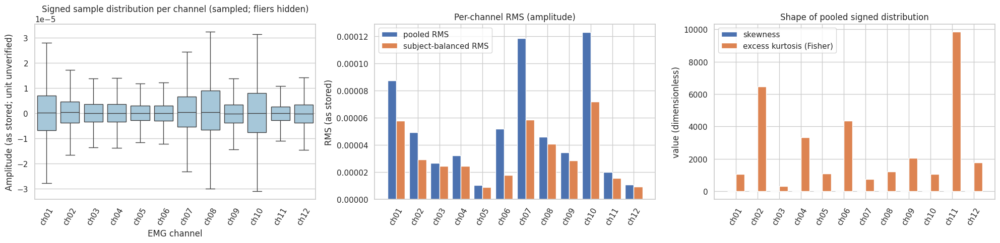


--- Reading of the figure/table ---
WHAT IS SHOWN       : Left: spread of signed samples per channel. Middle: RMS per channel (pooled vs equal subject weight). Right: skewness and Fisher excess kurtosis of the pooled signed samples.
OBSERVED (computed) : RMS ranges 1.05e-05-0.000123 across channels (max/min = 11.8); skewness range -7.68 to 2.94; excess kurtosis range 302.0 to 9845.6.
WHY IT MAY MATTER   : Large between-channel scale ratios or kurtosis >> 0 (heavy tails: rest vs burst activity) can destabilise unnormalised training and make plain z-scoring dominated by rare bursts. (hypothesis)
CANNOT BE CONCLUDED : Differences in scale do not tell which channels are more informative; heavy tails here are not proof of artifacts (muscle bursts are expected to be heavy-tailed). 

[B] Pooled per-channel RMS max/min ratio = 11.8; excess kurtosis range 302.0..9845.6; skewness range -7.68..2.94.


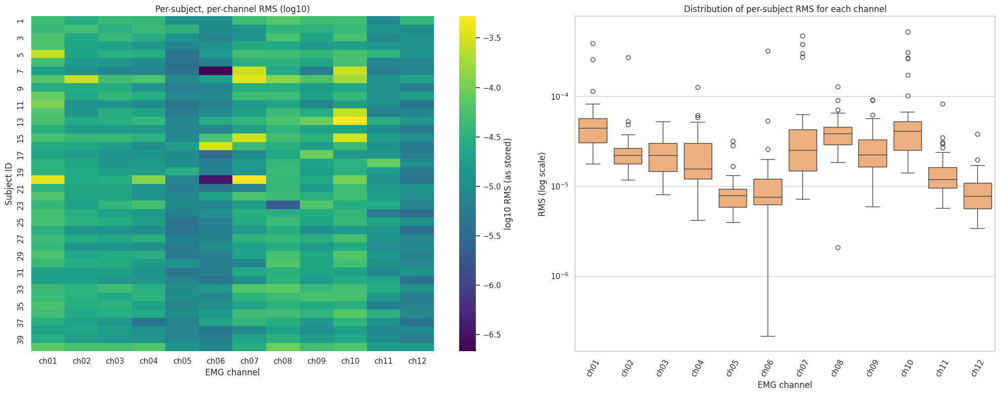


--- Reading of the figure/table ---
WHAT IS SHOWN       : Rows = subjects, columns = channels; colour = log10 of the subject's RMS on that channel (all exercises pooled). Right: spread across subjects per channel.
OBSERVED (computed) : Max/min RMS across subjects per channel: median 22.5 (range 6.4-1485.9); coefficient of variation across subjects per channel: median 0.85.
WHY IT MAY MATTER   : Subject-specific scale differences are a candidate source of cross-subject distribution shift; they motivate per-channel scaling fitted on training subjects (or subject-level normalisation as an experimental factor). (hypothesis)
CANNOT BE CONCLUDED : Scale differences may reflect electrode placement, skin impedance or genuine strength differences - EDA cannot separate these, and cannot say how much they hurt unseen-subject accuracy. 

[B] Subject-to-subject RMS spread per channel: median max/min = 22.5; median CV = 0.85 (evidence of subject-level scale differences relevant to Objective 2).


In [10]:
# B visualisations
fig, ax = plt.subplots(1, 3, figsize=(20, 5))
sns.boxplot(data=samp_df[CH], ax=ax[0], showfliers=False, color="#9ecae1"); ax[0].set_title("Signed sample distribution per channel (sampled; fliers hidden)")
ax[0].set_xlabel("EMG channel"); ax[0].set_ylabel("Amplitude (as stored; unit unverified)"); ax[0].tick_params(axis="x", rotation=60)
x = np.arange(C); ax[1].bar(x - .2, B1["rms"].values, .4, label="pooled RMS"); ax[1].bar(x + .2, B2_bal["rms_subj_balanced"].values, .4, label="subject-balanced RMS")
ax[1].set_xticks(x); ax[1].set_xticklabels(CH, rotation=60); ax[1].set_title("Per-channel RMS (amplitude)"); ax[1].set_ylabel("RMS (as stored)"); ax[1].legend()
ax[2].bar(x - .2, B1["skew"].values, .4, label="skewness"); ax[2].bar(x + .2, B1["kurt_excess"].values, .4, label="excess kurtosis (Fisher)")
ax[2].set_xticks(x); ax[2].set_xticklabels(CH, rotation=60); ax[2].set_title("Shape of pooled signed distribution"); ax[2].set_ylabel("value (dimensionless)"); ax[2].legend()
fig.tight_layout(); savefig(fig, "B_channel_summaries")
rmsr = B1["rms"].max() / B1["rms"].min()
interpret("Left: spread of signed samples per channel. Middle: RMS per channel (pooled vs equal subject weight). Right: skewness and Fisher excess kurtosis of the pooled signed samples.",
          f"RMS ranges {B1['rms'].min():.3g}-{B1['rms'].max():.3g} across channels (max/min = {rmsr:.1f}); skewness range {B1['skew'].min():.2f} to {B1['skew'].max():.2f}; excess kurtosis range {B1['kurt_excess'].min():.1f} to {B1['kurt_excess'].max():.1f}.",
          "Large between-channel scale ratios or kurtosis >> 0 (heavy tails: rest vs burst activity) can destabilise unnormalised training and make plain z-scoring dominated by rare bursts.",
          "Differences in scale do not tell which channels are more informative; heavy tails here are not proof of artifacts (muscle bursts are expected to be heavy-tailed).")
note("B", f"Pooled per-channel RMS max/min ratio = {rmsr:.1f}; excess kurtosis range {B1['kurt_excess'].min():.1f}..{B1['kurt_excess'].max():.1f}; skewness range {B1['skew'].min():.2f}..{B1['skew'].max():.2f}.")

#subject x channel RMS
piv = B2.pivot(index="subject", columns="channel", values="rms")
fig, ax = plt.subplots(1, 2, figsize=(20, 8), gridspec_kw={"width_ratios": [1.2, 1]})
sns.heatmap(np.log10(piv), cmap="viridis", ax=ax[0], cbar_kws={"label": "log10 RMS (as stored)"}); ax[0].set_title("Per-subject, per-channel RMS (log10)"); ax[0].set_ylabel("Subject ID"); ax[0].set_xlabel("EMG channel")
sns.boxplot(data=piv, ax=ax[1], color="#fdae6b"); ax[1].set_yscale("log"); ax[1].set_title("Distribution of per-subject RMS for each channel"); ax[1].set_ylabel("RMS (log scale)"); ax[1].set_xlabel("EMG channel"); ax[1].tick_params(axis="x", rotation=60)
fig.tight_layout(); savefig(fig, "B_subject_channel_rms")
subj_ratio = (piv.max() / piv.min()); cv = (piv.std() / piv.mean())
interpret("Rows = subjects, columns = channels; colour = log10 of the subject's RMS on that channel (all exercises pooled). Right: spread across subjects per channel.",
          f"Max/min RMS across subjects per channel: median {subj_ratio.median():.1f} (range {subj_ratio.min():.1f}-{subj_ratio.max():.1f}); coefficient of variation across subjects per channel: median {cv.median():.2f}.",
          "Subject-specific scale differences are a candidate source of cross-subject distribution shift; they motivate per-channel scaling fitted on training subjects (or subject-level normalisation as an experimental factor).",
          "Scale differences may reflect electrode placement, skin impedance or genuine strength differences - EDA cannot separate these, and cannot say how much they hurt unseen-subject accuracy.")
note("B", f"Subject-to-subject RMS spread per channel: median max/min = {subj_ratio.median():.1f}; median CV = {cv.median():.2f} (evidence of subject-level scale differences relevant to Objective 2).")

# SECTION C — Data-quality assessment
Thresholds are configurable in `CFG` and reported next to every flag. **Nothing is removed, clipped or relabelled** by this notebook.

In [11]:
#C1 Missing values
tot_vals = n_total * C
C1_file = file_df[["file", "subject", "exercise", "n_samples", "n_nan", "n_inf", "n_invalid_rows", "missing_vars", "meta_issues"]].copy()
C1_file["pct_values_invalid"] = (C1_file.n_nan + C1_file.n_inf) / (C1_file.n_samples * C) * 100
C1_chan = pd.DataFrame({"channel": CH, "n_nan": chan["nan_c"].sum(0), "n_inf": chan["inf_c"].sum(0)}); C1_chan["pct"] = (C1_chan.n_nan + C1_chan.n_inf) / n_total * 100
C1_subj = file_df.groupby("subject")[["n_nan", "n_inf", "n_invalid_rows", "n_samples"]].sum(); C1_subj["pct_rows_invalid"] = C1_subj.n_invalid_rows / C1_subj.n_samples * 100
miss_meta = pd.Series({v: int((~inv.var_names.str.contains(v)).sum()) for v in REQ_VARS + ["acc", "glove", "force", "forcecal"]}, name="n_files_without_variable")
save_table(C1_file, "C1_missing_by_file"); save_table(C1_chan, "C1_missing_by_channel"); save_table(C1_subj.reset_index(), "C1_missing_by_subject")
print(f"Invalid EMG values (NaN+Inf): {int(C1_chan.n_nan.sum() + C1_chan.n_inf.sum()):,} of {tot_vals:,} ({(C1_chan.n_nan.sum() + C1_chan.n_inf.sum()) / tot_vals * 100:.6f}%)")
print("Missing METADATA (variables absent from files):"); display(miss_meta.to_frame())
print("Files with metadata inconsistencies:", int((file_df.meta_issues != "").sum()), "| files lacking a required variable:", int((file_df.missing_vars != "").sum()))
if (C1_file.n_nan + C1_file.n_inf).sum() > 0:
    display(C1_file.sort_values("pct_values_invalid", ascending=False).head(10)); display(C1_chan); display(C1_subj.sort_values("n_invalid_rows", ascending=False).head(5))
inv_total = int(C1_chan.n_nan.sum() + C1_chan.n_inf.sum())
note("C1", f"Invalid EMG values: {inv_total:,} ({inv_total / tot_vals * 100:.6f}% of {tot_vals:,}). Files with missing required metadata variables: {int((file_df.missing_vars != '').sum())}; with metadata inconsistencies: {int((file_df.meta_issues != '').sum())}.")
print("Handling options (if any were found): short NaN gaps -> exclude affected windows (this notebook already excludes windows containing non-finite samples from window sampling and counts); long gaps -> drop the segment but record it; never interpolate silently.")

Invalid EMG values (NaN+Inf): 0 of 2,492,553,840 (0.000000%)
Missing METADATA (variables absent from files):


,n_files_without_variable
emg,0
stimulus,0
restimulus,0
repetition,0
rerepetition,0
subject,0
exercise,0
acc,0
glove,40
force,80


Files with metadata inconsistencies: 18 | files lacking a required variable: 0
[C1] Invalid EMG values: 0 (0.000000% of 2,492,553,840). Files with missing required metadata variables: 0; with metadata inconsistencies: 18.
Handling options (if any were found): short NaN gaps -> exclude affected windows (this notebook already excludes windows containing non-finite samples from window sampling and counts); long gaps -> drop the segment but record it; never interpolate silently.


In [12]:
#C2 Duplicates
C2 = {}
fm = file_df.groupby("md5").file.apply(list); C2["identical_files"] = [v for v in fm if len(v) > 1]
meta_key_dups = file_df.duplicated(["subject", "exercise"], keep=False).sum()
cand = seg_df[(~seg_df.is_rest) & (seg_df.length >= W) & (seg_df.n_unique_vals > 1)]
dup_seg = cand[cand.duplicated("md5", keep=False)].sort_values("md5")
C2_rows = file_df[["file", "n_samples", "n_dup_rows", "frac_repeat_allch", "longest_flat_run_allch"]].copy(); C2_rows["pct_dup_rows"] = C2_rows.n_dup_rows / C2_rows.n_samples * 100
save_table(C2_rows, "C2_duplicates_by_file"); save_table(dup_seg.drop(columns=[c for c in seg_df.columns if c.split("_")[0] in FEATS]), "C2_duplicated_segments")
print(f"Identical files (same EMG bytes): {len(C2['identical_files'])} groups {C2['identical_files'][:5]}")
print(f"Duplicated (subject, exercise) metadata keys: {int(meta_key_dups)}")
print(f"Exact duplicate EMG rows (all 12 channels identical to an earlier row): {int(C2_rows.n_dup_rows.clip(lower=0).sum()):,} ({C2_rows.n_dup_rows.clip(lower=0).sum() / n_total * 100:.4f}% of samples)")
print(f"Longest run of identical consecutive 12-channel samples (flat line): {int(file_df.longest_flat_run_allch.max())} samples ({file_df.longest_flat_run_allch.max() / FS * 1000:.1f} ms) in {file_df.loc[file_df.longest_flat_run_allch.idxmax(), 'file']}")
print(f"Non-rest segments (>= one window long) with byte-identical content to another segment: {len(dup_seg)} segments in {dup_seg.md5.nunique()} groups")
if len(dup_seg): display(dup_seg[["file_id", "subject", "exercise", "class_key", "rerep", "start", "length", "md5"]].head(10))
note("C2", f"Identical files: {len(C2['identical_files'])} groups; duplicate (subject,exercise) keys: {int(meta_key_dups)}; exact duplicate rows: {int(C2_rows.n_dup_rows.clip(lower=0).sum()):,}; duplicated non-rest segments: {len(dup_seg)}.")
print("Interpretation guide: repeated *values* inside a continuous signal are legitimate (quantised ADC output); duplicated *records* (identical files/segments) would be a data-handling problem. Removal is justified only for byte-identical files/segments that appear in different subject/gesture slots; it is NOT done automatically.")

Identical files (same EMG bytes): 0 groups []
Duplicated (subject, exercise) metadata keys: 0
Exact duplicate EMG rows (all 12 channels identical to an earlier row): 0 (0.0000% of samples)
Longest run of identical consecutive 12-channel samples (flat line): 0 samples (0.0 ms) in S1_E1_A1.mat
Non-rest segments (>= one window long) with byte-identical content to another segment: 0 segments in 0 groups
[C2] Identical files: 0 groups; duplicate (subject,exercise) keys: 0; exact duplicate rows: 0; duplicated non-rest segments: 0.
Interpretation guide: repeated *values* inside a continuous signal are legitimate (quantised ADC output); duplicated *records* (identical files/segments) would be a data-handling problem. Removal is justified only for byte-identical files/segments that appear in different subject/gesture slots; it is NOT done automatically.


In [13]:
#C3 Near-constant channels
med_std = np.median(chan["std"], axis=0)
rel = chan["std"] / med_std
flag_const = (rel < CFG["NEAR_CONST_REL"]) | (chan["std"] == 0) | (chan["frac_repeat_c"] > CFG["REPEAT_FRAC_THR"])
idx = np.argwhere(flag_const)
C3 = pd.DataFrame([dict(file=file_df.file[i], subject=file_df.subject[i], exercise=file_df.exercise[i], channel=CH[j], std=chan["std"][i, j],
                        std_rel_to_channel_median=rel[i, j], frac_repeated_consecutive=chan["frac_repeat_c"][i, j]) for i, j in idx])
save_table(C3, "C3_near_constant_file_channels")
print(f"Rules: std < {CFG['NEAR_CONST_REL']:.0%} of the channel's median per-file std, OR std == 0, OR > {CFG['REPEAT_FRAC_THR']:.0%} of consecutive samples identical. Flagged file-channels: {len(C3)} of {flag_const.size}")
rel_tab = pd.DataFrame({"channel": CH, "median_file_std": med_std, "min_rel_std": rel.min(0), "max_rel_std": rel.max(0), "max_frac_repeated": chan["frac_repeat_c"].max(0)}); display(rel_tab)
if len(C3): display(C3.head(15))
note("C3", f"Near-constant file-channels (thresholds above): {len(C3)}; lowest relative std observed = {rel.min():.3f} of channel median; max repeated-sample fraction = {chan['frac_repeat_c'].max():.3f}.")
print("A flagged channel could mean an inactive/detached electrode, a recording fault or genuinely low activity; EDA cannot tell which. Keep the channel as a graph node (the node set must stay fixed across subjects) and record the flag.")

Rules: std < 1% of the channel's median per-file std, OR std == 0, OR > 50% of consecutive samples identical. Flagged file-channels: 1 of 1440


,channel,median_file_std,min_rel_std,max_rel_std,max_frac_repeated
0,ch01,0.000040,0.260036,11.746539,0.009771
1,ch02,0.000022,0.382892,17.069708,0.003207
2,ch03,0.000022,0.219462,4.480593,0.044816
3,ch04,0.000016,0.210823,10.452973,0.000495
4,ch05,0.000007,0.411506,5.572575,0.000367
5,ch06,0.000007,0.021020,58.431126,0.001289
6,ch07,0.000021,0.153391,28.617416,0.000041
7,ch08,0.000037,0.008609,5.118296,0.000717
8,ch09,0.000023,0.200903,5.276163,0.009885
9,ch10,0.000033,0.212716,18.346103,0.016793


,file,subject,exercise,channel,std,std_rel_to_channel_median,frac_repeated_consecutive
0,S23_E2_A1.mat,23,2,ch08,3.166849e-07,0.008609,0.000045


[C3] Near-constant file-channels (thresholds above): 1; lowest relative std observed = 0.009 of channel median; max repeated-sample fraction = 0.045.
A flagged channel could mean an inactive/detached electrode, a recording fault or genuinely low activity; EDA cannot tell which. Keep the channel as a graph node (the node set must stay fixed across subjects) and record the flag.


In [14]:
#correlation helpers (used in C4 and F)
def pooled_stats(subjects=None, classes=None):
    n = 0; s1 = 0; xx = 0
    for r in res:
        if subjects is not None and r["info"]["subject_fn"] not in subjects: continue
        keys = ["ALL"] if classes is None else [k for k in r["cstats"] if k in classes]
        for k in keys:
            if k in r["cstats"]:
                a, b, c = r["cstats"][k]; n += a; s1 = s1 + b; xx = xx + c
    return n, s1, xx

def pearson_from_stats(n, s1, xx):
    # exact Pearson matrix from sufficient statistics (pooled over the selected samples)
    if n < 3: return np.full((C, C), np.nan)
    mu = s1 / n; cov = xx / n - np.outer(mu, mu); sd = np.sqrt(np.diag(cov))
    with np.errstate(all="ignore"): return np.clip(cov / np.outer(sd, sd), -1, 1)

def top_pairs(M, thr, names=CH):
    iu = np.triu_indices_from(M, 1); v = M[iu]
    df = pd.DataFrame({"ch_a": [names[i] for i in iu[0]], "ch_b": [names[j] for j in iu[1]], "r": v, "abs_r": np.abs(v)})
    return df[df.abs_r >= thr].sort_values("abs_r", ascending=False)

R_raw_all = pearson_from_stats(*pooled_stats())                      # descriptive (all subjects)
R_raw_train = pearson_from_stats(*pooled_stats(TRAIN))               # leakage-safe (train subjects only)
pairs_all = top_pairs(R_raw_all, CFG["CORR_THR"])
save_table(pairs_all, "C4_high_corr_pairs_raw_all_subjects")
print(f"C4. Channel-to-channel Pearson r on RAW signed samples (pooled; exact). Pairs with |r| >= {CFG['CORR_THR']}: {len(pairs_all)}")
display(pairs_all if len(pairs_all) else pd.DataFrame({"result": ["no pair reaches the threshold"]}))
off = R_raw_all[np.triu_indices(C, 1)]
note("C4", f"Raw-signal channel correlations (pooled, all subjects): |r| median {np.median(np.abs(off)):.3f}, max {np.nanmax(np.abs(off)):.3f}; pairs with |r| >= {CFG['CORR_THR']}: {len(pairs_all)}. Window-RMS-envelope correlations are analysed in Section F.")
print("Channels are NOT removed: correlated electrodes can carry exactly the relational information a correlation-based graph uses. Correlation = statistical association, not a physiological connection.")

C4. Channel-to-channel Pearson r on RAW signed samples (pooled; exact). Pairs with |r| >= 0.9: 0


,result
0,no pair reaches the threshold


[C4] Raw-signal channel correlations (pooled, all subjects): |r| median 0.007, max 0.176; pairs with |r| >= 0.9: 0. Window-RMS-envelope correlations are analysed in Section F.
Channels are NOT removed: correlated electrodes can carry exactly the relational information a correlation-based graph uses. Correlation = statistical association, not a physiological connection.


In [15]:
#C5 Outliers
Xs = samp_df[CH]
q1, q3 = Xs.quantile(.25), Xs.quantile(.75); iqr = q3 - q1
lo, hi = q1 - 1.5 * iqr, q3 + 1.5 * iqr
out_iqr = ((Xs < lo) | (Xs > hi))
med = Xs.median(); mad = (Xs - med).abs().median() * 1.4826
rz = (Xs - med) / mad; out_rz = rz.abs() > CFG["ROBUST_Z"]
active = (samp_df.label > 0).values
C5 = pd.DataFrame({"channel": CH, "pct_outside_IQR_fences": out_iqr.mean().values * 100, "pct_robust_z_gt_thr": out_rz.mean().values * 100,
                   "max_abs_robust_z": rz.abs().max().values,
                   "pct_of_IQR_outliers_in_active_samples": [100 * (out_iqr[c].values & active).sum() / max(1, out_iqr[c].sum()) for c in CH]})
C5["pct_samples_active_overall"] = active.mean() * 100
save_table(C5, "C5_outliers_sample_level")
print(f"C5a. Sample-level outliers (IQR 1.5x fences; robust z > {CFG['ROBUST_Z']} using median/MAD) on the stratified random sample ({len(samp_df):,} samples)"); display(C5)

# C5b segment-level amplitude outliers within subject-exercise
nr = nonrest.copy(); nr["logRMS"] = np.log(nr.RMS_meanch + 1e-12)
g = nr.groupby(["subject", "exercise"]).logRMS
nr["rz"] = (nr.logRMS - g.transform("median")) / (g.transform(lambda s: (s - s.median()).abs().median()) * 1.4826 + 1e-12)
seg_out = nr[nr.rz.abs() > CFG["ROBUST_Z"]]
save_table(seg_out[["file_id", "subject", "exercise", "class_key", "rerep", "start", "length", "RMS_meanch", "rz"]], "C5_outlier_segments")
print(f"C5b. Non-rest segments whose mean-channel RMS is a robust-z outlier within its (subject, exercise): {len(seg_out)} of {len(nr)} ({len(seg_out) / len(nr):.2%})")

# C5c saturation / clipping signature
sat = chan["frac_at_max_c"] + chan["frac_at_min_c"]
idx = np.argwhere(sat > CFG["SAT_FRAC_THR"])
C5c = pd.DataFrame([dict(file=file_df.file[i], subject=file_df.subject[i], exercise=file_df.exercise[i], channel=CH[j], frac_at_extremes=sat[i, j]) for i, j in idx])
save_table(C5c, "C5_saturation_flags")
print(f"C5c. File-channels with > {CFG['SAT_FRAC_THR']:.1%} of samples exactly at the file's max or min value (clipping signature): {len(C5c)}; typical value for non-clipping channels = {np.median(sat):.2e}")
if len(C5c): display(C5c.sort_values("frac_at_extremes", ascending=False).head(10))
interpret("Share of sampled values outside the IQR fences or robust-z threshold, per channel, and where they occur (rest vs active).",
          f"IQR-outlier share per channel {C5.pct_outside_IQR_fences.min():.2f}-{C5.pct_outside_IQR_fences.max():.2f}%; of those, {C5.pct_of_IQR_outliers_in_active_samples.median():.0f}% (median over channels) fall in active samples although active samples are {active.mean() * 100:.0f}% of the sample; {len(C5c)} file-channels show a clipping signature.",
          "If outliers concentrate in active samples they are more consistent with genuine contraction bursts than with random artifacts; clipping would be a recording limitation.",
          "Statistical outliers are not shown to be errors. Removal/clipping would delete real high-effort muscle activity and bias features such as RMS; retention (with robust or per-channel scaling) is the default recommendation unless clipping or non-finite values are shown.")
note("C5", f"Sample-level IQR outliers per channel: {C5.pct_outside_IQR_fences.min():.2f}-{C5.pct_outside_IQR_fences.max():.2f}%; {C5.pct_of_IQR_outliers_in_active_samples.median():.0f}% of them in active samples (active share {active.mean() * 100:.0f}%); outlier segments {len(seg_out)}; clipping-signature file-channels {len(C5c)}.")

C5a. Sample-level outliers (IQR 1.5x fences; robust z > 3.5 using median/MAD) on the stratified random sample (480,000 samples)


,channel,pct_outside_IQR_fences,pct_robust_z_gt_thr,max_abs_robust_z,pct_of_IQR_outliers_in_active_samples,pct_samples_active_overall
0,ch01,18.511250,14.542500,605.718323,78.275598,56.530833
1,ch02,16.580208,12.807708,900.958496,85.213294,56.530833
2,ch03,16.741042,13.580625,411.236420,88.103090,56.530833
3,ch04,15.245417,12.063542,954.808594,84.931263,56.530833
4,ch05,8.127292,5.182708,284.212494,86.142370,56.530833
5,ch06,10.324167,7.107292,1661.568237,76.402454,56.530833
6,ch07,17.211875,13.542083,957.991333,75.547405,56.530833
7,ch08,17.705417,13.502292,477.352844,81.696985,56.530833
8,ch09,16.130417,13.060417,1019.790222,87.703097,56.530833
9,ch10,17.707708,13.519167,924.508362,76.936833,56.530833


C5b. Non-rest segments whose mean-channel RMS is a robust-z outlier within its (subject, exercise): 108 of 11760 (0.92%)
C5c. File-channels with > 0.1% of samples exactly at the file's max or min value (clipping signature): 0; typical value for non-clipping channels = 1.11e-06

--- Reading of the figure/table ---
WHAT IS SHOWN       : Share of sampled values outside the IQR fences or robust-z threshold, per channel, and where they occur (rest vs active).
OBSERVED (computed) : IQR-outlier share per channel 8.13-18.51%; of those, 82% (median over channels) fall in active samples although active samples are 57% of the sample; 0 file-channels show a clipping signature.
WHY IT MAY MATTER   : If outliers concentrate in active samples they are more consistent with genuine contraction bursts than with random artifacts; clipping would be a recording limitation. (hypothesis)
CANNOT BE CONCLUDED : Statistical outliers are not shown to be errors. Removal/clipping would delete real high-effort musc

In [16]:
# C6 Modeling-impact summary (every row is generated from the evidence computed above)
cw = nonrest.groupby("class_key").n_win_valid.sum(); imb = cw.max() / max(cw.min(), 1) if len(cw) else np.nan
act_share = (seg_df.loc[~seg_df.is_rest, "length"].sum() / seg_df.length.sum())
def row(issue, evidence, effect, handling, risk, present=True):
    return dict(issue=issue, evidence=evidence if present else "No instance under the configured thresholds: " + evidence, effect=effect, handling=handling if present else "No action needed beyond keeping the check in the pipeline", risk=risk)
C6 = pd.DataFrame([
 row("Invalid EMG samples (NaN/Inf)", f"{inv_total:,} invalid values", "NaNs propagate through normalisation/loss and produce NaN weights", "Exclude affected windows (already done here), record counts; do not interpolate silently", "Silent NaN losses or corrupted batch statistics", inv_total > 0),
 row("Missing/inconsistent metadata", f"{int((file_df.missing_vars != '').sum())} files lack required variables; {int((file_df.meta_issues != '').sum())} inconsistent", "Wrong subject/exercise/repetition grouping leaks data across splits", "Fix or exclude the affected files explicitly and log them", "Leakage or mislabelled groups", bool((file_df.missing_vars != '').any() or (file_df.meta_issues != '').any())),
 row("Duplicated records", f"{len(C2['identical_files'])} identical-file groups; {len(dup_seg)} duplicated segments", "Identical data in train and test inflates accuracy", "Investigate; keep only one copy if confirmed duplicates in different slots", "Optimistic test accuracy", bool(len(C2['identical_files']) or len(dup_seg))),
 row("Near-constant / stuck channels", f"{len(C3)} flagged file-channels", "Dead graph node; scaling by ~0 std explodes values", "Keep the node but guard scaling (std floor); log affected subjects", "Division by ~0, unstable training", bool(len(C3))),
 row("Strongly correlated channels", f"{len(pairs_all)} raw pairs with |r|>={CFG['CORR_THR']}", "Redundant information; dense correlation graph", "Do not drop channels automatically; study via graph/threshold experiments (train subjects only)", "Missing relational structure if removed blindly", bool(len(pairs_all))),
 row("Heavy-tailed amplitudes / outliers", f"excess kurtosis up to {B1['kurt_excess'].max():.1f}; IQR outliers up to {C5.pct_outside_IQR_fences.max():.1f}%/channel", "Mean/std scaling dominated by bursts; unstable gradients", "Keep outliers; use per-channel scaling fitted on training subjects, optionally robust scaling or amplitude-compressing transform as an experimental factor", "Bad scaling or removal of true bursts", bool(B1['kurt_excess'].max() > 3)),
 row("Saturation / clipping signature", f"{len(C5c)} flagged file-channels", "Clipped peaks distort amplitude features", "Report subject list; evaluate sensitivity", "Subject-specific artefacts", bool(len(C5c))),
 row("Subject scale differences", f"per-channel RMS max/min across subjects: median {subj_ratio.median():.1f}", "Distribution shift between subjects (Objective 2)", "Per-channel scaling from training subjects; test subject-level normalisation as a separate experiment", "Poor cross-subject generalisation", bool(subj_ratio.median() > 1.5)),
 row("Class imbalance", f"window imbalance ratio (max/min over non-rest classes) = {imb:.2f}; non-rest share of samples {act_share:.1%}", "Accuracy dominated by frequent classes/rest", "Report Macro-F1 + per-class metrics; test class weighting in training only", "Misleading accuracy", bool(imb > 1.5 or act_share < 0.5)),
])
save_table(C6, "C6_modeling_impact_summary")
with pd.option_context("display.max_colwidth", 120): display(C6)

,issue,evidence,effect,handling,risk
0,Invalid EMG samples (NaN/Inf),No instance under the configured thresholds: 0 invalid values,NaNs propagate through normalisation/loss and produce NaN weights,No action needed beyond keeping the check in the pipeline,Silent NaN losses or corrupted batch statistics
1,Missing/inconsistent metadata,0 files lack required variables; 18 inconsistent,Wrong subject/exercise/repetition grouping leaks data across splits,Fix or exclude the affected files explicitly and log them,Leakage or mislabelled groups
2,Duplicated records,No instance under the configured thresholds: 0 identical-file groups; 0 duplicated segments,Identical data in train and test inflates accuracy,No action needed beyond keeping the check in the pipeline,Optimistic test accuracy
3,Near-constant / stuck channels,1 flagged file-channels,Dead graph node; scaling by ~0 std explodes values,Keep the node but guard scaling (std floor); log affected subjects,"Division by ~0, unstable training"
4,Strongly correlated channels,No instance under the configured thresholds: 0 raw pairs with |r|>=0.9,Redundant information; dense correlation graph,No action needed beyond keeping the check in the pipeline,Missing relational structure if removed blindly
5,Heavy-tailed amplitudes / outliers,excess kurtosis up to 9845.6; IQR outliers up to 18.5%/channel,Mean/std scaling dominated by bursts; unstable gradients,"Keep outliers; use per-channel scaling fitted on training subjects, optionally robust scaling or amplitude-compressi...",Bad scaling or removal of true bursts
6,Saturation / clipping signature,No instance under the configured thresholds: 0 flagged file-channels,Clipped peaks distort amplitude features,No action needed beyond keeping the check in the pipeline,Subject-specific artefacts
7,Subject scale differences,per-channel RMS max/min across subjects: median 22.5,Distribution shift between subjects (Objective 2),Per-channel scaling from training subjects; test subject-level normalisation as a separate experiment,Poor cross-subject generalisation
8,Class imbalance,window imbalance ratio (max/min over non-rest classes) = 1.85; non-rest share of samples 56.1%,Accuracy dominated by frequent classes/rest,Report Macro-F1 + per-class metrics; test class weighting in training only,Misleading accuracy


# SECTION D — Class-balance analysis
Class = E<exercise>_G<label> (non-rest) from the refined label restimulus; the rest label is listed separately because it dominates sample counts. Counts are given for raw samples, segments (one repetition instance), repetitions, and derived windows (windows are overlapping and dependent — useful for relative balance, not as independent sample sizes).

,class_key,exercise,label,n_files,n_subjects,n_segments,n_repetition_ids,n_samples,n_windows,is_rest,pct_samples,pct_windows,pct_samples_nonrest,pct_windows_nonrest
0,E1_REST,1,0,40,40,4120,7,34152630,1627564,True,16.442235,16.394456,NaN,NaN
1,E1_G01,1,1,40,40,240,6,2929471,141805,False,1.410347,1.428402,2.514509,2.533632
2,E1_G02,1,2,40,40,240,6,2564923,123583,False,1.234841,1.244852,2.201600,2.208059
3,E1_G03,1,3,40,40,240,6,2254571,108069,False,1.085427,1.088579,1.935209,1.930870
4,E1_G04,1,4,40,40,240,6,2198294,105253,False,1.058333,1.060214,1.886904,1.880557
5,E1_G05,1,5,40,40,240,6,2171690,103919,False,1.045525,1.046776,1.864069,1.856722
6,E1_G06,1,6,40,40,240,6,1897020,90187,False,0.913290,0.908454,1.628306,1.611372
7,E1_G07,1,7,40,40,240,6,2762115,133440,False,1.329776,1.344141,2.370860,2.384174
8,E1_G08,1,8,40,40,240,6,2161793,103427,False,1.040761,1.041820,1.855574,1.847932
9,E1_G09,1,9,40,40,240,6,2344760,112575,False,1.128847,1.133968,2.012623,2.011379


Majority non-rest class (windows): E2_G34 (145,362); minority: E1_G14 (78,678)
Imbalance ratio max/min among non-rest classes: samples 1.80 | windows 1.85 | segments 1.00; REST share of all samples = 43.9%
[D] 49 non-rest classes; imbalance ratio (max/min): samples 1.80, windows 1.85, segments 1.00; REST = 43.9% of samples.


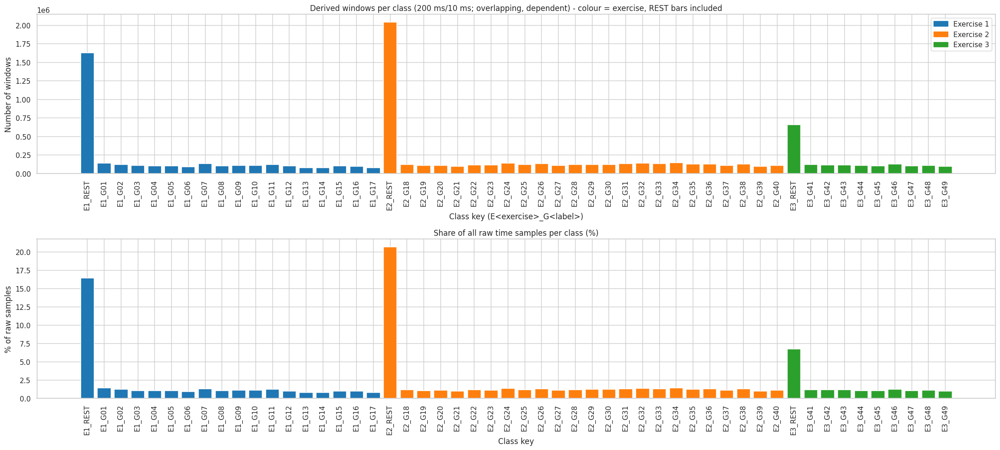


--- Reading of the figure/table ---
WHAT IS SHOWN       : Window counts and raw-sample share per class, including the rest label of each exercise.
OBSERVED (computed) : Non-rest window imbalance ratio 1.85; rest = 43.9% of raw samples.
WHY IT MAY MATTER   : If rest or a few gestures dominate, accuracy can look high while minority gestures are missed; Macro-F1, per-class precision/recall and a confusion matrix are the safer metrics, and class weighting (or resampling inside training folds only) is worth testing during training. (hypothesis)
CANNOT BE CONCLUDED : Window counts are not independent sample sizes (95% overlap at 10 ms step); balance among segments/repetitions is the more honest measure of independent evidence. 



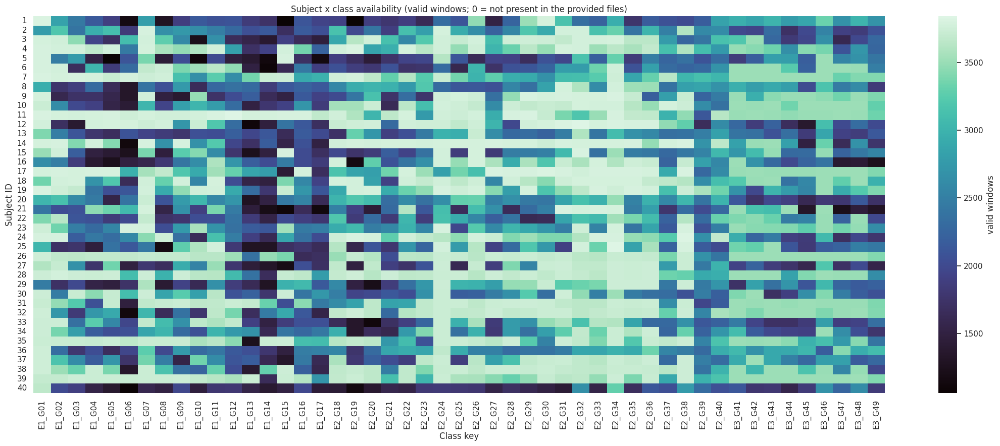

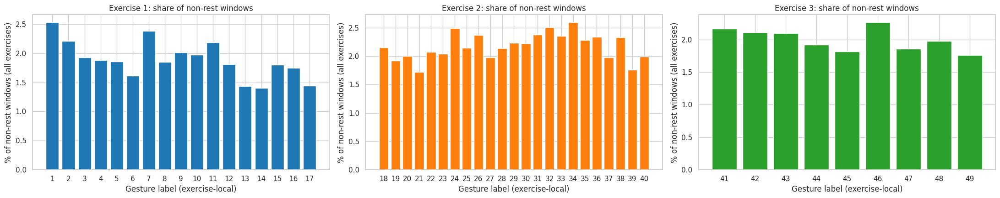

Subject-exercise files lacking at least one class that exists elsewhere: 0

--- Reading of the figure/table ---
WHAT IS SHOWN       : Heatmap cells are the number of valid windows of a class for a subject.
OBSERVED (computed) : 0 zero cells out of 1960; 0 subject-exercise files lack at least one class seen elsewhere; per-class subject counts range 40-40.
WHY IT MAY MATTER   : Unequal class availability across subjects changes what a subject-wise fold fold can measure and can make per-class cross-subject metrics undefined for some folds. (hypothesis)
CANNOT BE CONCLUDED : A class absent for one subject in these files is not proven absent from the full NinaPro DB2; it may be due to the provided subset. 



In [17]:
cls = seg_df.groupby("class_key").agg(exercise=("exercise", "first"), label=("label", "first"), n_files=("file_id", "nunique"), n_subjects=("subject", "nunique"),
                                       n_segments=("seg_uid", "size"), n_repetition_ids=("rerep", "nunique"), n_samples=("length", "sum"), n_windows=("n_win_valid", "sum")).reset_index()
cls["is_rest"] = cls.label == 0
cls["pct_samples"] = cls.n_samples / cls.n_samples.sum() * 100; cls["pct_windows"] = cls.n_windows / cls.n_windows.sum() * 100
nr_ = cls[~cls.is_rest]
cls["pct_samples_nonrest"] = np.where(cls.is_rest, np.nan, cls.n_samples / nr_.n_samples.sum() * 100)
cls["pct_windows_nonrest"] = np.where(cls.is_rest, np.nan, cls.n_windows / nr_.n_windows.sum() * 100)
cls = cls.sort_values(["exercise", "label"]).reset_index(drop=True)
save_table(cls, "class_balance")
display(cls)
imb_s = nr_.n_samples.max() / nr_.n_samples.min(); imb_w = nr_.n_windows.max() / max(nr_.n_windows.min(), 1)
imb_seg = nr_.n_segments.max() / nr_.n_segments.min()
rest_share_s = cls.loc[cls.is_rest, "n_samples"].sum() / cls.n_samples.sum()
print(f"Majority non-rest class (windows): {nr_.loc[nr_.n_windows.idxmax(), 'class_key']} ({nr_.n_windows.max():,}); minority: {nr_.loc[nr_.n_windows.idxmin(), 'class_key']} ({nr_.n_windows.min():,})")
print(f"Imbalance ratio max/min among non-rest classes: samples {imb_s:.2f} | windows {imb_w:.2f} | segments {imb_seg:.2f}; REST share of all samples = {rest_share_s:.1%}")
note("D", f"{len(nr_)} non-rest classes; imbalance ratio (max/min): samples {imb_s:.2f}, windows {imb_w:.2f}, segments {imb_seg:.2f}; REST = {rest_share_s:.1%} of samples.")

#figures
cmap = {1: "#1f77b4", 2: "#ff7f0e", 3: "#2ca02c"}
fig, ax = plt.subplots(2, 1, figsize=(22, 10))
col = [cmap.get(e, "grey") for e in cls.exercise]
ax[0].bar(cls.class_key, cls.n_windows, color=col); ax[0].set_title("Derived windows per class (200 ms/10 ms; overlapping, dependent) - colour = exercise, REST bars included")
ax[0].set_ylabel("Number of windows"); ax[0].set_xlabel("Class key (E<exercise>_G<label>)"); ax[0].tick_params(axis="x", rotation=90)
ax[0].legend(handles=[plt.Rectangle((0, 0), 1, 1, color=c) for c in cmap.values()], labels=[f"Exercise {e}" for e in cmap], loc="upper right")
ax[1].bar(cls.class_key, cls.pct_samples, color=col); ax[1].set_title("Share of all raw time samples per class (%)"); ax[1].set_ylabel("% of raw samples"); ax[1].set_xlabel("Class key"); ax[1].tick_params(axis="x", rotation=90)
fig.tight_layout(); savefig(fig, "D_class_counts_and_percentages")
interpret("Window counts and raw-sample share per class, including the rest label of each exercise.",
          f"Non-rest window imbalance ratio {imb_w:.2f}; rest = {rest_share_s:.1%} of raw samples.",
          "If rest or a few gestures dominate, accuracy can look high while minority gestures are missed; Macro-F1, per-class precision/recall and a confusion matrix are the safer metrics, and class weighting (or resampling inside training folds only) is worth testing during training.",
          "Window counts are not independent sample sizes (95% overlap at 10 ms step); balance among segments/repetitions is the more honest measure of independent evidence.")

# subject x class heatmap (non-rest, windows)
pv = seg_df[~seg_df.is_rest].pivot_table(index="subject", columns="class_key", values="n_win_valid", aggfunc="sum", fill_value=0)
fig, ax = plt.subplots(figsize=(22, 9))
sns.heatmap(pv, cmap="mako", ax=ax, cbar_kws={"label": "valid windows"}); ax.set_title("Subject x class availability (valid windows; 0 = not present in the provided files)")
ax.set_xlabel("Class key"); ax.set_ylabel("Subject ID"); fig.tight_layout(); savefig(fig, "D_subject_by_class_heatmap")

# exercise x class percentage
fig, ax = plt.subplots(1, len(cmap), figsize=(22, 4.5), sharey=False)
for a, e in zip(np.atleast_1d(ax), sorted(cls.exercise.unique())):
    d = cls[(cls.exercise == e) & ~cls.is_rest]; a.bar(d.label.astype(str), d.pct_windows_nonrest, color=cmap.get(e, "grey")); a.set_title(f"Exercise {e}: share of non-rest windows"); a.set_xlabel("Gesture label (exercise-local)"); a.set_ylabel("% of non-rest windows (all exercises)")
fig.tight_layout(); savefig(fig, "D_exercise_by_class")

# missing subject-class combinations (a combination missing here is only missing from the PROVIDED files)
universe = nr_.groupby("exercise").class_key.apply(set).to_dict()
miss = []
for (sj, ex), g in file_df.groupby(["subject", "exercise"]):
    have = set(seg_df[(seg_df.subject == sj) & (seg_df.exercise == ex) & ~seg_df.is_rest].class_key)
    lacking = sorted(universe.get(ex, set()) - have)
    if lacking: miss.append(dict(subject=sj, exercise=ex, n_missing=len(lacking), missing=",".join(lacking)))
missdf = pd.DataFrame(miss); save_table(missdf, "D_missing_subject_class_combinations")
print(f"Subject-exercise files lacking at least one class that exists elsewhere: {len(missdf)}"); 
if len(missdf): display(missdf.head(15))
interpret("Heatmap cells are the number of valid windows of a class for a subject.",
          f"{int((pv == 0).sum().sum())} zero cells out of {pv.size}; {len(missdf)} subject-exercise files lack at least one class seen elsewhere; per-class subject counts range {nr_.n_subjects.min()}-{nr_.n_subjects.max()}.",
          "Unequal class availability across subjects changes what a subject-wise fold fold can measure and can make per-class cross-subject metrics undefined for some folds.",
          "A class absent for one subject in these files is not proven absent from the full NinaPro DB2; it may be due to the provided subset.")

# SECTION E — Signal and feature distributions
Raw waveform distributions use the stratified random sample (SAMPLES_PER_FILE per file; seed in CFG). Handcrafted features (RMS, MAV, waveform length, zero crossings, variance) are computed per channel over one 200 ms window on the sampled windows (≤ WIN_CAP_PER_FILE_CLASS per file × class). Zero-crossing dead-band = ZC_EPS_FRAC × the file's channel std (a crossing counts only if consecutive samples change sign and differ by at least this band). Derived features are distinct from the raw channels.# 

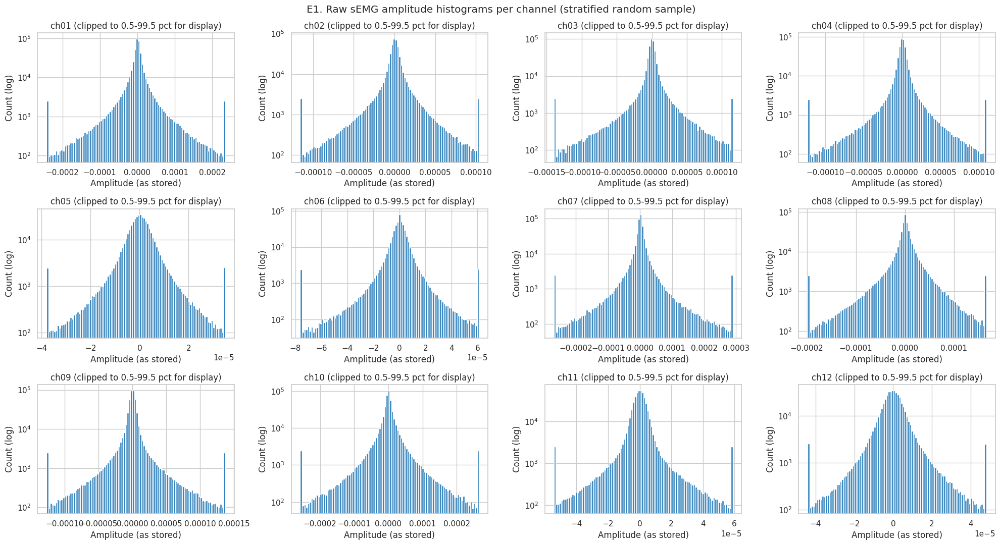

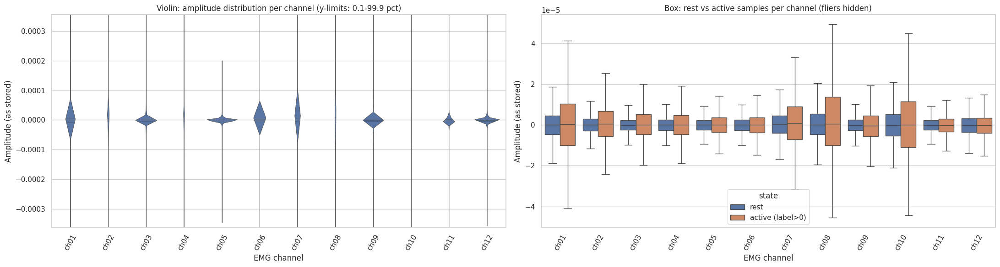


--- Reading of the figure/table ---
WHAT IS SHOWN       : Amplitude histograms (log counts), violins and rest-vs-active boxplots per channel.
OBSERVED (computed) : Mean |amplitude| active vs rest = 1.82e-05 vs 7.22e-06 (ratio 2.52); channel-wise skewness -7.68..2.94.
WHY IT MAY MATTER   : Zero-centred, heavy-tailed, channel-dependent distributions suggest per-channel scaling fitted on training data; the rest/active difference supports amplitude-type features as informative. (hypothesis)
CANNOT BE CONCLUDED : Histograms of pooled samples hide temporal structure and subject differences; no classification claim follows. 



In [18]:
#E1 raw distributions
fig, axs = plt.subplots(3, 4, figsize=(20, 11)); lo_, hi_ = samp_df[CH].quantile(.005), samp_df[CH].quantile(.995)
for a, c in zip(axs.ravel(), CH):
    a.hist(samp_df[c].clip(lo_[c], hi_[c]), bins=100, color="#3182bd", log=True); a.set_title(f"{c} (clipped to 0.5-99.5 pct for display)"); a.set_xlabel("Amplitude (as stored)"); a.set_ylabel("Count (log)")
fig.suptitle("E1. Raw sEMG amplitude histograms per channel (stratified random sample)"); fig.tight_layout(); savefig(fig, "E1_histograms")

vs = samp_df.sample(min(len(samp_df), 40000), random_state=SEED)[CH].melt(var_name="channel", value_name="amplitude")
fig, ax = plt.subplots(1, 2, figsize=(22, 6))
sns.violinplot(data=vs, x="channel", y="amplitude", ax=ax[0], cut=0, inner="quartile", linewidth=.6); ax[0].set_ylim(vs.amplitude.quantile(.001), vs.amplitude.quantile(.999)); ax[0].set_title("Violin: amplitude distribution per channel (y-limits: 0.1-99.9 pct)"); ax[0].set_ylabel("Amplitude (as stored)"); ax[0].set_xlabel("EMG channel"); ax[0].tick_params(axis="x", rotation=60)
sns.boxplot(data=samp_df.assign(state=np.where(samp_df.label > 0, "active (label>0)", "rest"))[CH + ["state"]].melt(id_vars="state", var_name="channel", value_name="amplitude"), x="channel", y="amplitude", hue="state", ax=ax[1], showfliers=False)
ax[1].set_title("Box: rest vs active samples per channel (fliers hidden)"); ax[1].set_ylabel("Amplitude (as stored)"); ax[1].set_xlabel("EMG channel"); ax[1].tick_params(axis="x", rotation=60)
fig.tight_layout(); savefig(fig, "E1_violin_box")
ra = samp_df.assign(a=np.abs(samp_df[CH].values).mean(1)).groupby(samp_df.label > 0).a.mean()
interpret("Amplitude histograms (log counts), violins and rest-vs-active boxplots per channel.",
          f"Mean |amplitude| active vs rest = {ra.get(True, np.nan):.3g} vs {ra.get(False, np.nan):.3g} (ratio {ra.get(True, np.nan) / ra.get(False, np.nan):.2f}); channel-wise skewness {B1["skew"].min():.2f}..{B1["skew"].max():.2f}.",
          "Zero-centred, heavy-tailed, channel-dependent distributions suggest per-channel scaling fitted on training data; the rest/active difference supports amplitude-type features as informative.",
          "Histograms of pooled samples hide temporal structure and subject differences; no classification claim follows.")

E2. Window-level handcrafted-feature descriptives (per channel; window = 400 samples; sampled windows N=16640)


mean                         50%                         std                    skew            kurt_excess             
                  min           max           min           max           min           max       min        max         min          max
feature                                                                                                                                  
MAV      6.389117e-06  4.373759e-05  3.530911e-06  2.088943e-05  7.047207e-06  1.231064e-04  3.696302  48.301034   28.503847  2789.793038
RMS      8.488239e-06  6.071218e-05  4.473680e-06  3.086747e-05  1.002126e-05  1.733217e-04  3.685656  42.037017   26.631068  2211.283758
VAR      1.720152e-10  3.356824e-08  1.991492e-11  9.520927e-10  8.138261e-10  4.194372e-07  0.000000  65.882866    0.000000  6828.201964
WL       1.020901e-03  7.138245e-03  6.259641e-04  4.279065e-03  1.075013e-03  1.851255e-02  3.907781  17.769619   26.426604   432.483833
ZC       4.857446e+01  5.814988e+01  4.900000e+01  5.800000e+01  1.244397e+01  2.027942e+01 -0.561271   1.396884   -0.679586     9.343512

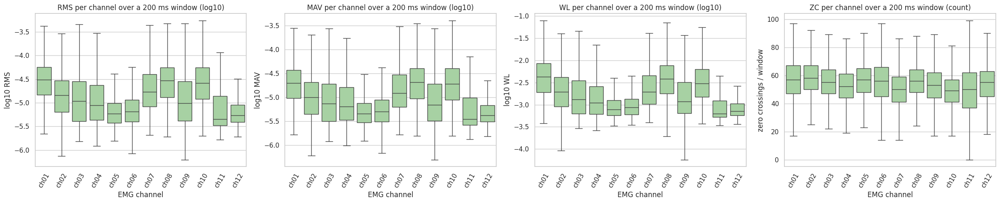


--- Reading of the figure/table ---
WHAT IS SHOWN       : Distribution of window-level handcrafted features for every channel (sampled windows).
OBSERVED (computed) : Median RMS ranges 4.47e-06-3.09e-05 across channels (ratio 6.9); median ZC per window 49-58.
WHY IT MAY MATTER   : Feature scales differ by orders of magnitude between feature types and between channels, so features must be standardised (fitted on training subjects) before being combined or compared. (hypothesis)
CANNOT BE CONCLUDED : These are sampled windows with class-capped sampling, not the full window population. 



,exercise,n_windows,eta2_class_incl_rest,eta2_class_nonrest,eta2_subject_nonrest
0,1,5760,0.161700,0.084851,0.374084
1,2,7680,0.150960,0.112395,0.424038
2,3,3200,0.148274,0.048311,0.474238


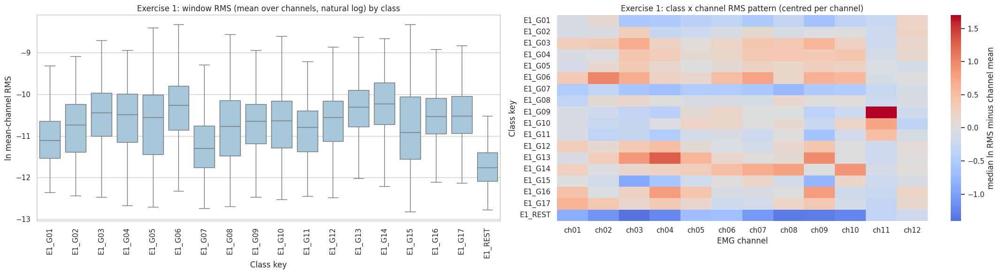

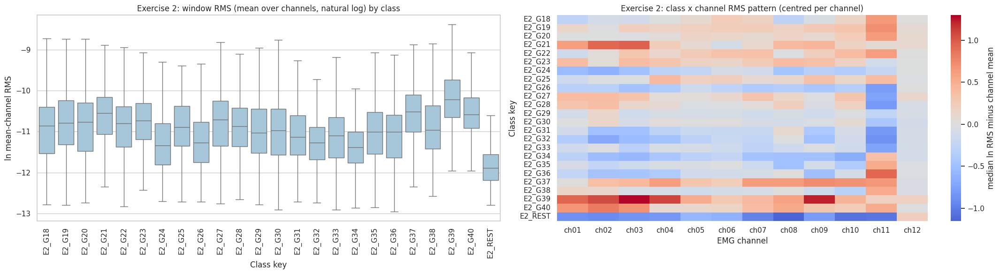

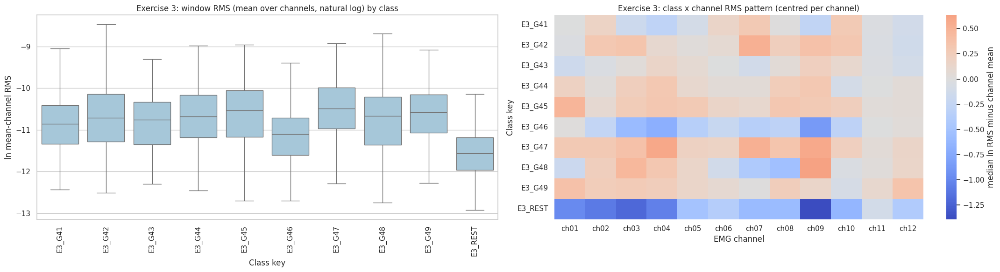


--- Reading of the figure/table ---
WHAT IS SHOWN       : Left: distribution of window RMS (averaged over channels) per class. Right: which channels are relatively more active for each class (median window RMS, centred per channel).
OBSERVED (computed) : Share of variance of mean-channel window log-RMS explained by class (non-rest) vs by subject, per exercise: E1: class 0.08 vs subject 0.37; E2: class 0.11 vs subject 0.42; E3: class 0.05 vs subject 0.47.
WHY IT MAY MATTER   : A larger subject share than class share would suggest that a single global amplitude feature mainly encodes WHO is performing; spatial patterns across channels (right panel) are the type of structure a graph model could exploit. (hypothesis)
CANNOT BE CONCLUDED : Visible class differences in selected features do not prove a model can classify gestures reliably; overlap between classes is expected to remain, and the sampling here is capped per file/class. 

[E] Variance share of mean-channel log-RMS (non-rest): E1

In [19]:
#  E2 derived features and E3 class-conditional behaviour
FEAT_DF = {f: pd.DataFrame(win_feat[f], columns=CH) for f in FEATS}
E2 = pd.concat([FEAT_DF[f].describe(percentiles=[.25, .5, .75]).T.assign(feature=f, skew=FEAT_DF[f].skew().values, kurt_excess=FEAT_DF[f].kurt().values) for f in FEATS])
save_table(E2.reset_index().rename(columns={"index": "channel"}), "E2_window_feature_descriptives")
print("E2. Window-level handcrafted-feature descriptives (per channel; window = %d samples; sampled windows N=%d)" % (W, len(win_meta)))
display(E2.reset_index().rename(columns={"index": "channel"}).groupby("feature")[["mean", "50%", "std", "skew", "kurt_excess"]].agg(["min", "max"]))

fig, ax = plt.subplots(1, 4, figsize=(24, 5))
for a, f in zip(ax, ["RMS", "MAV", "WL", "ZC"]):
    sns.boxplot(data=np.log10(FEAT_DF[f] + 1e-12) if f != "ZC" else FEAT_DF[f], ax=a, showfliers=False, color="#a1d99b")
    a.set_title(f"{f} per channel over a 200 ms window" + (" (log10)" if f != "ZC" else " (count)")); a.set_xlabel("EMG channel"); a.set_ylabel(f"log10 {f}" if f != "ZC" else "zero crossings / window"); a.tick_params(axis="x", rotation=60)
fig.tight_layout(); savefig(fig, "E2_feature_boxplots")
fm_ = {f: FEAT_DF[f].median() for f in FEATS}
interpret("Distribution of window-level handcrafted features for every channel (sampled windows).",
          f"Median RMS ranges {fm_['RMS'].min():.3g}-{fm_['RMS'].max():.3g} across channels (ratio {fm_['RMS'].max() / fm_['RMS'].min():.1f}); median ZC per window {fm_['ZC'].min():.0f}-{fm_['ZC'].max():.0f}.",
          "Feature scales differ by orders of magnitude between feature types and between channels, so features must be standardised (fitted on training subjects) before being combined or compared.",
          "These are sampled windows with class-capped sampling, not the full window population.")

# E3 class-conditional
win_meta["act_logRMS"] = np.log(FEAT_DF["RMS"].mean(1).values + 1e-12)
def eta2(v, g):
    d = pd.DataFrame({"v": v, "g": g}); gm = d.v.mean(); tot = ((d.v - gm) ** 2).sum()
    return float(d.groupby("g").v.apply(lambda s: len(s) * (s.mean() - gm) ** 2).sum() / tot) if tot > 0 else np.nan
eta_rows = []
for e in sorted(win_meta.exercise.unique()):
    d = win_meta[win_meta.exercise == e]; dn = d[~d.is_rest]
    eta_rows.append(dict(exercise=e, n_windows=len(d), eta2_class_incl_rest=eta2(d.act_logRMS, d.class_key), eta2_class_nonrest=eta2(dn.act_logRMS, dn.class_key) if dn.class_key.nunique() > 1 else np.nan,
                         eta2_subject_nonrest=eta2(dn.act_logRMS, dn.subject) if dn.subject.nunique() > 1 else np.nan))
eta_df = pd.DataFrame(eta_rows); save_table(eta_df, "E3_variance_share_class_vs_subject"); display(eta_df)

for e in sorted(win_meta.exercise.unique()):
    d = win_meta[(win_meta.exercise == e)]
    fig, ax = plt.subplots(1, 2, figsize=(22, 6))
    order = sorted(d.class_key.unique())
    sns.boxplot(data=d, x="class_key", y="act_logRMS", order=order, ax=ax[0], showfliers=False, color="#9ecae1"); ax[0].set_title(f"Exercise {e}: window RMS (mean over channels, natural log) by class"); ax[0].set_xlabel("Class key"); ax[0].set_ylabel("ln mean-channel RMS"); ax[0].tick_params(axis="x", rotation=90)
    hm = pd.DataFrame(np.log(win_feat["RMS"] + 1e-12), columns=CH).assign(class_key=win_meta.class_key.values)[win_meta.exercise.values == e].groupby("class_key").median().loc[order]
    sns.heatmap(hm - hm.mean(0), cmap="coolwarm", center=0, ax=ax[1], cbar_kws={"label": "median ln RMS minus channel mean"}); ax[1].set_title(f"Exercise {e}: class x channel RMS pattern (centred per channel)"); ax[1].set_xlabel("EMG channel"); ax[1].set_ylabel("Class key")
    fig.tight_layout(); savefig(fig, f"E3_class_conditional_exercise{e}")
r_ = eta_df.iloc[0]
interpret("Left: distribution of window RMS (averaged over channels) per class. Right: which channels are relatively more active for each class (median window RMS, centred per channel).",
          "Share of variance of mean-channel window log-RMS explained by class (non-rest) vs by subject, per exercise: " + "; ".join(f"E{int(r.exercise)}: class {r.eta2_class_nonrest:.2f} vs subject {r.eta2_subject_nonrest:.2f}" for r in eta_df.itertuples()) + ".",
          "A larger subject share than class share would suggest that a single global amplitude feature mainly encodes WHO is performing; spatial patterns across channels (right panel) are the type of structure a graph model could exploit.",
          "Visible class differences in selected features do not prove a model can classify gestures reliably; overlap between classes is expected to remain, and the sampling here is capped per file/class.")
note("E", "Variance share of mean-channel log-RMS (non-rest): " + "; ".join(f"E{int(r.exercise)} class {r.eta2_class_nonrest:.2f} / subject {r.eta2_subject_nonrest:.2f}" for r in eta_df.itertuples()) + ".")
print("E4 modelling implications (conditional on the numbers above): feature/channel scales differ -> fit per-channel scaling on TRAIN subjects; features of the same family across channels are expected to co-vary (see F); raw sEMG stays the primary representation, handcrafted features are an optional comparison input.")

# SECTION F — Correlation analysis
Two different things are kept apart: (i) channel-to-channel correlation (12×12; relevant to graph construction) and (ii) feature-to-feature correlation (60×60 handcrafted features; relevant to redundancy). Channel-channel correlation is computed in two ways: raw signed signal (exact, from sufficient statistics) and window-RMS envelope (correlation across sampled windows of per-channel RMS). They answer different questions and generally differ. Results depend on the aggregation (pooled recordings include between-recording mean offsets; envelope correlations depend on how rest/active windows are mixed). Leakage control: matrices that will define graphs use TRAIN subjects only; all-subject matrices are shown for description.

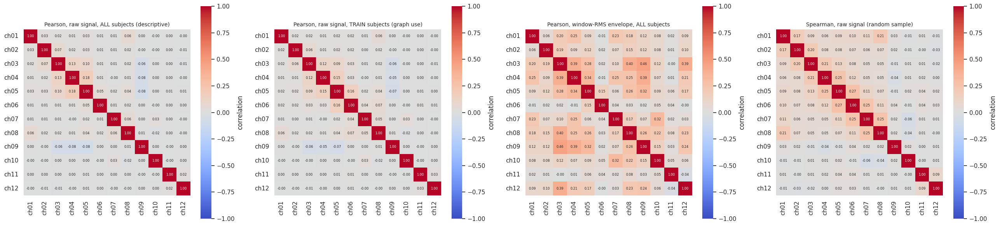


--- Reading of the figure/table ---
WHAT IS SHOWN       : 12x12 channel correlation under four definitions.
OBSERVED (computed) : Median |r| off-diagonal: raw 0.007 (train 0.007), RMS envelope 0.096, Spearman 0.038; max |r|: raw 0.176, envelope 0.456.
WHY IT MAY MATTER   : If raw-signal correlations are weak but envelope correlations are strong, a graph from raw correlation would carry little structure while an activation-envelope similarity might; the threshold study below shows how the graph changes. (hypothesis)
CANNOT BE CONCLUDED : Correlation is statistical association (volume conduction, common contraction timing), not a physiological connection, and it varies with interval and aggregation. 

[F] Median off-diagonal |r|: raw 0.007, RMS-envelope 0.096; max |r| raw 0.176, envelope 0.456.
Highly correlated pairs |r| >= 0.9: raw 0, RMS-envelope 0


,result
0,no envelope pair reaches the threshold


Top-8 envelope pairs (any magnitude):


,ch_a,ch_b,r,abs_r
26,ch03,ch09,0.455678,0.455678
25,ch03,ch08,0.395339,0.395339
34,ch04,ch09,0.393922,0.393922
29,ch03,ch12,0.391976,0.391976
21,ch03,ch04,0.389130,0.389130
30,ch04,ch05,0.336321,0.336321
53,ch07,ch10,0.319427,0.319427
41,ch05,ch09,0.315484,0.315484


Across-subject std of raw pair correlation: median 0.032, max 0.190
Class-conditional raw correlation vs pooled (Frobenius distance, train subjects): {'E2_G34': 0.267, 'E1_G01': 0.293, 'E2_G32': 0.376, 'E2_G24': 0.223}
[F] Raw pair-correlation varies across subjects: median std 0.032, max 0.190; class-conditional matrices differ from pooled by Frobenius distance 0.22-0.38.


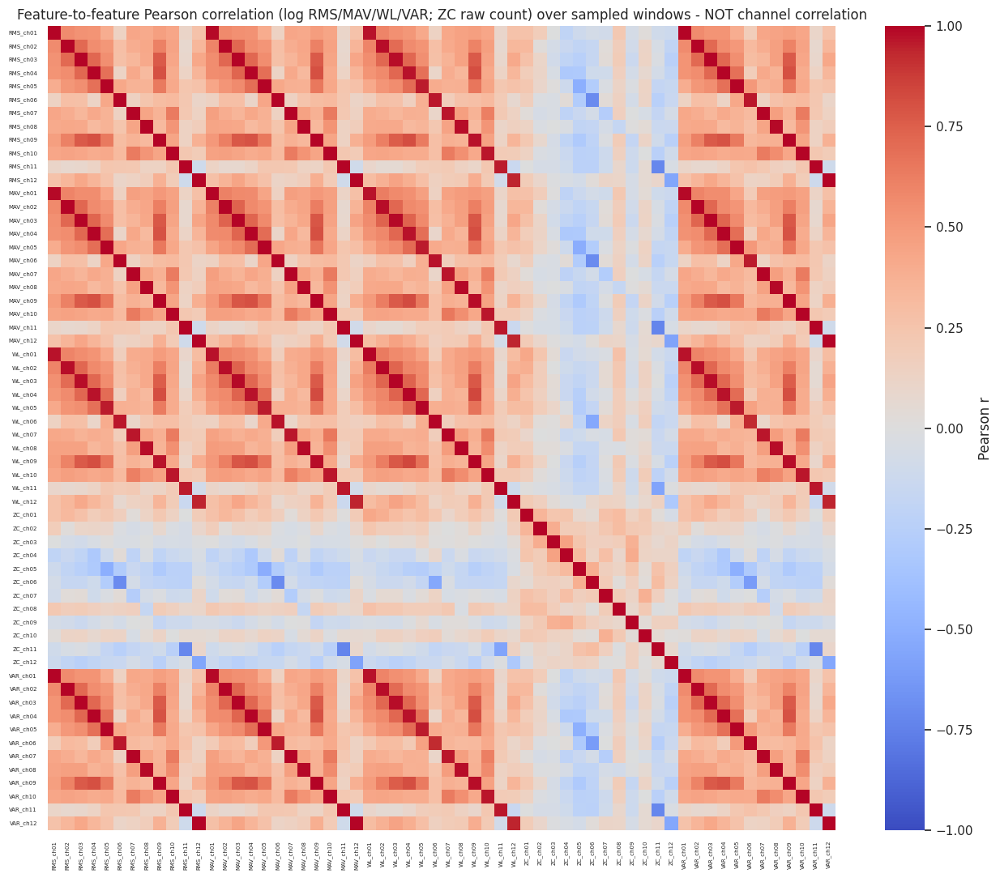

Feature pairs with |r| >= 0.9: 72 (same-channel pairs: 72)


,ch_a,ch_b,r,abs_r,same_channel
164,RMS_ch03,VAR_ch03,0.999905,0.999905,True
542,RMS_ch10,VAR_ch10,0.999890,0.999890,True
386,RMS_ch07,VAR_ch07,0.999847,0.999847,True
221,RMS_ch04,VAR_ch04,0.999827,0.999827,True
592,RMS_ch11,VAR_ch11,0.999776,0.999776,True
277,RMS_ch05,VAR_ch05,0.999731,0.999731,True
641,RMS_ch12,VAR_ch12,0.999656,0.999656,True
491,RMS_ch09,VAR_ch09,0.999336,0.999336,True
106,RMS_ch02,VAR_ch02,0.999183,0.999183,True
296,RMS_ch06,MAV_ch06,0.999007,0.999007,True


,feature,n_high_corr_partners
0,RMS_ch03,3
1,RMS_ch10,3
2,RMS_ch07,3
3,RMS_ch04,3
4,RMS_ch11,3
5,RMS_ch05,3
6,RMS_ch12,3
7,RMS_ch09,3
8,RMS_ch02,3
9,RMS_ch06,3



--- Reading of the figure/table ---
WHAT IS SHOWN       : Pearson correlation among all 60 handcrafted features (log-transformed amplitude features).
OBSERVED (computed) : 72 feature pairs reach |r| >= 0.9; 72 of them are different features of the same channel.
WHY IT MAY MATTER   : RMS, MAV, WL and VAR on the same channel typically carry overlapping amplitude information; a compact handcrafted set (e.g. RMS+WL+ZC) could be tested as an optional comparison. (hypothesis)
CANNOT BE CONCLUDED : High correlation does not show a feature is useless for classification; removal must be decided with training-set-only experiments. 

Graph similarity source: rms_envelope correlation from TRAIN subjects [1, 2, 5, 6, 7, 8, 9, 10]... only.


In [20]:
mask_tr = win_meta.subject.isin(TRAIN).values
R_env_all = np.corrcoef(win_feat["RMS"], rowvar=False); R_env_train = np.corrcoef(win_feat["RMS"][mask_tr], rowvar=False)
R_sp = samp_df[CH].corr(method="spearman").values
fig, ax = plt.subplots(1, 4, figsize=(26, 6))
for a, M, t in zip(ax, [R_raw_all, R_raw_train, R_env_all, R_sp], ["Pearson, raw signal, ALL subjects (descriptive)", "Pearson, raw signal, TRAIN subjects (graph use)", "Pearson, window-RMS envelope, ALL subjects", "Spearman, raw signal (random sample)"]):
    sns.heatmap(M, vmin=-1, vmax=1, cmap="coolwarm", annot=True, fmt=".2f", annot_kws={"size": 6}, xticklabels=CH, yticklabels=CH, ax=a, square=True, cbar_kws={"label": "correlation"}); a.set_title(t, fontsize=10)
fig.tight_layout(); savefig(fig, "F_channel_correlation_heatmaps")
off = lambda M: np.abs(M[np.triu_indices(C, 1)])
interpret("12x12 channel correlation under four definitions.",
          f"Median |r| off-diagonal: raw {np.median(off(R_raw_all)):.3f} (train {np.median(off(R_raw_train)):.3f}), RMS envelope {np.median(off(R_env_all)):.3f}, Spearman {np.median(off(R_sp)):.3f}; max |r|: raw {off(R_raw_all).max():.3f}, envelope {off(R_env_all).max():.3f}.",
          "If raw-signal correlations are weak but envelope correlations are strong, a graph from raw correlation would carry little structure while an activation-envelope similarity might; the threshold study below shows how the graph changes.",
          "Correlation is statistical association (volume conduction, common contraction timing), not a physiological connection, and it varies with interval and aggregation.")
note("F", f"Median off-diagonal |r|: raw {np.median(off(R_raw_all)):.3f}, RMS-envelope {np.median(off(R_env_all)):.3f}; max |r| raw {off(R_raw_all).max():.3f}, envelope {off(R_env_all).max():.3f}.")

pairs_env = top_pairs(R_env_all, CFG["CORR_THR"]); save_table(top_pairs(R_env_all, 0.0).head(30), "F_top_pairs_rms_envelope_all_subjects"); save_table(top_pairs(R_raw_all, 0.0).head(30), "F_top_pairs_raw_all_subjects")
print(f"Highly correlated pairs |r| >= {CFG['CORR_THR']}: raw {len(pairs_all)}, RMS-envelope {len(pairs_env)}"); display(pairs_env if len(pairs_env) else pd.DataFrame({"result": ["no envelope pair reaches the threshold"]}))
print("Top-8 envelope pairs (any magnitude):"); display(top_pairs(R_env_all, 0.0).head(8))

#per-subject / per-class variability of the correlation structure
subj_R = {s_: pearson_from_stats(*pooled_stats({s_})) for s_ in subjects_all}
iu = np.triu_indices(C, 1); stack = np.stack([R[iu] for R in subj_R.values()])
disp = pd.DataFrame({"pair": [f"{CH[i]}-{CH[j]}" for i, j in zip(*iu)], "mean_r_over_subjects": np.nanmean(stack, 0), "std_r_over_subjects": np.nanstd(stack, 0)}).sort_values("std_r_over_subjects", ascending=False)
save_table(disp, "F_subject_variability_of_raw_pair_correlation")
cls_sel = list(nr_.sort_values("n_windows", ascending=False).class_key.head(4))
cls_R = {k: pearson_from_stats(*pooled_stats(TRAIN, {k})) for k in cls_sel}
frob = {k: float(np.linalg.norm(np.nan_to_num(R - R_raw_train))) for k, R in cls_R.items()}
print(f"Across-subject std of raw pair correlation: median {disp.std_r_over_subjects.median():.3f}, max {disp.std_r_over_subjects.max():.3f}")
print("Class-conditional raw correlation vs pooled (Frobenius distance, train subjects):", {k: round(v, 3) for k, v in frob.items()})
note("F", f"Raw pair-correlation varies across subjects: median std {disp.std_r_over_subjects.median():.3f}, max {disp.std_r_over_subjects.max():.3f}; class-conditional matrices differ from pooled by Frobenius distance {min(frob.values()):.2f}-{max(frob.values()):.2f}.")

#feature-to-feature correlation (60 x 60) and redundancy candidates
FM = np.concatenate([np.log(win_feat[f] + 1e-12) if f != "ZC" else win_feat[f] for f in FEATS], axis=1)
FN = [f"{f}_{c}" for f in FEATS for c in CH]
Rf = np.corrcoef(FM, rowvar=False)
fig, ax = plt.subplots(figsize=(13, 11)); sns.heatmap(Rf, cmap="coolwarm", vmin=-1, vmax=1, ax=ax, xticklabels=FN, yticklabels=FN, cbar_kws={"label": "Pearson r"}); ax.tick_params(labelsize=5)
ax.set_title("Feature-to-feature Pearson correlation (log RMS/MAV/WL/VAR; ZC raw count) over sampled windows - NOT channel correlation"); fig.tight_layout(); savefig(fig, "F_feature_correlation_heatmap")
fp = top_pairs(Rf, CFG["CORR_THR"], FN); fp["same_channel"] = fp.ch_a.str.split("_").str[1] == fp.ch_b.str.split("_").str[1]
save_table(fp, "F_redundant_feature_pairs"); print(f"Feature pairs with |r| >= {CFG['CORR_THR']}: {len(fp)} (same-channel pairs: {int(fp.same_channel.sum())})"); display(fp.head(15))
from collections import Counter
cnt = Counter(list(fp.ch_a) + list(fp.ch_b)); red = pd.DataFrame(cnt.most_common(15), columns=["feature", "n_high_corr_partners"]); save_table(red, "F_redundant_feature_candidates"); display(red)
interpret("Pearson correlation among all 60 handcrafted features (log-transformed amplitude features).",
          f"{len(fp)} feature pairs reach |r| >= {CFG['CORR_THR']}; {int(fp.same_channel.sum())} of them are different features of the same channel.",
          "RMS, MAV, WL and VAR on the same channel typically carry overlapping amplitude information; a compact handcrafted set (e.g. RMS+WL+ZC) could be tested as an optional comparison.",
          "High correlation does not show a feature is useless for classification; removal must be decided with training-set-only experiments.")

#Graph similarity (TRAIN subjects only) and threshold sweep
SIM = R_env_train if CFG["GRAPH_SIM"] == "rms_envelope" else R_raw_train
SIM = np.nan_to_num(SIM); np.fill_diagonal(SIM, 1.0)
print(f"Graph similarity source: {CFG['GRAPH_SIM']} correlation from TRAIN subjects {sorted(TRAIN)[:8]}{'...' if len(TRAIN) > 8 else ''} only.")

# SECTION G — 2D / 3D dimensionality reduction
Representations (each window → one vector)

Raw-window vector: the (12 channels × W samples) window is scaled per channel by the training-subject channel std (mean removed) and flattened to a vector of length 12·W (= 4,800 for W = 400). For t-SNE/UMAP this vector is first reduced by PCA to 50 components (standard practice; stated here because it changes what is visualised).
Handcrafted vector: 60 features (5 × 12 channels), log-transformed for RMS/MAV/WL/VAR, z-scored with a scaler fitted on training subjects only.
Sampling & reproducibility. Only the sampled windows (class-capped per file) are used — not the whole raw dataset. PCA is fitted on training subjects and applied to all; t-SNE/UMAP have no out-of-sample transform, so they are run on a random subset of at most EMBED_MAX_PER_EXERCISE windows of each exercise (seed in CFG). Embeddings are descriptive only; no model or threshold decision is taken from them. Labels from different exercises are different gestures, so embeddings are shown per exercise.

Raw-window vectors: (16640, 4800) (305 MB) | handcrafted vectors: (16640, 60)
PCA raw-window (train fit): explained variance of PC1-3 = [0.0381 0.022  0.0171] | cumulative 10 PCs = 0.142
PCA handcrafted (train fit): explained variance of PC1-3 = [0.3867 0.1038 0.0809]


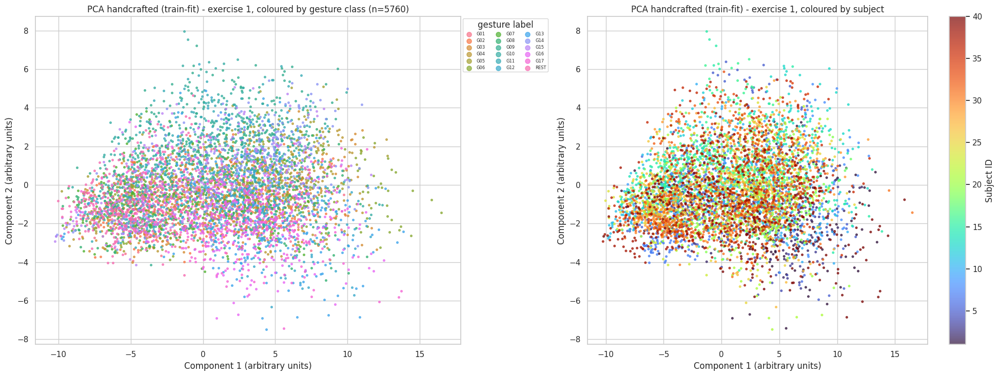

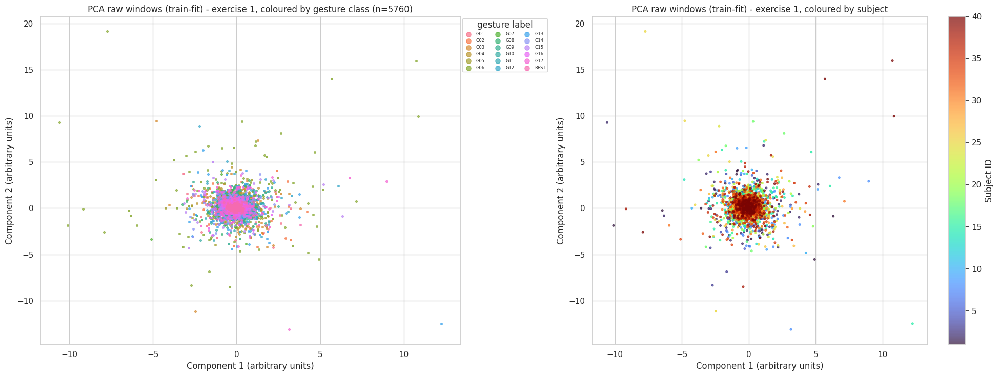


--- Reading of the figure/table ---
WHAT IS SHOWN       : PCA of window vectors (left: gesture classes, right: subjects) for exercise 1.
OBSERVED (computed) : Silhouette (cosine-free, Euclidean, 2-D): handcrafted class -0.18 / subject -0.29; raw-window class -0.15 / subject -0.35. PC1-2 explain 49.1% (handcrafted) and 6.0% (raw).
WHY IT MAY MATTER   : Silhouette closer to 0 for classes and larger for subjects would hint that subject identity dominates the leading linear directions, i.e. cross-subject shift; the converse would suggest class structure dominates. (hypothesis)
CANNOT BE CONCLUDED : PCA only captures linear variance in two directions; visible overlap does not prove gestures are inseparable and visible clusters do not prove classification performance. 



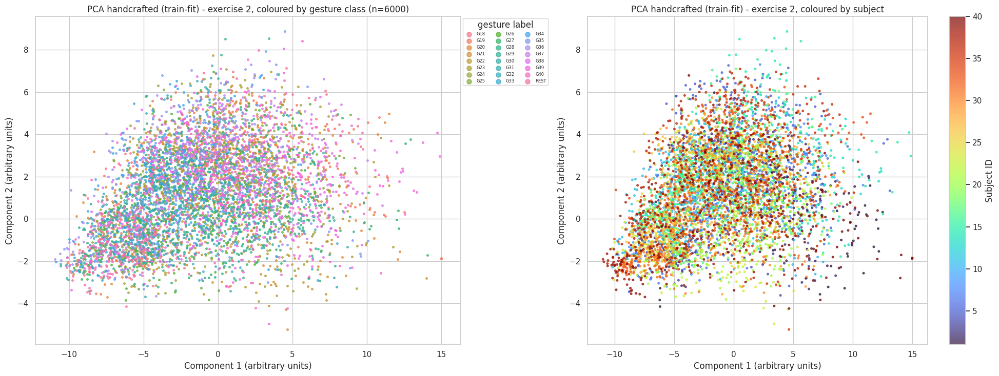

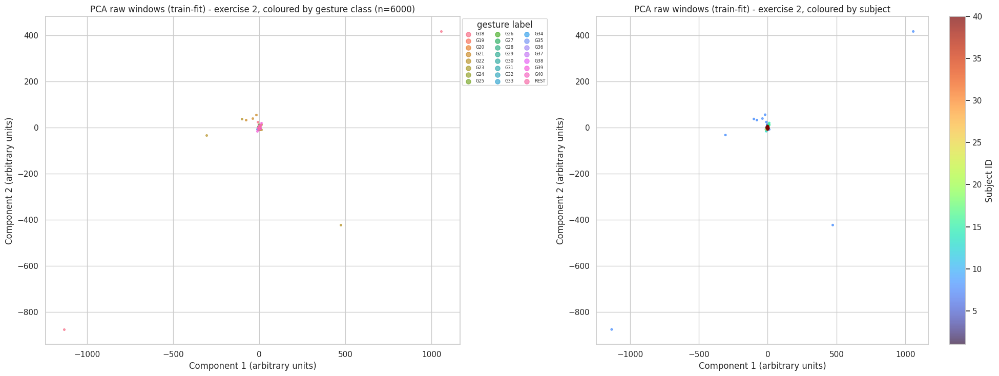


--- Reading of the figure/table ---
WHAT IS SHOWN       : PCA of window vectors (left: gesture classes, right: subjects) for exercise 2.
OBSERVED (computed) : Silhouette (cosine-free, Euclidean, 2-D): handcrafted class -0.21 / subject -0.27; raw-window class -0.37 / subject -0.28. PC1-2 explain 49.1% (handcrafted) and 6.0% (raw).
WHY IT MAY MATTER   : Silhouette closer to 0 for classes and larger for subjects would hint that subject identity dominates the leading linear directions, i.e. cross-subject shift; the converse would suggest class structure dominates. (hypothesis)
CANNOT BE CONCLUDED : PCA only captures linear variance in two directions; visible overlap does not prove gestures are inseparable and visible clusters do not prove classification performance. 



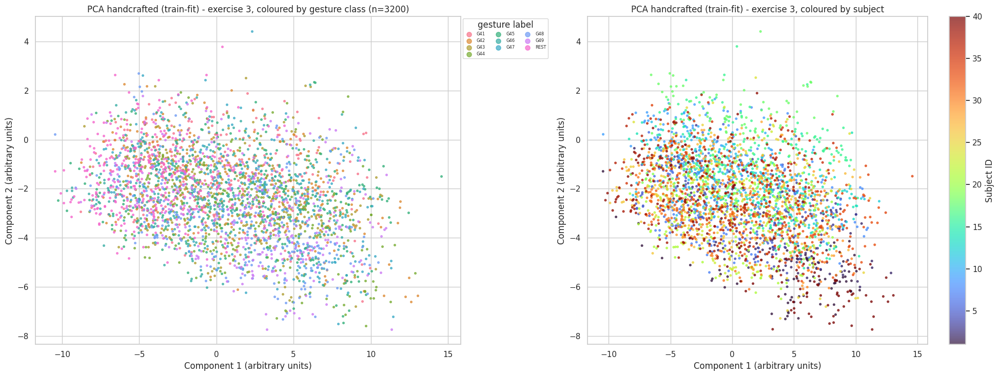

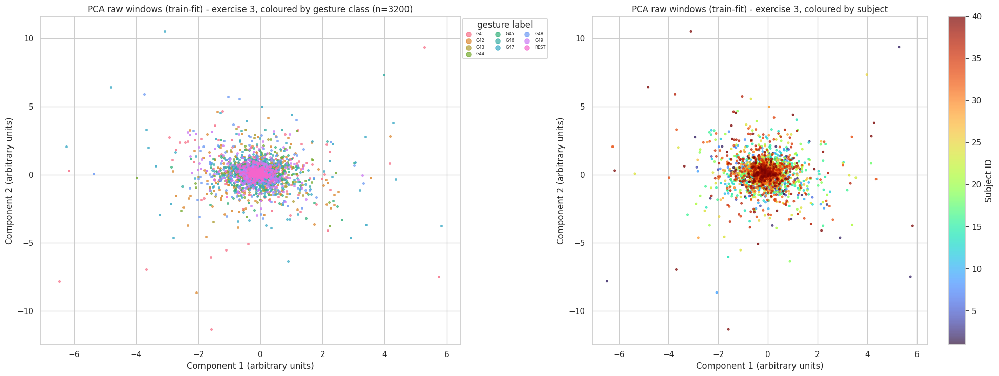


--- Reading of the figure/table ---
WHAT IS SHOWN       : PCA of window vectors (left: gesture classes, right: subjects) for exercise 3.
OBSERVED (computed) : Silhouette (cosine-free, Euclidean, 2-D): handcrafted class -0.12 / subject -0.29; raw-window class -0.17 / subject -0.33. PC1-2 explain 49.1% (handcrafted) and 6.0% (raw).
WHY IT MAY MATTER   : Silhouette closer to 0 for classes and larger for subjects would hint that subject identity dominates the leading linear directions, i.e. cross-subject shift; the converse would suggest class structure dominates. (hypothesis)
CANNOT BE CONCLUDED : PCA only captures linear variance in two directions; visible overlap does not prove gestures are inseparable and visible clusters do not prove classification performance. 



In [21]:
from sklearn.metrics import silhouette_score
sc_feat = StandardScaler().fit(FM[mask_tr]); FMz = sc_feat.transform(FM)
mom_tr = add_moments([r["mom_all"] for r in res if r["info"]["subject_fn"] in TRAIN]); st_tr = central_stats(mom_tr)
RAWV = ((win_raw - st_tr["mean"][None, :, None]) / (st_tr["std"][None, :, None] + 1e-12)).reshape(len(win_raw), -1).astype(np.float32)
print(f"Raw-window vectors: {RAWV.shape} ({RAWV.nbytes / 2**20:.0f} MB) | handcrafted vectors: {FMz.shape}")

pca_raw = PCA(n_components=min(50, RAWV.shape[1], mask_tr.sum() - 1), svd_solver="randomized", random_state=SEED).fit(RAWV[mask_tr])
Zraw50 = pca_raw.transform(RAWV)
pca_ft = PCA(n_components=3, random_state=SEED).fit(FMz[mask_tr]); Zft = pca_ft.transform(FMz)
print("PCA raw-window (train fit): explained variance of PC1-3 =", np.round(pca_raw.explained_variance_ratio_[:3], 4), "| cumulative 10 PCs =", round(float(pca_raw.explained_variance_ratio_[:10].sum()), 3))
print("PCA handcrafted (train fit): explained variance of PC1-3 =", np.round(pca_ft.explained_variance_ratio_, 4))

rng_emb = np.random.default_rng(SEED)
def exercise_subset(e, cap):
    idx = np.flatnonzero(win_meta.exercise.values == e)
    return np.sort(rng_emb.choice(idx, size=min(cap, len(idx)), replace=False))

def sil(Z, labels):
    labels = np.asarray(labels)
    if len(np.unique(labels)) < 2 or len(Z) < 10: return np.nan
    try: return float(silhouette_score(Z, labels, sample_size=min(2000, len(Z)), random_state=SEED))
    except Exception: return np.nan

EMB_SUMMARY = []
def show_embedding(Z, idx, title, name, ex):
    meta = win_meta.iloc[idx]
    classes = sorted(meta.class_key.unique()); pal = sns.color_palette("husl", len(classes))
    fig, ax = plt.subplots(1, 2, figsize=(20, 7.5))
    for k, c in zip(classes, pal):
        m = (meta.class_key == k).values; ax[0].scatter(Z[m, 0], Z[m, 1], s=7, color=c, alpha=.7, label=k.split("_", 1)[1])
    if len(classes) <= 26: ax[0].legend(title="gesture label", ncol=3, fontsize=6, markerscale=2.5, bbox_to_anchor=(1.0, 1.0), loc="upper left")
    ax[0].set_title(f"{title} - exercise {ex}, coloured by gesture class (n={len(idx)})"); ax[0].set_xlabel("Component 1 (arbitrary units)"); ax[0].set_ylabel("Component 2 (arbitrary units)")
    sc_ = ax[1].scatter(Z[:, 0], Z[:, 1], c=meta.subject.values, cmap="turbo", s=7, alpha=.7); plt.colorbar(sc_, ax=ax[1], label="Subject ID")
    ax[1].set_title(f"{title} - exercise {ex}, coloured by subject"); ax[1].set_xlabel("Component 1 (arbitrary units)"); ax[1].set_ylabel("Component 2 (arbitrary units)")
    fig.tight_layout(); savefig(fig, f"G_{name}_exercise{ex}")
    nr_m = (~meta.is_rest).values
    s_cls = sil(Z[nr_m], meta.class_key.values[nr_m]); s_sub = sil(Z, meta.subject.values)
    EMB_SUMMARY.append(dict(method=title, exercise=ex, n=len(idx), silhouette_by_class_nonrest=s_cls, silhouette_by_subject=s_sub))
    return s_cls, s_sub

exs = sorted(win_meta.exercise.unique())
for e in exs:
    idx = exercise_subset(e, 6000)
    a, b = show_embedding(Zft[idx, :2], idx, "PCA handcrafted (train-fit)", "pca_features", e)
    a2, b2 = show_embedding(Zraw50[idx, :2], idx, "PCA raw windows (train-fit)", "pca_raw", e)
    interpret(f"PCA of window vectors (left: gesture classes, right: subjects) for exercise {e}.",
              f"Silhouette (cosine-free, Euclidean, 2-D): handcrafted class {a:.2f} / subject {b:.2f}; raw-window class {a2:.2f} / subject {b2:.2f}. PC1-2 explain {pca_ft.explained_variance_ratio_[:2].sum():.1%} (handcrafted) and {pca_raw.explained_variance_ratio_[:2].sum():.1%} (raw).",
              "Silhouette closer to 0 for classes and larger for subjects would hint that subject identity dominates the leading linear directions, i.e. cross-subject shift; the converse would suggest class structure dominates.",
              "PCA only captures linear variance in two directions; visible overlap does not prove gestures are inseparable and visible clusters do not prove classification performance.")

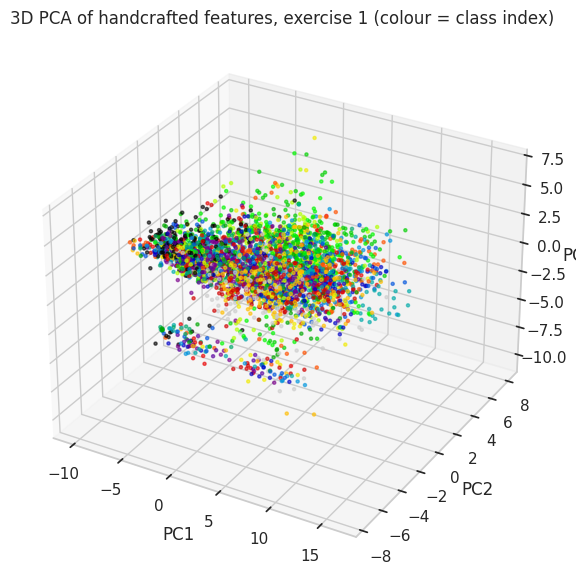

Exercise 1: t-SNE/UMAP on 3000 random windows (seed 42)


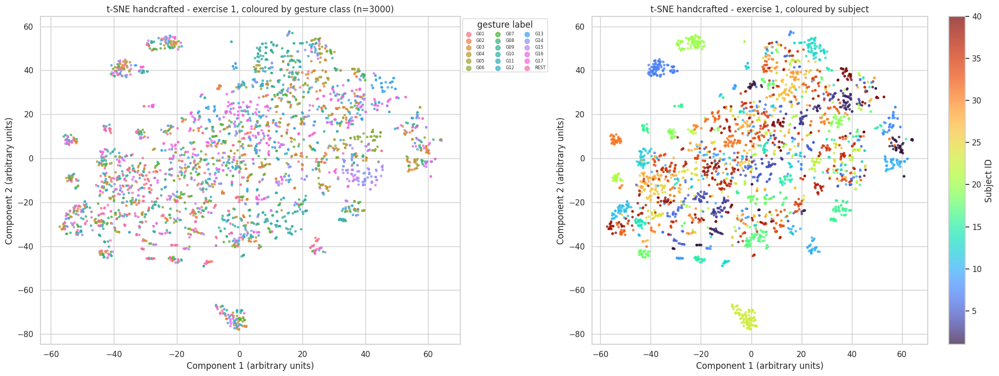


--- Reading of the figure/table ---
WHAT IS SHOWN       : t-SNE of handcrafted vectors (perplexity ~30, init=PCA, seed 42), exercise 1.
OBSERVED (computed) : Silhouette in 2-D: class -0.15, subject -0.16.
WHY IT MAY MATTER   : Local neighbourhood structure by class or by subject can indicate whether windows from the same subject sit closer than windows of the same class. (hypothesis)
CANNOT BE CONCLUDED : t-SNE distorts global distances and depends on perplexity/seed; cluster sizes and gaps are not meaningful measurements. 



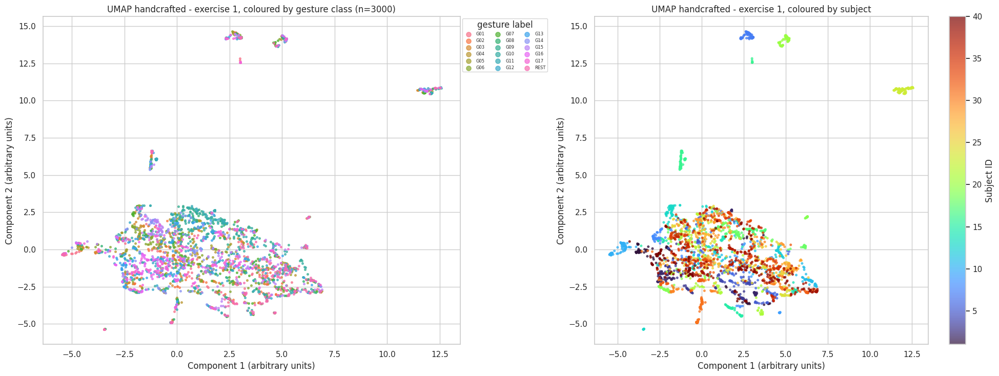


--- Reading of the figure/table ---
WHAT IS SHOWN       : UMAP of handcrafted vectors (n_neighbors=15, min_dist=0.1, seed 42), exercise 1.
OBSERVED (computed) : Silhouette in 2-D: class -0.12, subject -0.12.
WHY IT MAY MATTER   : Provides a second non-linear view; agreement between PCA, t-SNE and UMAP strengthens a qualitative statement, disagreement weakens it. (hypothesis)
CANNOT BE CONCLUDED : UMAP is also parameter-dependent and can create apparent clusters; no classification claim follows. 



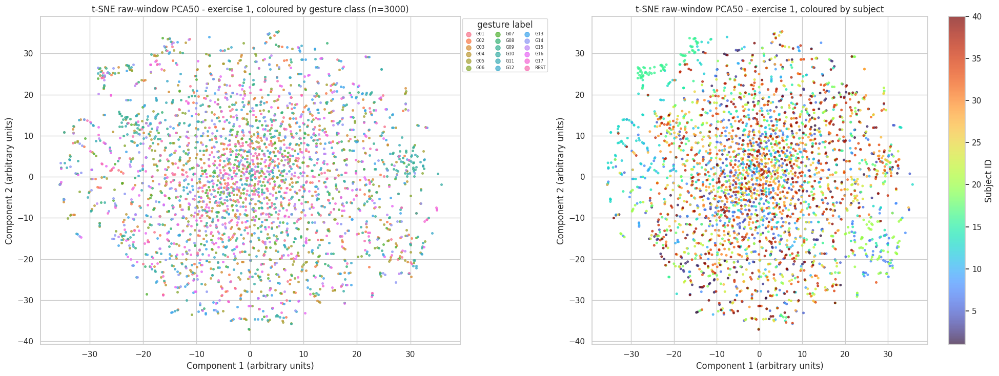


--- Reading of the figure/table ---
WHAT IS SHOWN       : t-SNE of raw-window PCA50 vectors (perplexity ~30, init=PCA, seed 42), exercise 1.
OBSERVED (computed) : Silhouette in 2-D: class -0.11, subject -0.20.
WHY IT MAY MATTER   : Local neighbourhood structure by class or by subject can indicate whether windows from the same subject sit closer than windows of the same class. (hypothesis)
CANNOT BE CONCLUDED : t-SNE distorts global distances and depends on perplexity/seed; cluster sizes and gaps are not meaningful measurements. 



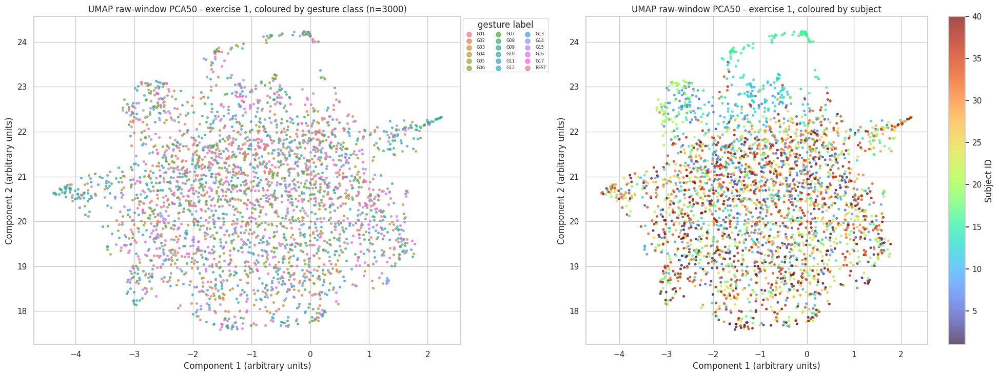


--- Reading of the figure/table ---
WHAT IS SHOWN       : UMAP of raw-window PCA50 vectors (n_neighbors=15, min_dist=0.1, seed 42), exercise 1.
OBSERVED (computed) : Silhouette in 2-D: class -0.11, subject -0.19.
WHY IT MAY MATTER   : Provides a second non-linear view; agreement between PCA, t-SNE and UMAP strengthens a qualitative statement, disagreement weakens it. (hypothesis)
CANNOT BE CONCLUDED : UMAP is also parameter-dependent and can create apparent clusters; no classification claim follows. 

Exercise 2: t-SNE/UMAP on 3000 random windows (seed 42)


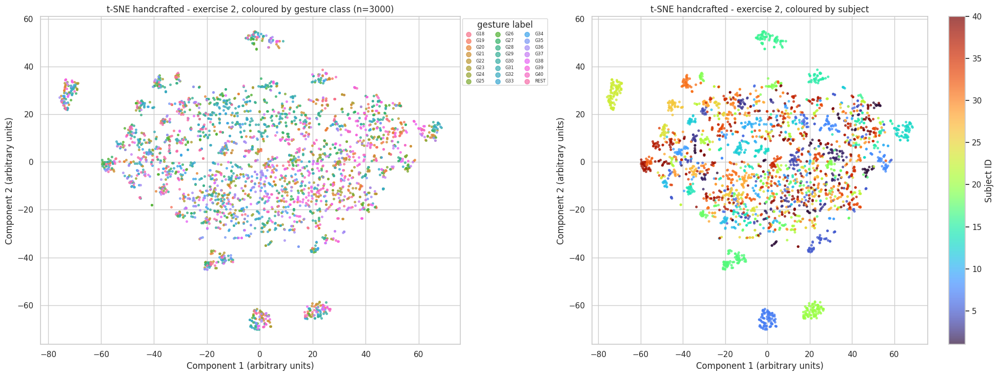


--- Reading of the figure/table ---
WHAT IS SHOWN       : t-SNE of handcrafted vectors (perplexity ~30, init=PCA, seed 42), exercise 2.
OBSERVED (computed) : Silhouette in 2-D: class -0.20, subject -0.12.
WHY IT MAY MATTER   : Local neighbourhood structure by class or by subject can indicate whether windows from the same subject sit closer than windows of the same class. (hypothesis)
CANNOT BE CONCLUDED : t-SNE distorts global distances and depends on perplexity/seed; cluster sizes and gaps are not meaningful measurements. 



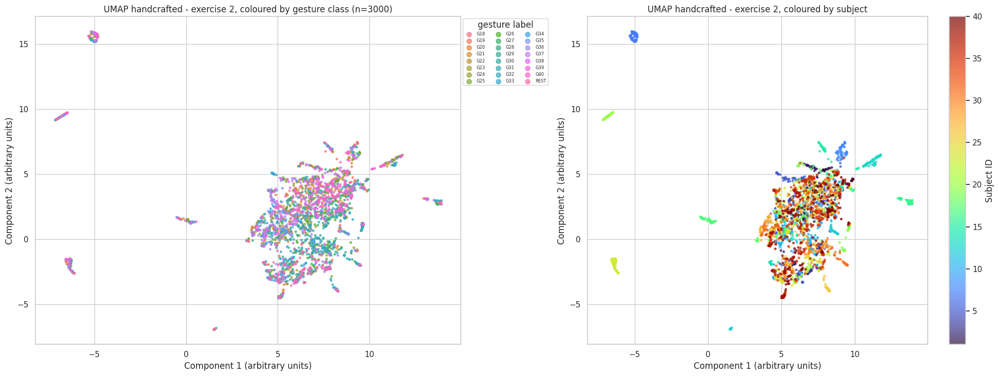


--- Reading of the figure/table ---
WHAT IS SHOWN       : UMAP of handcrafted vectors (n_neighbors=15, min_dist=0.1, seed 42), exercise 2.
OBSERVED (computed) : Silhouette in 2-D: class -0.18, subject -0.04.
WHY IT MAY MATTER   : Provides a second non-linear view; agreement between PCA, t-SNE and UMAP strengthens a qualitative statement, disagreement weakens it. (hypothesis)
CANNOT BE CONCLUDED : UMAP is also parameter-dependent and can create apparent clusters; no classification claim follows. 



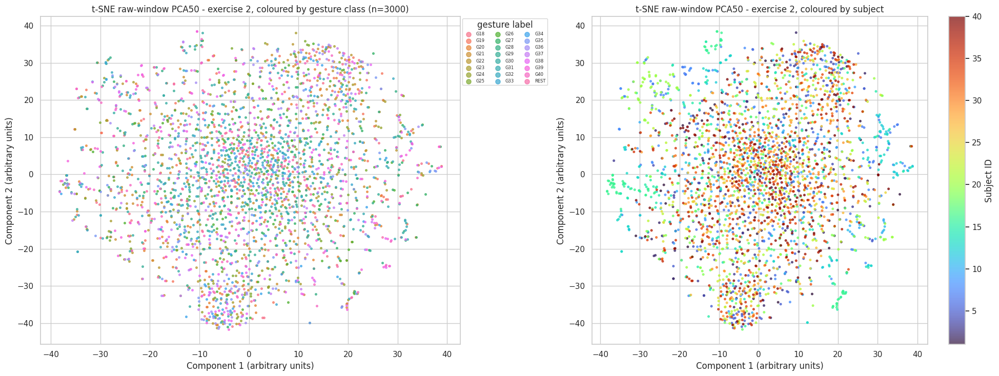


--- Reading of the figure/table ---
WHAT IS SHOWN       : t-SNE of raw-window PCA50 vectors (perplexity ~30, init=PCA, seed 42), exercise 2.
OBSERVED (computed) : Silhouette in 2-D: class -0.12, subject -0.17.
WHY IT MAY MATTER   : Local neighbourhood structure by class or by subject can indicate whether windows from the same subject sit closer than windows of the same class. (hypothesis)
CANNOT BE CONCLUDED : t-SNE distorts global distances and depends on perplexity/seed; cluster sizes and gaps are not meaningful measurements. 



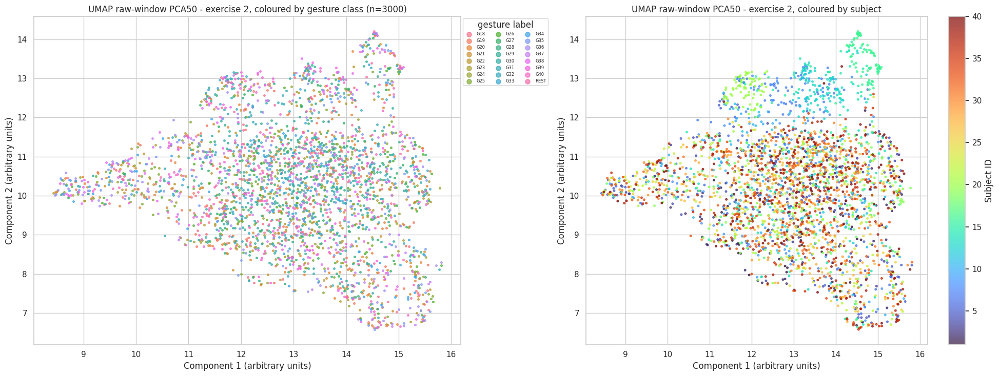


--- Reading of the figure/table ---
WHAT IS SHOWN       : UMAP of raw-window PCA50 vectors (n_neighbors=15, min_dist=0.1, seed 42), exercise 2.
OBSERVED (computed) : Silhouette in 2-D: class -0.15, subject -0.17.
WHY IT MAY MATTER   : Provides a second non-linear view; agreement between PCA, t-SNE and UMAP strengthens a qualitative statement, disagreement weakens it. (hypothesis)
CANNOT BE CONCLUDED : UMAP is also parameter-dependent and can create apparent clusters; no classification claim follows. 

Exercise 3: t-SNE/UMAP on 3000 random windows (seed 42)


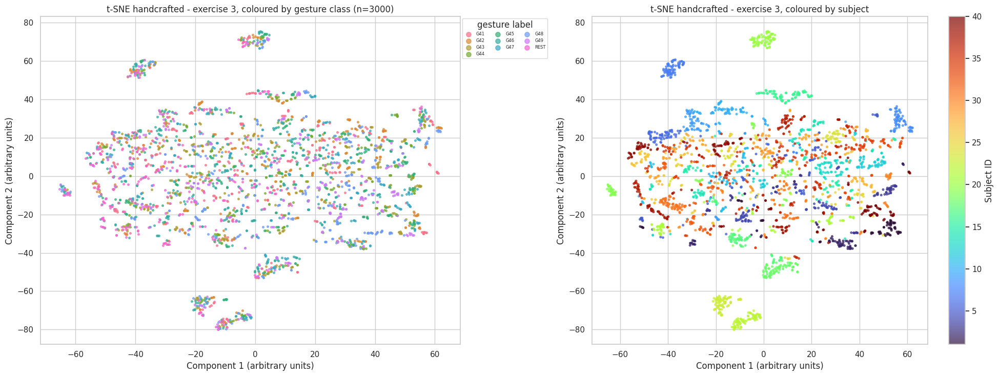


--- Reading of the figure/table ---
WHAT IS SHOWN       : t-SNE of handcrafted vectors (perplexity ~30, init=PCA, seed 42), exercise 3.
OBSERVED (computed) : Silhouette in 2-D: class -0.08, subject -0.04.
WHY IT MAY MATTER   : Local neighbourhood structure by class or by subject can indicate whether windows from the same subject sit closer than windows of the same class. (hypothesis)
CANNOT BE CONCLUDED : t-SNE distorts global distances and depends on perplexity/seed; cluster sizes and gaps are not meaningful measurements. 



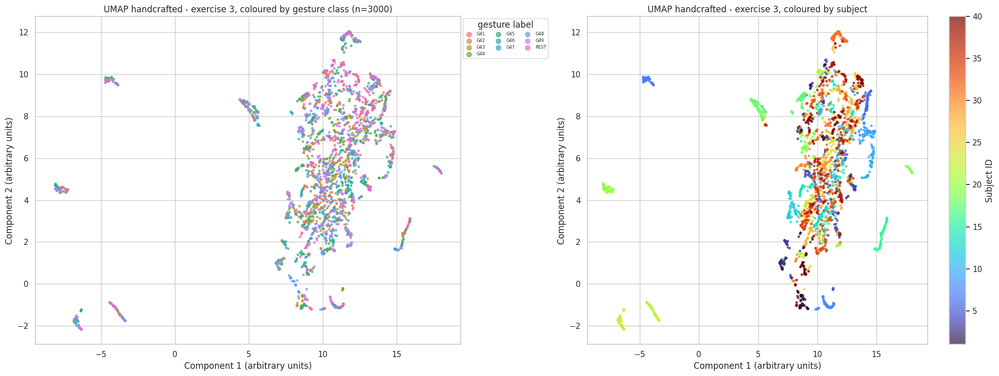


--- Reading of the figure/table ---
WHAT IS SHOWN       : UMAP of handcrafted vectors (n_neighbors=15, min_dist=0.1, seed 42), exercise 3.
OBSERVED (computed) : Silhouette in 2-D: class -0.07, subject 0.01.
WHY IT MAY MATTER   : Provides a second non-linear view; agreement between PCA, t-SNE and UMAP strengthens a qualitative statement, disagreement weakens it. (hypothesis)
CANNOT BE CONCLUDED : UMAP is also parameter-dependent and can create apparent clusters; no classification claim follows. 



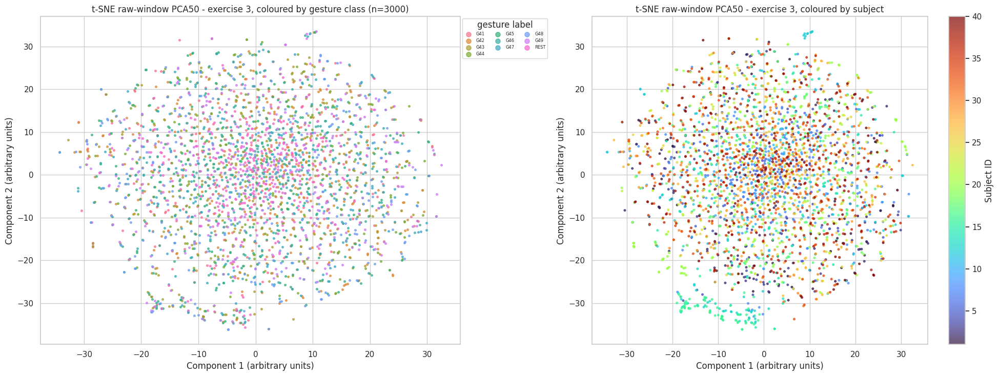


--- Reading of the figure/table ---
WHAT IS SHOWN       : t-SNE of raw-window PCA50 vectors (perplexity ~30, init=PCA, seed 42), exercise 3.
OBSERVED (computed) : Silhouette in 2-D: class -0.09, subject -0.25.
WHY IT MAY MATTER   : Local neighbourhood structure by class or by subject can indicate whether windows from the same subject sit closer than windows of the same class. (hypothesis)
CANNOT BE CONCLUDED : t-SNE distorts global distances and depends on perplexity/seed; cluster sizes and gaps are not meaningful measurements. 



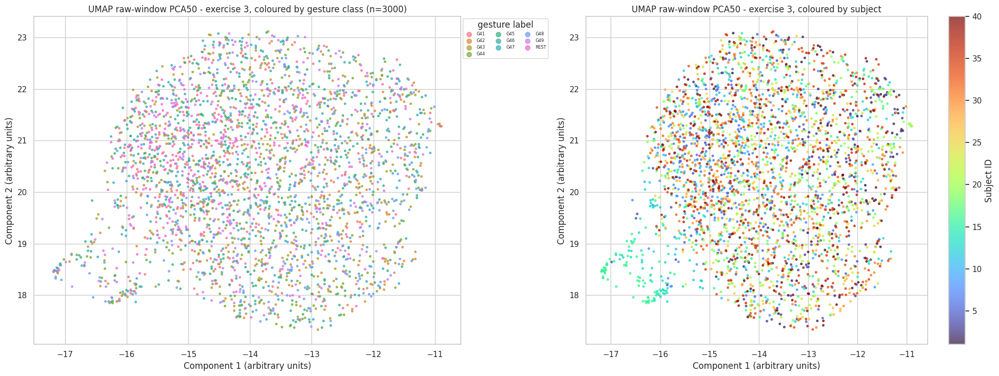


--- Reading of the figure/table ---
WHAT IS SHOWN       : UMAP of raw-window PCA50 vectors (n_neighbors=15, min_dist=0.1, seed 42), exercise 3.
OBSERVED (computed) : Silhouette in 2-D: class -0.10, subject -0.22.
WHY IT MAY MATTER   : Provides a second non-linear view; agreement between PCA, t-SNE and UMAP strengthens a qualitative statement, disagreement weakens it. (hypothesis)
CANNOT BE CONCLUDED : UMAP is also parameter-dependent and can create apparent clusters; no classification claim follows. 



,method,exercise,n,silhouette_by_class_nonrest,silhouette_by_subject
0,PCA handcrafted (train-fit),1,5760,-0.181309,-0.288761
1,PCA raw windows (train-fit),1,5760,-0.148823,-0.348969
2,PCA handcrafted (train-fit),2,6000,-0.207180,-0.270942
3,PCA raw windows (train-fit),2,6000,-0.372606,-0.280043
4,PCA handcrafted (train-fit),3,3200,-0.122963,-0.289602
5,PCA raw windows (train-fit),3,3200,-0.165457,-0.330675
6,t-SNE handcrafted,1,3000,-0.148643,-0.161122
7,UMAP handcrafted,1,3000,-0.121565,-0.116696
8,t-SNE raw-window PCA50,1,3000,-0.105336,-0.197674
9,UMAP raw-window PCA50,1,3000,-0.113777,-0.190260


[G] PCA handcrafted (train-fit), exercise 1: silhouette(class, non-rest) -0.18, silhouette(subject) -0.29, n=5760.
[G] PCA raw windows (train-fit), exercise 1: silhouette(class, non-rest) -0.15, silhouette(subject) -0.35, n=5760.
[G] PCA handcrafted (train-fit), exercise 2: silhouette(class, non-rest) -0.21, silhouette(subject) -0.27, n=6000.
[G] PCA raw windows (train-fit), exercise 2: silhouette(class, non-rest) -0.37, silhouette(subject) -0.28, n=6000.
[G] PCA handcrafted (train-fit), exercise 3: silhouette(class, non-rest) -0.12, silhouette(subject) -0.29, n=3200.
[G] PCA raw windows (train-fit), exercise 3: silhouette(class, non-rest) -0.17, silhouette(subject) -0.33, n=3200.
[G] t-SNE handcrafted, exercise 1: silhouette(class, non-rest) -0.15, silhouette(subject) -0.16, n=3000.
[G] UMAP handcrafted, exercise 1: silhouette(class, non-rest) -0.12, silhouette(subject) -0.12, n=3000.
[G] t-SNE raw-window PCA50, exercise 1: silhouette(class, non-rest) -0.11, silhouette(subject) -0.20,

In [22]:
#  optional 3D PCA (static preview; interactive 3D in Section H)
e0 = exs[0]; idx = exercise_subset(e0, 4000); meta = win_meta.iloc[idx]
fig = plt.figure(figsize=(9, 7)); ax = fig.add_subplot(111, projection="3d")
sc_ = ax.scatter(Zft[idx, 0], Zft[idx, 1], Zft[idx, 2], c=pd.factorize(meta.class_key)[0], cmap="nipy_spectral", s=5, alpha=.6)
ax.set_xlabel("PC1"); ax.set_ylabel("PC2"); ax.set_zlabel("PC3"); ax.set_title(f"3D PCA of handcrafted features, exercise {e0} (colour = class index)"); savefig(fig, "G_pca3d_features_preview")

# t-SNE (and UMAP if available): per exercise, random subset, fixed seed
def run_tsne(X, seed=SEED):
    perp = max(5, min(30, (len(X) - 1) / 3 - 1)); return TSNE(n_components=2, init="pca", perplexity=perp, random_state=seed, learning_rate="auto").fit_transform(X)
def run_umap(X, seed=SEED): return umap.UMAP(n_components=2, n_neighbors=min(15, len(X) - 1), min_dist=0.1, random_state=seed).fit_transform(X)
EMB_TSNE = {}
for e in exs:
    idx = exercise_subset(e, CFG["EMBED_MAX_PER_EXERCISE"]); EMB_TSNE[e] = idx
    print(f"Exercise {e}: t-SNE/UMAP on {len(idx)} random windows (seed {SEED})")
    for rep_name, X in (("handcrafted", FMz[idx]), ("raw-window PCA50", Zraw50[idx])):
        Z = run_tsne(X); a, b = show_embedding(Z, idx, f"t-SNE {rep_name}", f"tsne_{rep_name.split()[0]}", e)
        interpret(f"t-SNE of {rep_name} vectors (perplexity ~30, init=PCA, seed {SEED}), exercise {e}.", f"Silhouette in 2-D: class {a:.2f}, subject {b:.2f}.",
                  "Local neighbourhood structure by class or by subject can indicate whether windows from the same subject sit closer than windows of the same class.",
                  "t-SNE distorts global distances and depends on perplexity/seed; cluster sizes and gaps are not meaningful measurements.")
        if HAS_UMAP:
            Zu = run_umap(X); a, b = show_embedding(Zu, idx, f"UMAP {rep_name}", f"umap_{rep_name.split()[0]}", e)
            interpret(f"UMAP of {rep_name} vectors (n_neighbors=15, min_dist=0.1, seed {SEED}), exercise {e}.", f"Silhouette in 2-D: class {a:.2f}, subject {b:.2f}.",
                      "Provides a second non-linear view; agreement between PCA, t-SNE and UMAP strengthens a qualitative statement, disagreement weakens it.",
                      "UMAP is also parameter-dependent and can create apparent clusters; no classification claim follows.")
if not HAS_UMAP: print("UMAP not installed/installable in this environment -> UMAP plots skipped (documented limitation).")
emb_df = pd.DataFrame(EMB_SUMMARY); save_table(emb_df, "G_embedding_silhouette_summary"); display(emb_df)
for r_ in emb_df.itertuples():
    note("G", f"{r_.method}, exercise {r_.exercise}: silhouette(class, non-rest) {r_.silhouette_by_class_nonrest:.2f}, silhouette(subject) {r_.silhouette_by_subject:.2f}, n={r_.n}.")

# Raw sEMG time-series inspection
Representative raw recordings (multiple channels, short interval, gesture label shown), a comparison of different gestures and subjects, simple discontinuity indicators and a power-spectral-density check. No physiological cause is inferred from the plots.

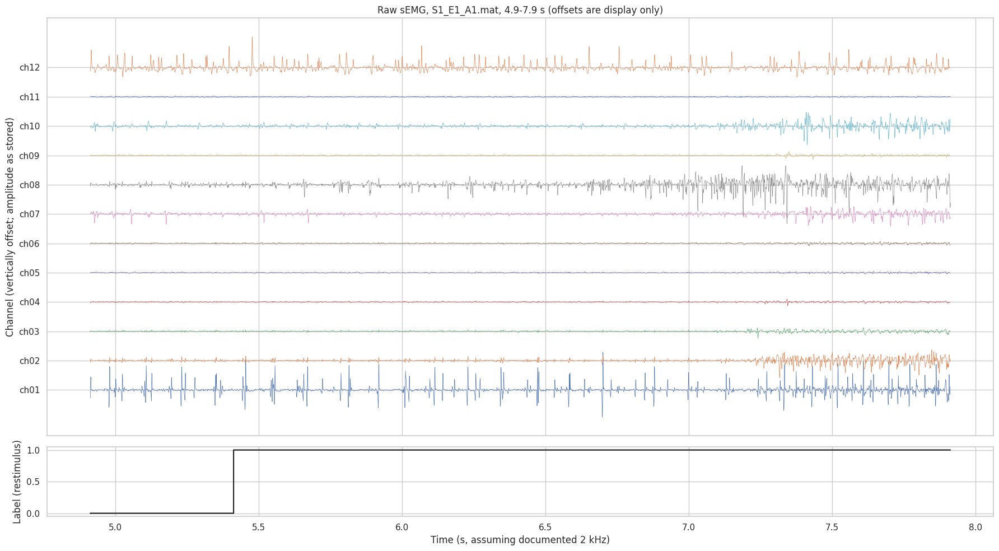

Discontinuity indicator (max |first difference| / median |first difference|) per channel, displayed interval: {'ch01': np.float32(93.8), 'ch02': np.float32(38.5), 'ch03': np.float32(39.9), 'ch04': np.float32(26.3), 'ch05': np.float32(9.1), 'ch06': np.float32(9.1), 'ch07': np.float32(24.2), 'ch08': np.float32(36.5), 'ch09': np.float32(19.7), 'ch10': np.float32(36.6), 'ch11': np.float32(6.3), 'ch12': np.float32(36.8)}
Channels exactly constant in the displayed interval: none

--- Reading of the figure/table ---
WHAT IS SHOWN       : 12 raw channels over a 3 s interval around the first gesture of the recording, with the refined label underneath.
OBSERVED (computed) : Peak-to-peak range per channel 1.81e-05-0.00066; discontinuity indicator 6.3-93.8; label sequence in the interval: [0, 1].
WHY IT MAY MATTER   : Burst amplitude, baseline level and channel-to-channel differences visible here motivate amplitude-aware preprocessing; large jump indicators would flag intervals to inspect. (hypoth

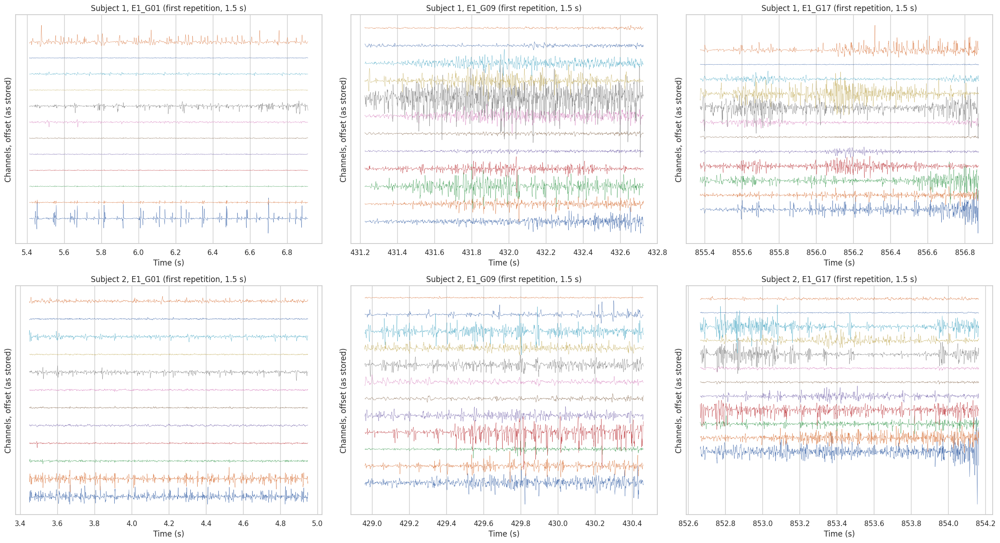


--- Reading of the figure/table ---
WHAT IS SHOWN       : The same 12 channels for three different gesture classes (columns) and two subjects (rows), each over the first 1.5 s of one repetition.
OBSERVED (computed) : Visual comparison only: amplitude patterns differ between panels in the figure; no statistic is derived here.
WHY IT MAY MATTER   : Shows whether gesture-related activation patterns and subject-specific amplitude levels are visible by eye, supporting the use of channel-wise structure. (hypothesis)
CANNOT BE CONCLUDED : Two subjects and three gestures are anecdotal; this cannot establish class separability or the extent of subject differences. 



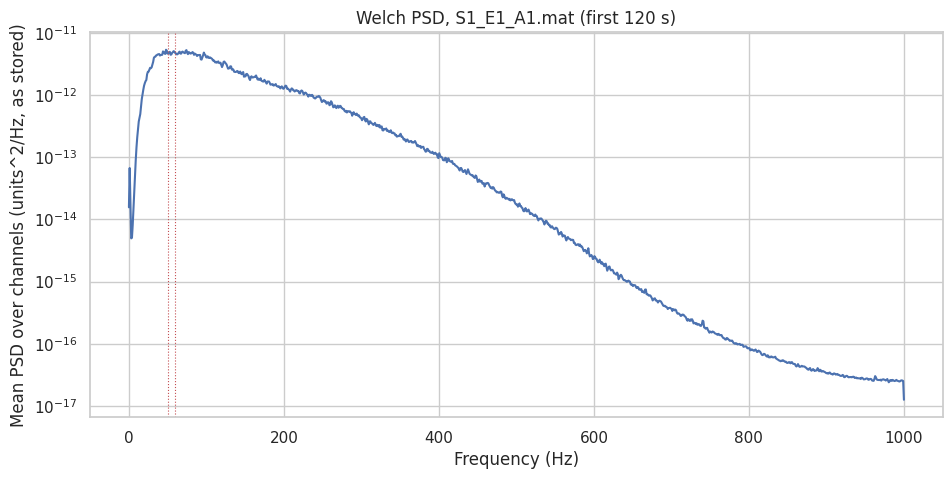

Power share 0-20 Hz: 1.0% | 20-450 Hz: 98.6% | 450-1000 Hz: 0.3%
Spectral-line ratio (peak within +-1.5 Hz / local median) at 50 Hz: 1.09; at 60 Hz: 1.05

--- Reading of the figure/table ---
WHAT IS SHOWN       : Welch power spectral density averaged across channels (red dotted lines: 50/60 Hz mains frequencies).
OBSERVED (computed) : Power share 20-450 Hz = 98.6%; 0-20 Hz = 1.0%; line ratio at 50 Hz = 1.09, at 60 Hz = 1.05 (values near 1 mean no distinct line).
WHY IT MAY MATTER   : Tells whether residual mains interference or low-frequency drift remain in the files, which decides if further filtering is a preprocessing question. (hypothesis)
CANNOT BE CONCLUDED : One recording; it does not document what filtering (if any) was applied in the distributed 'Preproc' files, which is not stated on the documentation page. 

[4.1] PSD of S1_E1_A1.mat: 20-450 Hz holds 98.6% of power; 50 Hz line ratio 1.09, 60 Hz 1.05.


In [23]:
def load_file(file_id):
    m = sio.loadmat(inv.path[file_id], variable_names=["emg", "restimulus", "stimulus", "rerepetition"])
    lab = m["restimulus" if "restimulus" in m else "stimulus"].ravel().astype(int); return np.asarray(m["emg"], dtype=np.float32), lab

rep_fid = int(file_df[file_df.exercise == file_df.exercise.min()].file_id.iloc[0]) if (file_df.exercise == file_df.exercise.min()).any() else 0
emg_r, lab_r = load_file(rep_fid)
sg = seg_df[(seg_df.file_id == rep_fid) & (~seg_df.is_rest)].iloc[0]
t0 = max(0, int(sg.start - 0.5 * FS)); t1 = min(len(emg_r), int(t0 + 3 * FS)); tt = np.arange(t0, t1) / FS
TS = dict(x=emg_r[t0:t1], t=tt, lab=lab_r[t0:t1], file=file_df.file[rep_fid])
off_ = 4 * np.nanstd(emg_r, axis=0).max()
fig, ax = plt.subplots(2, 1, figsize=(18, 10), gridspec_kw={"height_ratios": [6, 1]}, sharex=True)
for j in range(C): ax[0].plot(tt, TS["x"][:, j] + j * off_, lw=.5, label=CH[j])
ax[0].set_yticks([j * off_ for j in range(C)]); ax[0].set_yticklabels(CH); ax[0].set_ylabel("Channel (vertically offset; amplitude as stored)"); ax[0].set_title(f"Raw sEMG, {TS['file']}, {tt[0]:.1f}-{tt[-1]:.1f} s (offsets are display only)")
ax[1].step(tt, TS["lab"], where="post", color="k"); ax[1].set_ylabel("Label (restimulus)"); ax[1].set_xlabel("Time (s, assuming documented 2 kHz)"); fig.tight_layout(); savefig(fig, "4_1_raw_timeseries_representative")

d_ = np.abs(np.diff(TS["x"], axis=0)); jump = d_.max(0) / (np.median(d_, 0) + 1e-12)
print("Discontinuity indicator (max |first difference| / median |first difference|) per channel, displayed interval:", dict(zip(CH, np.round(jump, 1))))
print("Channels exactly constant in the displayed interval:", [CH[j] for j in range(C) if np.ptp(TS["x"][:, j]) == 0] or "none")
interpret("12 raw channels over a 3 s interval around the first gesture of the recording, with the refined label underneath.",
          f"Peak-to-peak range per channel {np.ptp(TS['x'], 0).min():.3g}-{np.ptp(TS['x'], 0).max():.3g}; discontinuity indicator {jump.min():.1f}-{jump.max():.1f}; label sequence in the interval: {np.unique(TS['lab']).tolist()}.",
          "Burst amplitude, baseline level and channel-to-channel differences visible here motivate amplitude-aware preprocessing; large jump indicators would flag intervals to inspect.",
          "A single interval of a single recording; it does not show how typical the pattern is nor what caused any irregularity.")

# comparison across gestures and subjects
subs2 = subjects_all[:2]; ex_c = file_df.exercise.min()
cl3 = list(nr_[nr_.exercise == ex_c].sort_values("label").class_key.iloc[[0, len(nr_[nr_.exercise == ex_c]) // 2, -1]])
fig, axs = plt.subplots(len(subs2), 3, figsize=(22, 6 * len(subs2)), squeeze=False)
for i, s_ in enumerate(subs2):
    fid = int(file_df[(file_df.subject == s_) & (file_df.exercise == ex_c)].file_id.iloc[0]); em, lb = load_file(fid)
    for j, k in enumerate(cl3):
        g_ = seg_df[(seg_df.file_id == fid) & (seg_df.class_key == k)]
        if g_.empty: axs[i, j].set_title(f"S{s_} {k}: not present"); continue
        g0 = g_.iloc[0]; a_, b_ = int(g0.start), int(min(g0.end, g0.start + 1.5 * FS)); tt_ = np.arange(a_, b_) / FS
        o_ = 4 * em.std(0).max()
        for c_ in range(C): axs[i, j].plot(tt_, em[a_:b_, c_] + c_ * o_, lw=.4)
        axs[i, j].set_title(f"Subject {s_}, {k} (first repetition, 1.5 s)"); axs[i, j].set_xlabel("Time (s)"); axs[i, j].set_ylabel("Channels, offset (as stored)"); axs[i, j].set_yticks([])
fig.tight_layout(); savefig(fig, "4_1_raw_timeseries_gesture_subject_grid")
interpret("The same 12 channels for three different gesture classes (columns) and two subjects (rows), each over the first 1.5 s of one repetition.",
          "Visual comparison only: amplitude patterns differ between panels in the figure; no statistic is derived here.",
          "Shows whether gesture-related activation patterns and subject-specific amplitude levels are visible by eye, supporting the use of channel-wise structure.",
          "Two subjects and three gestures are anecdotal; this cannot establish class separability or the extent of subject differences.")

# power spectral density
f_, P = signal.welch(emg_r.astype(np.float64)[: int(120 * FS)].T, fs=FS, nperseg=2048); Pm = P.mean(0)
def band(lo, hi): return Pm[(f_ >= lo) & (f_ < hi)].sum() / Pm.sum()
def line_ratio(f0):
    ctr = (f_ >= f0 - 1.5) & (f_ <= f0 + 1.5); ring = ((f_ >= f0 - 10) & (f_ <= f0 + 10)) & ~((f_ >= f0 - 4) & (f_ <= f0 + 4)); return float(Pm[ctr].max() / np.median(Pm[ring]))
fig, ax = plt.subplots(figsize=(11, 5)); ax.semilogy(f_, Pm); ax.set_xlabel("Frequency (Hz)"); ax.set_ylabel("Mean PSD over channels (units^2/Hz, as stored)"); ax.set_title(f"Welch PSD, {TS['file']} (first 120 s)"); [ax.axvline(v, color="r", ls=":", lw=.8) for v in (50, 60)]
savefig(fig, "4_1_psd_representative")
print(f"Power share 0-20 Hz: {band(0, 20):.1%} | 20-450 Hz: {band(20, 450):.1%} | 450-{FS // 2} Hz: {band(450, FS // 2 + 1):.1%}")
print(f"Spectral-line ratio (peak within +-1.5 Hz / local median) at 50 Hz: {line_ratio(50):.2f}; at 60 Hz: {line_ratio(60):.2f}")
interpret("Welch power spectral density averaged across channels (red dotted lines: 50/60 Hz mains frequencies).",
          f"Power share 20-450 Hz = {band(20, 450):.1%}; 0-20 Hz = {band(0, 20):.1%}; line ratio at 50 Hz = {line_ratio(50):.2f}, at 60 Hz = {line_ratio(60):.2f} (values near 1 mean no distinct line).",
          "Tells whether residual mains interference or low-frequency drift remain in the files, which decides if further filtering is a preprocessing question.",
          "One recording; it does not document what filtering (if any) was applied in the distributed 'Preproc' files, which is not stated on the documentation page.")
note("4.1", f"PSD of {TS['file']}: 20-450 Hz holds {band(20, 450):.1%} of power; 50 Hz line ratio {line_ratio(50):.2f}, 60 Hz {line_ratio(60):.2f}.")

# Sliding-window preparation
make_windows is lazy: it returns window start indices and metadata (never crossing a file, gesture or repetition boundary, and skipping any window containing non-finite samples); gather_windows materialises only the windows needed. Counts for many window/step settings are computed analytically from the segment table, so no memory is spent. All settings are candidate experimental settings, none is claimed optimal.

Self-check passed: 86,442 windows in S1_E1_A1.mat match the segment table; no sampled window crosses a label/repetition boundary: True
Example tensor from gather_windows: (4, 12, 400) (batch, channels, samples)


,win_ms,step_ms,win_samples,step_samples,overlap_pct,n_windows_all,n_windows_nonrest,segments_shorter_than_window,values_per_window,raw_float32_GB_all,raw_float32_GB_nonrest
0,100,10,200,20,90.0,10163477,5714506,43,2400,97.569379,54.859258
1,100,20,200,40,80.0,5087545,2860164,43,2400,48.840432,27.457574
2,100,50,200,100,50.0,2042496,1147727,43,2400,19.607962,11.018179
3,100,100,200,200,0.0,1027533,577368,43,2400,9.864317,5.542733
4,150,10,300,20,93.3,10045496,5655706,45,3600,144.655142,81.442166
5,150,20,300,40,86.7,5028740,2830822,45,3600,72.413856,40.763837
6,150,50,300,100,66.7,2018899,1135967,45,3600,29.072146,16.357925
7,150,100,300,200,33.3,1014963,570359,45,3600,14.615467,8.213170
8,200,10,400,20,95.0,9927527,5596906,47,4800,190.608518,107.460595
9,200,20,400,40,90.0,4969569,2801364,47,4800,95.415725,53.786189


[4.2] Initial setting 200 ms/10 ms: 400 samples/window, 95% overlap, 9,927,527 windows (5,596,906 non-rest), full raw float32 storage 190.6 GB (107.5 GB non-rest) -> windows must be generated lazily.


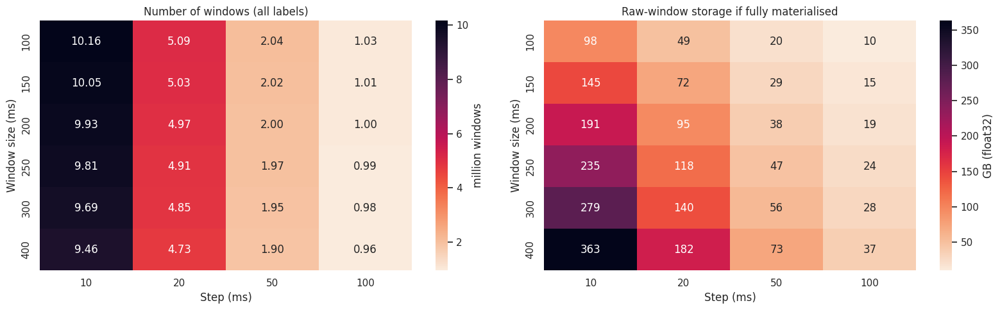


--- Reading of the figure/table ---
WHAT IS SHOWN       : Window count and raw-storage estimate for each window size / step combination.
OBSERVED (computed) : Across the grid, windows range 956,756-10,163,477; storage 9.9-363 GB.
WHY IT MAY MATTER   : Small steps multiply the number of highly overlapping windows (and training time) without adding independent recordings; larger windows reduce the number of valid windows in short segments. (hypothesis)
CANNOT BE CONCLUDED : No setting is shown to give better accuracy; that requires controlled training experiments. 

Windows per subject and exercise:


,count,mean,std,min,25%,50%,75%,max
exercise,,,,,,,,
1,40.0,85543.225,819.264664,83877.0,84613.50,85897.5,86214.00,86708.0
2,40.0,120978.750,1353.447843,118913.0,119364.50,121843.0,122048.25,122414.0
3,40.0,41666.200,41.590926,41559.0,41642.75,41670.0,41684.50,41755.0


Overlapping windows are highly dependent: with a 10 ms step, neighbouring windows share 95% of their samples, so they must never be split randomly across train/test (see Section 5 for a measured demonstration).


In [24]:
def make_windows(emg, lab, rr, Wn, Sn):
    starts, ends = rle(lab, rr); bad = np.r_[0, np.cumsum(~np.isfinite(emg).all(1))]; st_all, meta = [], []
    for si, (s0, e0) in enumerate(zip(starts, ends)):
        if e0 - s0 < Wn: continue
        st = np.arange(s0, e0 - Wn + 1, Sn); st = st[(bad[st + Wn] - bad[st]) == 0]
        st_all.append(st); meta.append(np.c_[np.full(len(st), si), np.full(len(st), lab[s0]), np.full(len(st), rr[s0])])
    if not st_all: return np.zeros(0, int), np.zeros((0, 3), int)
    return np.concatenate(st_all), np.concatenate(meta)           # meta columns: segment index, label, repetition id

def gather_windows(emg, starts, Wn): return np.stack([emg[s0:s0 + Wn].T for s0 in starts]) if len(starts) else np.zeros((0, emg.shape[1], Wn), emg.dtype)

# self-check on the representative file: lazy windows must equal the counts from the segment table
fid = rep_fid; em_, lb_ = load_file(fid); rr_ = sio.loadmat(inv.path[fid], variable_names=["rerepetition"])["rerepetition"].ravel().astype(int)
st_, mt_ = make_windows(em_, lb_, rr_, W, S)
assert len(st_) == int(seg_df[seg_df.file_id == fid].n_win_valid.sum()), "window count mismatch"
# boundary check: every window lies inside one (label, repetition) run
ok = all(len(np.unique(lb_[s0:s0 + W])) == 1 and len(np.unique(rr_[s0:s0 + W])) == 1 for s0 in st_[:: max(1, len(st_) // 500)])
print(f"Self-check passed: {len(st_):,} windows in {file_df.file[fid]} match the segment table; no sampled window crosses a label/repetition boundary: {ok}")
print("Example tensor from gather_windows:", gather_windows(em_, st_[:4], W).shape, "(batch, channels, samples)")

def n_windows(L, Wn, Sn): return np.where(L >= Wn, (L - Wn) // Sn + 1, 0)
Ls = seg_df.length.values; act = ~seg_df.is_rest.values; grid = []
for w_ms in CFG["WIN_GRID_MS"]:
    for s_ms in CFG["STEP_GRID_MS"]:
        Wn, Sn = int(round(w_ms * FS / 1000)), int(round(s_ms * FS / 1000)); nw = n_windows(Ls, Wn, Sn)
        grid.append(dict(win_ms=w_ms, step_ms=s_ms, win_samples=Wn, step_samples=Sn, overlap_pct=round(100 * (1 - Sn / Wn), 1), n_windows_all=int(nw.sum()), n_windows_nonrest=int(nw[act].sum()),
                         segments_shorter_than_window=int((Ls < Wn).sum()), values_per_window=C * Wn, raw_float32_GB_all=nw.sum() * C * Wn * 4 / 1e9, raw_float32_GB_nonrest=nw[act].sum() * C * Wn * 4 / 1e9))
WG = pd.DataFrame(grid); save_table(WG, "4_2_window_configuration_grid"); display(WG)
cur = WG[(WG.win_ms == CFG["WIN_MS"]) & (WG.step_ms == CFG["STEP_MS"])]
if len(cur): c_ = cur.iloc[0]; note("4.2", f"Initial setting {CFG['WIN_MS']} ms/{CFG['STEP_MS']} ms: {int(c_.win_samples)} samples/window, {c_.overlap_pct:.0f}% overlap, {int(c_.n_windows_all):,} windows ({int(c_.n_windows_nonrest):,} non-rest), full raw float32 storage {c_.raw_float32_GB_all:.1f} GB ({c_.raw_float32_GB_nonrest:.1f} GB non-rest) -> windows must be generated lazily.")
fig, ax = plt.subplots(1, 2, figsize=(16, 5))
sns.heatmap(WG.pivot(index="win_ms", columns="step_ms", values="n_windows_all") / 1e6, annot=True, fmt=".2f", cmap="rocket_r", ax=ax[0], cbar_kws={"label": "million windows"}); ax[0].set_title("Number of windows (all labels)"); ax[0].set_xlabel("Step (ms)"); ax[0].set_ylabel("Window size (ms)")
sns.heatmap(WG.pivot(index="win_ms", columns="step_ms", values="raw_float32_GB_all"), annot=True, fmt=".0f", cmap="rocket_r", ax=ax[1], cbar_kws={"label": "GB (float32)"}); ax[1].set_title("Raw-window storage if fully materialised"); ax[1].set_xlabel("Step (ms)"); ax[1].set_ylabel("Window size (ms)")
fig.tight_layout(); savefig(fig, "4_2_window_grid")
interpret("Window count and raw-storage estimate for each window size / step combination.",
          f"Across the grid, windows range {WG.n_windows_all.min():,}-{WG.n_windows_all.max():,}; storage {WG.raw_float32_GB_all.min():.1f}-{WG.raw_float32_GB_all.max():.0f} GB.",
          "Small steps multiply the number of highly overlapping windows (and training time) without adding independent recordings; larger windows reduce the number of valid windows in short segments.",
          "No setting is shown to give better accuracy; that requires controlled training experiments.")
wpc = seg_df[~seg_df.is_rest].pivot_table(index="subject", columns="class_key", values="n_win_valid", aggfunc="sum", fill_value=0); save_table(wpc.reset_index(), "4_2_windows_per_subject_class")
wps = seg_df.groupby(["subject", "exercise"]).n_win_valid.sum().unstack(fill_value=0); save_table(wps.reset_index(), "4_2_windows_per_subject_exercise")
print("Windows per subject and exercise:"); display(wps.describe().T)
print("Overlapping windows are highly dependent: with a 10 ms step, neighbouring windows share 95% of their samples, so they must never be split randomly across train/test (see Section 5 for a measured demonstration).")

# GNN graph-construction exploration
Nodes = the 12 EMG channels (static node set). No reliable sensor coordinates are available in the files (documentation only describes the ring of channels 1–8 and the muscle sites of 9–12), so no spatial KNN is built. Instead:


* KNN graph — neighbours = the K channels with highest absolute correlation (distance = 1 − |r|) computed from training subjects only; undirected by union (edge if either node lists the other).
* Fully connected graph — all distinct pairs, undirected, no self-loops (self-loops are left to the model layer).
* Correlation graph — edge when |r| ≥ threshold (absolute) or r ≥ threshold (signed); unweighted or weighted by |r|.
* K and the threshold are scanned, not selected: choosing them belongs to validation experiments inside the training procedure.


,graph,nodes,edges,density,deg_min,deg_mean,deg_max,deg_std,components,largest_component,isolated_nodes,weighted_variant_available,directed,static,K,threshold
0,fully_connected,12,66,1.0000,11,11.00,11,0.00,1,12,0,True,False,True,NaN,NaN
1,knn_corr_distance,12,19,0.2879,2,3.17,6,1.40,1,12,0,True,False,True,2.0,NaN
2,knn_corr_distance,12,26,0.3939,3,4.33,7,1.43,1,12,0,True,False,True,3.0,NaN
3,knn_corr_distance,12,35,0.5303,4,5.83,10,1.91,1,12,0,True,False,True,4.0,NaN
4,knn_corr_distance,12,41,0.6212,5,6.83,11,1.82,1,12,0,True,False,True,5.0,NaN
5,knn_corr_distance,12,47,0.7121,6,7.83,11,1.62,1,12,0,True,False,True,6.0,NaN
6,correlation_abs,12,39,0.5909,2,6.50,11,2.40,1,12,0,True,False,True,NaN,0.1
7,correlation_signed,12,39,0.5909,2,6.50,11,2.40,1,12,0,True,False,True,NaN,0.1
8,correlation_abs,12,22,0.3333,0,3.67,7,2.17,3,10,2,True,False,True,NaN,0.2
9,correlation_signed,12,22,0.3333,0,3.67,7,2.17,3,10,2,True,False,True,NaN,0.2


[4.3] Graph source: rms_envelope correlation from train subjects. Fully connected: 66 edges. KNN (K=2..6): 19/26/35/41/47 edges. Correlation(abs) edges at thresholds 0.1:39, 0.3:8, 0.5:0, 0.7:0, 0.9:0.


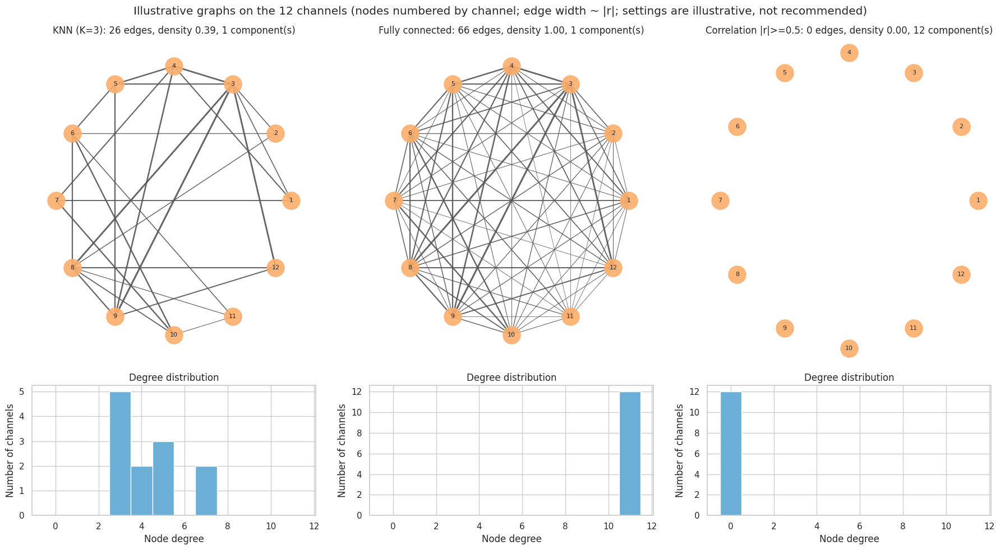

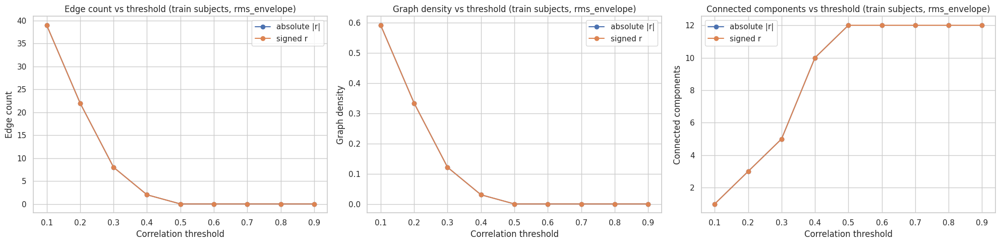


--- Reading of the figure/table ---
WHAT IS SHOWN       : Left: illustrative KNN / fully connected / thresholded-correlation graphs with degree histograms. Right figure: how edge count, density and components change with the threshold.
OBSERVED (computed) : Correlation-graph edges range 0-39 over thresholds 0.1-0.9 (fully connected = 66); the first threshold at which the graph splits into >1 component: 0.2.
WHY IT MAY MATTER   : Topology is sensitive to the threshold; fully connected and low-threshold graphs approach the same dense structure, whereas KNN guarantees a minimum degree. (hypothesis)
CANNOT BE CONCLUDED : Structure alone cannot show which graph yields better gesture classification; that needs GNN training with each graph on the same subject-independent splits. 

Per-window raw-signal correlation graphs (200 ms, 1000 random train windows) vs the static rms_envelope graph:


,threshold,static_edges,window_edges_mean,window_edges_std
0,0.1,39,32.261,7.348121
1,0.2,22,14.046,7.562532
2,0.3,8,6.540,5.783632
3,0.4,2,3.396,4.098193
4,0.5,0,1.758,2.725699
5,0.6,0,0.832,1.692269
6,0.7,0,0.358,0.976645
7,0.8,0,0.107,0.442211
8,0.9,0,0.013,0.129734


[4.3] Window-dependent raw-correlation graphs fluctuate: at threshold 0.5 edges per window = 1.8 +- 2.7 vs static graph 0.
[4.3] KNN(K=3) edge-set Jaccard between each train subject's own RMS-envelope graph and the pooled train graph: median 0.35 (min 0.23); lower values would mean a static pooled graph fits some subjects poorly.
Example edge_index (both directions) shapes: {'KNN (K=3)': (2, 52), 'Fully connected': (2, 132), 'Correlation |r|>=0.5': (2, 0)}


In [25]:
def knn_graph(sim, k):
    A = np.abs(sim).copy(); np.fill_diagonal(A, -np.inf); nn = np.argsort(-A, axis=1)[:, :k]
    G = nx.Graph(); G.add_nodes_from(range(C))
    for i in range(C):
        for j in nn[i]: G.add_edge(i, int(j), weight=float(abs(sim[i, int(j)])))
    return G
def full_graph(sim):
    G = nx.Graph(); G.add_nodes_from(range(C)); [G.add_edge(i, j, weight=float(abs(sim[i, j]))) for i in range(C) for j in range(i + 1, C)]; return G
def corr_graph(sim, thr, signed=False):
    G = nx.Graph(); G.add_nodes_from(range(C))
    for i in range(C):
        for j in range(i + 1, C):
            v = sim[i, j] if signed else abs(sim[i, j])
            if v >= thr: G.add_edge(i, j, weight=float(abs(sim[i, j])))
    return G
def gmetrics(G, name, **p):
    deg = np.array([d for _, d in G.degree()]); comps = list(nx.connected_components(G))
    return dict(graph=name, **p, nodes=G.number_of_nodes(), edges=G.number_of_edges(), density=round(nx.density(G), 4), deg_min=int(deg.min()), deg_mean=round(deg.mean(), 2), deg_max=int(deg.max()),
                deg_std=round(deg.std(), 2), components=len(comps), largest_component=max(map(len, comps)), isolated_nodes=int((deg == 0).sum()), weighted_variant_available=True, directed=False, static=True)

rows_g = [gmetrics(full_graph(SIM), "fully_connected")]
for k in CFG["KNN_K_LIST"]: rows_g.append(gmetrics(knn_graph(SIM, k), "knn_corr_distance", K=k))
for t in CFG["CORR_THR_LIST"]:
    rows_g.append(gmetrics(corr_graph(SIM, t, False), "correlation_abs", threshold=t)); rows_g.append(gmetrics(corr_graph(SIM, t, True), "correlation_signed", threshold=t))
GM = pd.DataFrame(rows_g); save_table(GM, "4_3_graph_structure_comparison"); display(GM)
fc_edges = C * (C - 1) // 2
note("4.3", f"Graph source: {CFG['GRAPH_SIM']} correlation from train subjects. Fully connected: {fc_edges} edges. KNN (K={CFG['KNN_K_LIST'][0]}..{CFG['KNN_K_LIST'][-1]}): " + "/".join(str(int(GM[(GM.graph == 'knn_corr_distance') & (GM.K == k)].edges.iloc[0])) for k in CFG['KNN_K_LIST']) + " edges. Correlation(abs) edges at thresholds " + ", ".join(f"{t}:{int(GM[(GM.graph == 'correlation_abs') & (GM.threshold == t)].edges.iloc[0])}" for t in CFG['CORR_THR_LIST'][::2]) + ".")

# illustrative graphs (NOT recommended settings)
K_ill = CFG["KNN_K_LIST"][1] if len(CFG["KNN_K_LIST"]) > 1 else CFG["KNN_K_LIST"][0]; T_ill = CFG["CORR_THR_LIST"][len(CFG["CORR_THR_LIST"]) // 2]
GR = {f"KNN (K={K_ill})": knn_graph(SIM, K_ill), "Fully connected": full_graph(SIM), f"Correlation |r|>={T_ill}": corr_graph(SIM, T_ill)}
pos = nx.circular_layout(nx.complete_graph(C))
fig, ax = plt.subplots(2, 3, figsize=(18, 10), gridspec_kw={"height_ratios": [3, 1.2]})
for j, (nm, G) in enumerate(GR.items()):
    ws = [G[u][v]["weight"] for u, v in G.edges()] or [0]
    nx.draw_networkx(G, pos, ax=ax[0, j], node_color="#fdae6b", node_size=500, font_size=8, labels={i: str(i + 1) for i in range(C)}, width=[0.5 + 4 * w for w in ws], edge_color="#555555", alpha=.9)
    ax[0, j].set_title(f"{nm}: {G.number_of_edges()} edges, density {nx.density(G):.2f}, {nx.number_connected_components(G)} component(s)"); ax[0, j].axis("off")
    d = [dd for _, dd in G.degree()]; ax[1, j].hist(d, bins=np.arange(-.5, C + .5, 1), color="#6baed6"); ax[1, j].set_xlabel("Node degree"); ax[1, j].set_ylabel("Number of channels"); ax[1, j].set_title("Degree distribution")
fig.suptitle("Illustrative graphs on the 12 channels (nodes numbered by channel; edge width ~ |r|; settings are illustrative, not recommended)"); fig.tight_layout(); savefig(fig, "4_3_graph_topologies")

fig, ax = plt.subplots(1, 3, figsize=(20, 5)); ths = CFG["CORR_THR_LIST"]
for sg_, lbl in ((False, "absolute |r|"), (True, "signed r")):
    d = GM[GM.graph == ("correlation_signed" if sg_ else "correlation_abs")]
    ax[0].plot(d.threshold, d.edges, marker="o", label=lbl); ax[1].plot(d.threshold, d.density, marker="o", label=lbl); ax[2].plot(d.threshold, d.components, marker="o", label=lbl)
for a, t_ in zip(ax, ["Edge count", "Graph density", "Connected components"]): a.set_xlabel("Correlation threshold"); a.set_ylabel(t_); a.set_title(f"{t_} vs threshold (train subjects, {CFG['GRAPH_SIM']})"); a.legend()
fig.tight_layout(); savefig(fig, "4_3_threshold_sweep")
e_lo, e_hi = GM[GM.graph == "correlation_abs"].edges.max(), GM[GM.graph == "correlation_abs"].edges.min()
interpret("Left: illustrative KNN / fully connected / thresholded-correlation graphs with degree histograms. Right figure: how edge count, density and components change with the threshold.",
          f"Correlation-graph edges range {e_hi}-{e_lo} over thresholds {ths[0]}-{ths[-1]} (fully connected = {fc_edges}); the first threshold at which the graph splits into >1 component: {next((t for t in ths if nx.number_connected_components(corr_graph(SIM, t)) > 1), 'none in scanned range')}.",
          "Topology is sensitive to the threshold; fully connected and low-threshold graphs approach the same dense structure, whereas KNN guarantees a minimum degree.",
          "Structure alone cannot show which graph yields better gesture classification; that needs GNN training with each graph on the same subject-independent splits.")

# window-dependent behaviour (does a static graph describe individual windows?)
rng_g = np.random.default_rng(SEED); tr_idx = np.flatnonzero(mask_tr); pick = rng_g.choice(tr_idx, size=min(1000, len(tr_idx)), replace=False)
Rw = np.stack([np.nan_to_num(np.corrcoef(win_raw[i])) for i in pick])
wd = pd.DataFrame([dict(threshold=t, static_edges=int(((np.abs(SIM[np.triu_indices(C, 1)])) >= t).sum()), window_edges_mean=float((np.abs(Rw[:, np.triu_indices(C, 1)[0], np.triu_indices(C, 1)[1]]) >= t).sum(1).mean()),
                        window_edges_std=float((np.abs(Rw[:, np.triu_indices(C, 1)[0], np.triu_indices(C, 1)[1]]) >= t).sum(1).std())) for t in ths])
save_table(wd, "4_3_window_dependent_edge_counts"); print(f"Per-window raw-signal correlation graphs (200 ms, {len(pick)} random train windows) vs the static {CFG['GRAPH_SIM']} graph:"); display(wd)
note("4.3", f"Window-dependent raw-correlation graphs fluctuate: at threshold {ths[len(ths)//2]} edges per window = {wd.window_edges_mean.iloc[len(ths)//2]:.1f} +- {wd.window_edges_std.iloc[len(ths)//2]:.1f} vs static graph {int(wd.static_edges.iloc[len(ths)//2])}.")

# cross-subject stability of the KNN structure (train subjects)
ref = {tuple(sorted(e)) for e in knn_graph(SIM, K_ill).edges()}; jac = []
for s_ in sorted(TRAIN):
    m_ = (win_meta.subject.values == s_)
    if m_.sum() >= 15:
        Rs = np.nan_to_num(np.corrcoef(win_feat["RMS"][m_], rowvar=False)); np.fill_diagonal(Rs, 1); es = {tuple(sorted(e)) for e in knn_graph(Rs, K_ill).edges()}; jac.append(dict(subject=s_, jaccard_vs_pooled=len(ref & es) / len(ref | es)))
jac = pd.DataFrame(jac); save_table(jac, "4_3_knn_edge_stability_across_train_subjects")
if len(jac): note("4.3", f"KNN(K={K_ill}) edge-set Jaccard between each train subject's own RMS-envelope graph and the pooled train graph: median {jac.jaccard_vs_pooled.median():.2f} (min {jac.jaccard_vs_pooled.min():.2f}); lower values would mean a static pooled graph fits some subjects poorly.")
def to_edge_index(G): e = np.array(list(G.edges()), dtype=np.int64).T if G.number_of_edges() else np.zeros((2, 0), np.int64); return np.concatenate([e, e[::-1]], 1)   # both directions for message passing
print("Example edge_index (both directions) shapes:", {k: to_edge_index(G).shape for k, G in GR.items()})

# Node-feature preparation
Two candidate node-feature tensors per window (shapes below are computed). Raw windows are the primary proposed input; handcrafted features are an optional comparison. A temporal CNN encoder applied independently (shared weights) to each channel's 1-D signal maps (B, 12, W) → (B, 12, d) node embeddings, followed by graph message passing; the shape check below uses random weights — it is not training and says nothing about performance.

In [26]:
X_raw = win_raw; X_hand = np.stack([win_feat[f] for f in FEATS], -1)
print(f"Raw-window node features   : (N, nodes, samples)  = {X_raw.shape}   [per-node vector length {W}]")
print(f"Handcrafted node features  : (N, nodes, features) = {X_hand.shape}   [features: {FEATS}; log/standardise with train-fitted scalers]")
print(f"CNN/LSTM baselines see the same windows as: CNN (N, 1, {C}, {W}) or (N, {C}, {W}); LSTM (N, {W}, {C}) (time-major)")
if HAS_TORCH:
    import torch, torch.nn as nn
    torch.manual_seed(SEED)
    class TemporalEncoder(nn.Module):
        def __init__(self, d=32):
            super().__init__(); self.net = nn.Sequential(nn.Conv1d(1, 16, 7, stride=2, padding=3), nn.ReLU(), nn.Conv1d(16, d, 5, stride=2, padding=2), nn.ReLU(), nn.AdaptiveAvgPool1d(1))
        def forward(self, x):                      # x: (B, nodes, samples)
            B, N, T = x.shape; return self.net(x.reshape(B * N, 1, T)).reshape(B, N, -1)
    xb = torch.tensor(X_raw[:8]); H = TemporalEncoder()(xb)
    for nm, G in GR.items():
        A = torch.tensor(nx.to_numpy_array(G, weight=None), dtype=torch.float32) + torch.eye(C); A = A / A.sum(1, keepdim=True)   # self-loops added here, in the model layer
        print(f"{nm:>24}: encoder {tuple(xb.shape)} -> {tuple(H.shape)} -> one message-passing step (A_hat @ H) -> {tuple((A @ H).shape)} | graph-level readout (mean over nodes) -> {tuple((A @ H).mean(1).shape)}")
else: print("PyTorch not available: shape check skipped (shapes above are exact).")
note("4.4", f"Raw node tensor {X_raw.shape}; handcrafted node tensor {X_hand.shape}; graph-level readout feeds a {len(classes_nonrest)}-way (non-rest) classifier per the exercise design (to be decided).")

Raw-window node features   : (N, nodes, samples)  = (16640, 12, 400)   [per-node vector length 400]
Handcrafted node features  : (N, nodes, features) = (16640, 12, 5)   [features: ['RMS', 'MAV', 'WL', 'ZC', 'VAR']; log/standardise with train-fitted scalers]
CNN/LSTM baselines see the same windows as: CNN (N, 1, 12, 400) or (N, 12, 400); LSTM (N, 400, 12) (time-major)
               KNN (K=3): encoder (8, 12, 400) -> (8, 12, 32) -> one message-passing step (A_hat @ H) -> (8, 12, 32) | graph-level readout (mean over nodes) -> (8, 32)
         Fully connected: encoder (8, 12, 400) -> (8, 12, 32) -> one message-passing step (A_hat @ H) -> (8, 12, 32) | graph-level readout (mean over nodes) -> (8, 32)
    Correlation |r|>=0.5: encoder (8, 12, 400) -> (8, 12, 32) -> one message-passing step (A_hat @ H) -> (8, 12, 32) | graph-level readout (mean over nodes) -> (8, 32)
[4.4] Raw node tensor (16640, 12, 400); handcrafted node tensor (16640, 12, 5); graph-level readout feeds a 49-way (non-rest) 

# SECTION H — Interactive visualisations (Plotly)
Each figure is shown inline and saved as a standalone HTML file in outputs/interactive/. To open a file: download it from the Kaggle Output tab and double-click it (default PLOTLY_JS="cdn" keeps files small but needs internet to load the Plotly library; set PLOTLY_JS=True in CFG for fully self-contained files). Interactions: hover for details, drag to zoom/pan (double-click resets), click legend entries to hide/show categories, use the dropdown menus where present. Subsampling used in each figure is stated in its title.

In [27]:
#helpers for compact grids (3 panels per row)
def cbar_for(fig, r, c, title):
    sp = fig.get_subplot(r, c); xd, yd = sp.xaxis.domain, sp.yaxis.domain
    return dict(title=dict(text=title, font=dict(size=9)), x=xd[1] + 0.004, y=(yd[0] + yd[1]) / 2, len=(yd[1] - yd[0]) * 0.9, yanchor="middle", thickness=8, tickfont=dict(size=8))
def grid_pos(n, ncols=3): return [(i // ncols + 1, i % ncols + 1) for i in range(n)]

#H1 raw time series (click legend entries to hide/show channels; label strip underneath)
fig = make_subplots(rows=C + 1, cols=1, shared_xaxes=True, vertical_spacing=0.008, row_heights=[1] * C + [1.4])
for j in range(C):
    fig.add_trace(go.Scatter(x=TS["t"], y=TS["x"][:, j], mode="lines", name=CH[j], line=dict(width=.8), hovertemplate=f"{CH[j]}<br>t=%{{x:.4f}} s<br>amp=%{{y:.4g}}<extra></extra>"), row=j + 1, col=1)
    fig.update_yaxes(title_text=CH[j], title_font=dict(size=8), tickfont=dict(size=7), row=j + 1, col=1)
fig.add_trace(go.Scatter(x=TS["t"], y=TS["lab"], mode="lines", line_shape="hv", name="label (restimulus)", line=dict(color="black"), hovertemplate="label=%{y}<extra></extra>"), row=C + 1, col=1)
fig.update_yaxes(title_text="label", row=C + 1, col=1); fig.update_xaxes(title_text="Time (s; documented 2 kHz)", row=C + 1, col=1)
fig.update_layout(height=850, title=f"H1. Raw sEMG, {TS['file']} (3 s window; click legend to hide channels; amplitude as stored)", hovermode="x unified", margin=dict(t=70))
fig.show(); save_html(fig, "H1_raw_timeseries")
print("Reading: shows 12 simultaneous channels and the gesture label. Observed: label values in view =", np.unique(TS["lab"]).tolist(), f"; per-channel peak-to-peak {np.ptp(TS['x'], 0).min():.3g}-{np.ptp(TS['x'], 0).max():.3g}. Matters because it lets you inspect bursts/baseline by channel; it is a single interval, not a statistic.")

#H2 amplitude distributions: all / rest / active side by side (shared y-axis)
states = {"all samples": np.ones(len(samp_df), bool), "rest only": (samp_df.label == 0).values, "active only (label>0)": (samp_df.label > 0).values}
fig = make_subplots(rows=1, cols=3, shared_yaxes=True, horizontal_spacing=0.03, subplot_titles=[f"{sn} (<=5000 random samples)" for sn in states])
for j, (sn, m) in enumerate(states.items(), start=1):
    sub = samp_df[m]; sub = sub.sample(min(len(sub), 5000), random_state=SEED)
    for c in CH: fig.add_trace(go.Box(y=sub[c], name=c, boxpoints="outliers", marker_size=2, showlegend=False, hovertemplate=f"{c}<br>%{{y:.4g}}<extra></extra>"), row=1, col=j)
    fig.update_xaxes(title_text="EMG channel", tickangle=-60, tickfont=dict(size=8), row=1, col=j)
fig.update_yaxes(title_text="Amplitude (as stored; unit unverified)", row=1, col=1)
fig.update_layout(title="H2. Amplitude distribution per channel - all / rest / active samples (same y-axis for comparison)", height=480, margin=dict(t=90))
fig.show(); save_html(fig, "H2_channel_amplitude_distributions")
print(f"Reading: boxes per channel for all/rest/active samples. Observed: median |amplitude| active/rest ratio {ra.get(True, np.nan) / ra.get(False, np.nan):.2f}; pooled RMS max/min over channels {rmsr:.1f}. Matters for choosing per-channel scaling; samples are a random subset, so tails are approximate.")

#H3 class counts: windows / samples / segments side by side (click legend to hide an exercise)
metrics_ = {"windows (200ms/10ms)": "n_windows", "raw samples": "n_samples", "segments (repetition instances)": "n_segments"}
E_list = sorted(cls.exercise.unique())
fig = make_subplots(rows=1, cols=3, horizontal_spacing=0.06, subplot_titles=list(metrics_))
for j, (ml, mc) in enumerate(metrics_.items(), start=1):
    for e in E_list:
        d = cls[cls.exercise == e]
        fig.add_trace(go.Bar(x=d.class_key, y=d[mc], name=f"Exercise {e}", legendgroup=f"E{e}", showlegend=(j == 1), marker_color=cmap.get(e),
                             customdata=np.c_[d.n_subjects, d.n_segments, d.n_repetition_ids, d.pct_samples.round(2)],
                             hovertemplate="%{x}<br>value=%{y:,}<br>subjects=%{customdata[0]}, segments=%{customdata[1]}, repetition ids=%{customdata[2]}<br>%% of samples=%{customdata[3]}<extra></extra>"), row=1, col=j)
    fig.update_xaxes(title_text="Class key", tickangle=-90, tickfont=dict(size=7), row=1, col=j); fig.update_yaxes(title_text=ml, row=1, col=j)
fig.update_layout(title="H3. Class counts by three metrics (REST included; click legend to hide an exercise)", height=520, margin=dict(t=90))
fig.show(); save_html(fig, "H3_class_counts")
print(f"Reading: counts per class for three metrics. Observed: non-rest imbalance ratio windows {imb_w:.2f}, segments {imb_seg:.2f}; REST = {rest_share_s:.1%} of samples. Matters for metric choice (Macro-F1); window counts are overlapping and not independent.")

# H4 subject-wise statistics: 3 heatmaps per row
stats_ = {"RMS": "rms", "Std": "std", "Skewness": "skew", "Excess kurtosis": "kurt_excess", "MAV": "mav"}
nr_h4 = math.ceil(len(stats_) / 3)
fig = make_subplots(rows=nr_h4, cols=3, horizontal_spacing=0.09, vertical_spacing=0.12, subplot_titles=[f"{l} per subject and channel" for l in stats_])
for (lbl, col), (r_, c_) in zip(stats_.items(), grid_pos(len(stats_))):
    pvt = B2.pivot(index="subject", columns="channel", values=col)
    fig.add_trace(go.Heatmap(z=pvt.values, x=list(pvt.columns), y=[str(s) for s in pvt.index], colorscale="Viridis", colorbar=cbar_for(fig, r_, c_, lbl), hovertemplate="subject %{y}<br>%{x}<br>" + lbl + "=%{z:.4g}<extra></extra>"), row=r_, col=c_)
    fig.update_yaxes(type="category", tickfont=dict(size=7), title_text="Subject ID", row=r_, col=c_); fig.update_xaxes(tickangle=-60, tickfont=dict(size=8), row=r_, col=c_)
fig.update_layout(title="H4. Subject-wise signal statistics (rows = subjects, columns = channels)", height=470 * nr_h4 + 40, margin=dict(t=90, r=110))
fig.show(); save_html(fig, "H4_subject_channel_statistics")
print(f"Reading: how each subject differs per channel for five statistics. Observed: per-channel RMS max/min across subjects, median {subj_ratio.median():.1f}. Matters for cross-subject shift (Objective 2); cannot reveal causes.")

#H5 correlation heatmaps: 3 per row, one shared colour scale
mats = {"Pearson raw (all subjects)": R_raw_all, "Pearson raw (TRAIN subjects)": R_raw_train, "Pearson RMS-envelope (all subjects)": R_env_all, "Pearson RMS-envelope (TRAIN subjects)": R_env_train, "Spearman raw (sample)": R_sp}
nr_h5 = math.ceil(len(mats) / 3)
fig = make_subplots(rows=nr_h5, cols=3, horizontal_spacing=0.06, vertical_spacing=0.14, subplot_titles=list(mats))
for k_, ((nm, M), (r_, c_)) in enumerate(zip(mats.items(), grid_pos(len(mats)))):
    fig.add_trace(go.Heatmap(z=M, x=CH, y=CH, zmin=-1, zmax=1, colorscale="RdBu", reversescale=True, showscale=(k_ == len(mats) - 1), colorbar=dict(title="r", x=1.02, y=0.5, len=0.8, thickness=10),
                             hovertemplate="%{y} vs %{x}<br>r=%{z:.3f}<extra></extra>"), row=r_, col=c_)
    fig.update_yaxes(autorange="reversed", tickfont=dict(size=8), row=r_, col=c_); fig.update_xaxes(tickangle=-60, tickfont=dict(size=8), row=r_, col=c_)
fig.update_layout(title="H5. Channel-to-channel correlation under five definitions (shared colour scale -1..1)", height=440 * nr_h5 + 60, margin=dict(t=90, r=110))
fig.show(); save_html(fig, "H5_channel_correlation")
print(f"Reading: five channel-correlation definitions. Observed: median off-diagonal |r| raw {np.median(off(R_raw_all)):.3f}, envelope {np.median(off(R_env_all)):.3f}. Matters because graph edges depend on which definition and which subjects are used; correlation is not physiological connectivity.")

Reading: shows 12 simultaneous channels and the gesture label. Observed: label values in view = [0, 1] ; per-channel peak-to-peak 1.81e-05-0.00066. Matters because it lets you inspect bursts/baseline by channel; it is a single interval, not a statistic.


Reading: boxes per channel for all/rest/active samples. Observed: median |amplitude| active/rest ratio 2.52; pooled RMS max/min over channels 11.8. Matters for choosing per-channel scaling; samples are a random subset, so tails are approximate.


Reading: counts per class for three metrics. Observed: non-rest imbalance ratio windows 1.85, segments 1.00; REST = 43.9% of samples. Matters for metric choice (Macro-F1); window counts are overlapping and not independent.


Reading: how each subject differs per channel for five statistics. Observed: per-channel RMS max/min across subjects, median 22.5. Matters for cross-subject shift (Objective 2); cannot reveal causes.


Reading: five channel-correlation definitions. Observed: median off-diagonal |r| raw 0.007, envelope 0.096. Matters because graph edges depend on which definition and which subjects are used; correlation is not physiological connectivity.


In [28]:
#H6 PCA scatter (handcrafted features; PCA fitted on TRAIN subjects)
cap = 15000; sel = np.sort(np.random.default_rng(SEED).choice(len(win_meta), size=min(cap, len(win_meta)), replace=False))
dfp = win_meta.iloc[sel].reset_index(drop=True).assign(PC1=Zft[sel, 0], PC2=Zft[sel, 1], PC3=Zft[sel, 2])
ev = pca_ft.explained_variance_ratio_
order = sorted(dfp.class_key.unique()); ex_of = {k: int(k[1]) for k in order}; exs_h = sorted(set(ex_of.values()))
# H6a: one panel per exercise (3 per row) + a wide panel with all exercises underneath; legend click hides a class in every panel
n_ex_rows = math.ceil(len(exs_h) / 3)
specs = [[{} for _ in range(3)] for _ in range(n_ex_rows)] + [[{"colspan": 3}, None, None]]
panels = [(1 + i // 3, 1 + i % 3, e) for i, e in enumerate(exs_h)] + [(n_ex_rows + 1, 1, "all")]
fig = make_subplots(rows=n_ex_rows + 1, cols=3, specs=specs, horizontal_spacing=0.05, vertical_spacing=0.1, subplot_titles=[f"Exercise {e}" for e in exs_h] + ["All exercises together"])
seen = set()
for r_, c_, scope in panels:
    for k in [k for k in order if scope == "all" or ex_of[k] == scope]:
        d = dfp[dfp.class_key == k]
        fig.add_trace(go.Scattergl(x=d.PC1, y=d.PC2, mode="markers", name=k, legendgroup=k, showlegend=(k not in seen), marker=dict(size=4, opacity=.7), customdata=np.c_[d.subject, d.rerep, d.split],
                                   hovertemplate=k + "<br>subject %{customdata[0]}, repetition %{customdata[1]}, split %{customdata[2]}<br>PC1=%{x:.2f}, PC2=%{y:.2f}<extra></extra>"), row=r_, col=c_); seen.add(k)
    fig.update_xaxes(title_text=f"PC1 ({ev[0]:.1%} var)", row=r_, col=c_); fig.update_yaxes(title_text=f"PC2 ({ev[1]:.1%} var)", row=r_, col=c_)
fig.update_layout(title=f"H6a. PCA of handcrafted features by class (fit on train subjects; {len(dfp):,} random windows)", height=420 * (n_ex_rows + 1) + 80, legend=dict(font=dict(size=8), itemsizing="constant"), margin=dict(t=90))
fig.show(); save_html(fig, "H6a_pca_by_class")

fig = go.Figure()
for s_ in sorted(dfp.subject.unique()):
    d = dfp[dfp.subject == s_]; fig.add_trace(go.Scattergl(x=d.PC1, y=d.PC2, mode="markers", name=f"S{s_} ({d.split.iloc[0]})", marker=dict(size=5, opacity=.7), customdata=np.c_[d.class_key, d.rerep], hovertemplate=f"subject {s_}<br>%{{customdata[0]}}, repetition %{{customdata[1]}}<extra></extra>"))
fig.update_layout(title="H6b. Same PCA coloured by subject (click legend to isolate subjects)", xaxis_title=f"PC1 ({ev[0]:.1%} var)", yaxis_title=f"PC2 ({ev[1]:.1%} var)", height=560, margin=dict(t=70))
fig.show(); save_html(fig, "H6b_pca_by_subject")
d3 = dfp.sample(min(6000, len(dfp)), random_state=SEED)
fig = px.scatter_3d(d3, x="PC1", y="PC2", z="PC3", color="class_key", hover_data=["subject", "exercise", "rerep", "split"], opacity=.7, title=f"H6c. 3D PCA of handcrafted features ({len(d3):,} random windows; cumulative variance {ev.sum():.1%})")
fig.update_traces(marker_size=3); fig.update_layout(height=600, margin=dict(t=70)); fig.show(); save_html(fig, "H6c_pca3d_by_class")
print("Reading: interactive PCA of window feature vectors. Observed silhouettes (Euclidean, 2-D) in Section G summary table; PC1-3 explain", np.round(ev, 3).tolist(), ". Matters for judging whether classes or subjects dominate the leading linear directions; it proves nothing about classifier performance.")

#H7 class-wise feature distributions: rows = 5 features, columns = exercises (3 per row)
H7_CHANNELS = []          # optional: e.g. ["ch01", "ch09"] adds one extra figure per channel; default = mean over the 12 channels
exs_7 = sorted(win_meta.exercise.unique())
for chsel in [None] + list(H7_CHANNELS):
    lab_ch = "mean over channels" if chsel is None else chsel
    fig = make_subplots(rows=len(FEATS), cols=len(exs_7), shared_xaxes="columns", vertical_spacing=0.035, horizontal_spacing=0.04, subplot_titles=[f"{f} | exercise {e}" for f in FEATS for e in exs_7])
    for i, f in enumerate(FEATS, start=1):
        for j, e in enumerate(exs_7, start=1):
            dmask = (win_meta.exercise.values == e); kk = win_meta.class_key.values[dmask]; cls_e = sorted(set(kk))
            vals = win_feat[f][dmask]; col = vals.mean(1) if chsel is None else vals[:, CH.index(chsel)]
            Q = np.array([np.percentile(col[kk == k], [5, 25, 50, 75, 95]) for k in cls_e])
            fig.add_trace(go.Box(x=cls_e, lowerfence=Q[:, 0], q1=Q[:, 1], median=Q[:, 2], q3=Q[:, 3], upperfence=Q[:, 4], name=f, showlegend=False), row=i, col=j)
            if j == 1: fig.update_yaxes(title_text=f + (" (count)" if f == "ZC" else ""), title_font=dict(size=9), row=i, col=j)
    for j in range(1, len(exs_7) + 1): fig.update_xaxes(tickangle=-60, tickfont=dict(size=8), row=len(FEATS), col=j)
    fig.update_layout(title=f"H7. Per-class feature distributions over windows - {lab_ch} (box = quartiles, whiskers = 5th-95th pct; REST included)", height=1000, margin=dict(t=90))
    fig.show(); save_html(fig, "H7_classwise_features" + ("" if chsel is None else f"_{chsel}"))
print("Reading: five window features compared across classes for each exercise. Observed overlap and subject confounding are quantified in Section E3 (variance shares). Matters for judging which features may help; overlapping boxes indicate difficulty, separated boxes do not guarantee classification.")

#H8 graph topology comparison (3 graphs in one row; hover shows degree and neighbours)
th = np.linspace(0, 2 * np.pi, C, endpoint=False); px_, py_ = np.cos(th), np.sin(th)
fig = make_subplots(rows=1, cols=3, subplot_titles=[f"{nm}: {G.number_of_edges()} edges, density {nx.density(G):.2f}" for nm, G in GR.items()])
for j, (nm, G) in enumerate(GR.items(), start=1):
    ex_, ey_ = [], []
    for u, v in G.edges(): ex_ += [px_[u], px_[v], None]; ey_ += [py_[u], py_[v], None]
    fig.add_trace(go.Scatter(x=ex_, y=ey_, mode="lines", line=dict(width=1, color="#888"), hoverinfo="skip", showlegend=False), row=1, col=j)
    fig.add_trace(go.Scatter(x=px_, y=py_, mode="markers+text", text=[str(i + 1) for i in range(C)], textposition="middle center", marker=dict(size=26, color=[G.degree(i) for i in range(C)], colorscale="YlOrRd", showscale=(j == 3), colorbar=dict(title="degree")),
                             hovertext=[f"{CH[i]}<br>degree {G.degree(i)}<br>neighbours: {', '.join(CH[n] for n in G.neighbors(i)) or 'none'}" for i in range(C)], hoverinfo="text", showlegend=False), row=1, col=j)
    fig.update_xaxes(visible=False, row=1, col=j); fig.update_yaxes(visible=False, scaleanchor=f"x{j if j > 1 else ''}", row=1, col=j)
fig.update_layout(title=f"H8. Graph topologies on the 12 channels (source: {CFG['GRAPH_SIM']} correlation, TRAIN subjects; K and threshold are illustrative, not recommended)", height=480, margin=dict(t=90))
fig.show(); save_html(fig, "H8_graph_topology_comparison")
fig = make_subplots(rows=1, cols=2, subplot_titles=["Edges vs correlation threshold", "Connected components vs threshold"])
for sg_, nm in (("correlation_abs", "|r| >= t"), ("correlation_signed", "r >= t")):
    d = GM[GM.graph == sg_]
    fig.add_trace(go.Scatter(x=d.threshold, y=d.edges, mode="lines+markers", name=nm, legendgroup=nm), row=1, col=1); fig.add_trace(go.Scatter(x=d.threshold, y=d.components, mode="lines+markers", name=nm, legendgroup=nm, showlegend=False), row=1, col=2)
for k in CFG["KNN_K_LIST"]: fig.add_hline(y=int(GM[(GM.graph == "knn_corr_distance") & (GM.K == k)].edges.iloc[0]), line_dash="dot", annotation_text=f"KNN K={k}", row=1, col=1)
fig.add_hline(y=fc_edges, line_dash="dash", annotation_text="fully connected", row=1, col=1)
fig.update_xaxes(title_text="Threshold t", row=1, col=1); fig.update_xaxes(title_text="Threshold t", row=1, col=2); fig.update_yaxes(title_text="Number of edges", row=1, col=1); fig.update_yaxes(title_text="Number of components", row=1, col=2)
fig.update_layout(title="H8b. Threshold sweep of the correlation graph with KNN / fully-connected reference lines", height=450, margin=dict(t=70)); fig.show(); save_html(fig, "H8b_graph_threshold_sweep")
print(f"Reading: topology of each construction and the sweep. Observed: fully connected {fc_edges} edges; KNN edge counts {[int(GM[(GM.graph == 'knn_corr_distance') & (GM.K == k)].edges.iloc[0]) for k in CFG['KNN_K_LIST']]}; correlation-graph edges fall from {GM[GM.graph == 'correlation_abs'].edges.iloc[0]} to {GM[GM.graph == 'correlation_abs'].edges.iloc[-1]} across thresholds. Matters because graph density changes message-passing; structure alone does not rank the methods.")
print("Saved interactive files:", sorted(os.listdir(HTML_DIR)))

Reading: interactive PCA of window feature vectors. Observed silhouettes (Euclidean, 2-D) in Section G summary table; PC1-3 explain [0.387, 0.104, 0.081] . Matters for judging whether classes or subjects dominate the leading linear directions; it proves nothing about classifier performance.


Reading: five window features compared across classes for each exercise. Observed overlap and subject confounding are quantified in Section E3 (variance shares). Matters for judging which features may help; overlapping boxes indicate difficulty, separated boxes do not guarantee classification.


Reading: topology of each construction and the sweep. Observed: fully connected 66 edges; KNN edge counts [19, 26, 35, 41, 47]; correlation-graph edges fall from 39 to 0 across thresholds. Matters because graph density changes message-passing; structure alone does not rank the methods.
Saved interactive files: ['H1_raw_timeseries.html', 'H2_channel_amplitude_distributions.html', 'H3_class_counts.html', 'H4_subject_channel_statistics.html', 'H5_channel_correlation.html', 'H6a_pca_by_class.html', 'H6b_pca_by_subject.html', 'H6c_pca3d_by_class.html', 'H7_classwise_features.html', 'H8_graph_topology_comparison.html', 'H8b_graph_threshold_sweep.html']


# 5. Leakage-safe evaluation preparation
* **Cross-subject protocol** — 5-fold subject-wise cross-validation: every subject is in the test set of exactly one fold, and train/validation/test subjects are disjoint within each fold. A leave-one-subject-out generator (`loso_folds`) is also defined for an optional, stricter check. Any training-time preprocessing (scalers, PCA, graph similarity, thresholds, class weights) must be fitted on the training subjects of the **current fold only**. The EDA cells above use the training subjects of one fold (`EDA_FOLD`) for exploration only.
* **Repetition-wise protocol (within subject)** — whole repetitions are assigned to partitions identically for all subjects, so every window of one repetition (and the rest segment attached to it) stays together.
* `check_group_overlap` verifies that no source group appears in more than one partition. A **negative control** measures how much leakage a random window-level split would create. Random window-level splitting is never the default.

In [29]:
def check_group_overlap(meta, part_col, group_cols):
    # returns the groups (defined by group_cols) that occur in more than one partition
    g = meta.groupby(group_cols)[part_col].nunique(); return g[g > 1]

def loso_folds(subjects, val_subjects=2, seed=SEED):
    rng = np.random.default_rng(seed); subjects = sorted(subjects)
    for s_ in subjects:
        rest = [x for x in subjects if x != s_]; val = sorted(rng.choice(rest, size=min(val_subjects, max(0, len(rest) - 1)), replace=False).tolist())
        yield dict(test=[s_], val=val, train=[x for x in rest if x not in val])

#subject-wise protocol
bad = check_group_overlap(win_meta, "split", ["subject"]); bad2 = check_group_overlap(win_meta, "split", ["file_id", "seg_idx"])
print(f"Subject-wise split: subjects shared across partitions = {len(bad)}; source segments shared across partitions = {len(bad2)}")
assert len(bad) == 0 and len(bad2) == 0
folds = FOLDS                                                                  # built and validated in the split cell
for fd_ in folds: assert not (set(fd_["train"]) & set(fd_["test"])) and not (set(fd_["val"]) & set(fd_["test"])) and not (set(fd_["train"]) & set(fd_["val"]))
print(f"{len(folds)}-fold subject-wise CV: train/val/test subjects disjoint in every fold. Example fold:", {k: (v if len(v) < 9 else f"{len(v)} subjects") for k, v in folds[0].items() if k != "fold"})
fold_cov = pd.DataFrame({f"fold{f['fold']}": [seg_df[seg_df.subject.isin(f[p]) & ~seg_df.is_rest].class_key.nunique() for p in ("train", "val", "test")] for f in folds}, index=["train", "val", "test"])
print("Distinct non-rest classes per partition in each fold (49 = every class present):"); display(fold_cov)
part_counts = win_meta.groupby("split").agg(windows=("subject", "size"), subjects=("subject", "nunique")); save_table(part_counts.reset_index(), "5_subject_split_sampled_window_counts"); display(part_counts)
cov = seg_df[~seg_df.is_rest].groupby(["split", "exercise"]).class_key.nunique().unstack(); cov.loc["(all subjects)"] = seg_df[~seg_df.is_rest].groupby("exercise").class_key.nunique(); print("Distinct non-rest classes present per partition and exercise:"); display(cov)
note("5", f"Subject-wise split (seed {SEED}): train {len(SPLIT['train'])}, val {len(SPLIT['val'])}, test {len(SPLIT['test'])} subjects; no subject or source segment crosses partitions; {len(folds)}-fold subject-wise CV validated.")

#repetition-wise protocol
seg_df = seg_df.sort_values(["file_id", "seg_idx"]).reset_index(drop=True)
tmp = seg_df.rerep.where(~seg_df.is_rest); seg_df["rep_for_split"] = tmp.groupby(seg_df.file_id).ffill(); seg_df["rep_for_split"] = seg_df.groupby("file_id").rep_for_split.bfill().fillna(-1).astype(int)
reps = sorted(r for r in seg_df.loc[~seg_df.is_rest, "rerep"].unique()); rr_rng = np.random.default_rng(SEED); perm = rr_rng.permutation(reps).tolist()
n_te = max(1, int(round(len(reps) / 3))); n_va = max(1, int(round(len(reps) / 6))) if len(reps) >= 4 else 0
REP_PART = {**{r: "test" for r in perm[:n_te]}, **{r: "val" for r in perm[n_te:n_te + n_va]}, **{r: "train" for r in perm[n_te + n_va:]}}; REP_PART[-1] = "train"
print("Repetition IDs ->", {k: v for k, v in sorted(REP_PART.items()) if k >= 0})
seg_df["rep_part"] = seg_df.rep_for_split.map(REP_PART)
n0 = len(win_meta); win_meta = win_meta.merge(seg_df[["file_id", "seg_idx", "rep_for_split", "rep_part"]], on=["file_id", "seg_idx"], how="left"); assert len(win_meta) == n0
b3 = check_group_overlap(win_meta, "rep_part", ["file_id", "rep_for_split"]); b4 = check_group_overlap(win_meta, "rep_part", ["file_id", "seg_idx"])
print(f"Repetition-wise split: (file, repetition) groups in >1 partition = {len(b3)}; source segments in >1 partition = {len(b4)}"); assert len(b3) == 0 and len(b4) == 0
cov2 = seg_df[~seg_df.is_rest].groupby(["rep_part", "exercise"]).class_key.nunique().unstack(); print("Distinct non-rest classes per repetition partition and exercise (class coverage):"); display(cov2)
note("5", f"Repetition-wise split (seed {SEED}): test reps {[r for r, p in REP_PART.items() if p == 'test']}, val reps {[r for r, p in REP_PART.items() if p == 'val']}; no segment or repetition group crosses partitions. Rest segments inherit the repetition of the preceding gesture (documented choice).")
json.dump({"repetition_partition": {str(k): v for k, v in REP_PART.items()}, "rest_rule": "rest segment inherits repetition id of the previous non-rest segment in the same file"}, open(os.path.join(REP_DIR, "repetition_split.json"), "w"), indent=1)

#negative control: what a RANDOM WINDOW-LEVEL split would leak (two training subjects, non-rest, all windows at the current step)
sub2 = sorted(TRAIN)[:2]; ctrl = seg_df[(seg_df.subject.isin(sub2)) & (~seg_df.is_rest) & (seg_df.n_win > 0)]
rngc = np.random.default_rng(SEED); recs = []; leak_rows = []
for r in ctrl.itertuples():
    st = r.start + S * np.arange(r.n_win); is_te = rngc.random(len(st)) < 0.2; tr, te = st[~is_te], st[is_te]
    leak_rows += [dict(seg_uid=r.seg_uid, part="test")] * len(te) + [dict(seg_uid=r.seg_uid, part="train")] * len(tr)
    if len(tr) and len(te):
        pos = np.searchsorted(tr, te); d = np.minimum(np.abs(te - tr[np.clip(pos - 1, 0, len(tr) - 1)]), np.abs(te - tr[np.clip(pos, 0, len(tr) - 1)])); recs.append(np.clip(1 - d / W, 0, 1))
ov = np.concatenate(recs) if recs else np.array([np.nan]); lk = pd.DataFrame(leak_rows)
shared = check_group_overlap(lk, "part", ["seg_uid"])
print(f"NEGATIVE CONTROL (random 80/20 window split, {len(lk):,} windows from subjects {sub2}, step {CFG['STEP_MS']} ms):")
print(f"  source segments present in BOTH train and test: {len(shared)} of {lk.seg_uid.nunique()} ({len(shared) / lk.seg_uid.nunique():.0%})")
print(f"  test windows overlapping a training window by >= 50% of their samples: {(ov >= .5).mean():.1%}; median maximum overlap with a training window: {np.nanmedian(ov):.1%}")
note("5", f"Negative control: a random window-level split would put {len(shared) / lk.seg_uid.nunique():.0%} of source segments in both train and test, and {(ov >= .5).mean():.1%} of test windows would share >=50% of their samples with a training window -> window-level random splitting is invalid here.")

Subject-wise split: subjects shared across partitions = 0; source segments shared across partitions = 0
5-fold subject-wise CV: train/val/test subjects disjoint in every fold. Example fold: {'test': [3, 18, 22, 23, 28, 30, 33, 38], 'val': [4, 16, 25, 29], 'train': '28 subjects'}
Distinct non-rest classes per partition in each fold (49 = every class present):


,fold0,fold1,fold2,fold3,fold4
train,49,49,49,49,49
val,49,49,49,49,49
test,49,49,49,49,49


,windows,subjects
split,,
test,3328,8
train,11648,28
val,1664,4


Distinct non-rest classes present per partition and exercise:


exercise,1,2,3
split,,,
test,17,23,9
train,17,23,9
val,17,23,9
(all subjects),17,23,9


[5] Subject-wise split (seed 42): train 28, val 4, test 8 subjects; no subject or source segment crosses partitions; 5-fold subject-wise CV validated.
Repetition IDs -> {1: 'train', 2: 'train', 3: 'test', 4: 'test', 5: 'train', 6: 'val'}
Repetition-wise split: (file, repetition) groups in >1 partition = 0; source segments in >1 partition = 0
Distinct non-rest classes per repetition partition and exercise (class coverage):


exercise,1,2,3
rep_part,,,
test,17,23,9
train,17,23,9
val,17,23,9


[5] Repetition-wise split (seed 42): test reps [4, 3], val reps [6]; no segment or repetition group crosses partitions. Rest segments inherit the repetition of the preceding gesture (documented choice).
NEGATIVE CONTROL (random 80/20 window split, 241,749 windows from subjects [1, 2], step 10 ms):
  source segments present in BOTH train and test: 588 of 588 (100%)
  test windows overlapping a training window by >= 50% of their samples: 100.0%; median maximum overlap with a training window: 95.0%
[5] Negative control: a random window-level split would put 100% of source segments in both train and test, and 100.0% of test windows would share >=50% of their samples with a training window -> window-level random splitting is invalid here.


# EDA Summary

In [32]:
import platform
def df_to_md(df):
    rows = [" | ".join(str(v).replace("|", "/").replace("\n", " ") if not isinstance(v, (float, np.floating)) else f"{v:.4g}" for v in r) for r in df.values]
    return "\n".join(["| " + " | ".join(map(str, df.columns)) + " |", "|" + "---|" * len(df.columns)] + ["| " + r + " |" for r in rows])

knn_edges = [int(GM[(GM.graph == "knn_corr_distance") & (GM.K == k)].edges.iloc[0]) for k in CFG["KNN_K_LIST"]]
corr_abs = GM[GM.graph == "correlation_abs"]
obj = pd.DataFrame([
    ("Objective 1: Graph construction", "A, C, F, H, 4.3",
     f"Fully connected {fc_edges} edges; KNN {knn_edges} edges (K={CFG['KNN_K_LIST']}); correlation graph {int(corr_abs.edges.max())} -> {int(corr_abs.edges.min())} edges over thresholds",
     "Which graph classifies best", "Train GNNs with the 3 graphs on identical splits"),
    ("Objective 2: Cross-subject generalization", "A, B, C, D, E, G",
     f"Per-channel RMS spread across subjects (median max/min) {subj_ratio.median():.1f}; {len(folds)}-fold subject-wise CV prepared and validated",
     "Performance on unseen subjects", "Subject-independent evaluation"),
    ("Objective 3: GNN vs CNN/LSTM", "A, B, C, D, E, G",
     f"Raw tensor {X_raw.shape[1:]}, handcrafted tensor {X_hand.shape[1:]}; non-rest window imbalance {imb_w:.2f}",
     "Which model is best", "Train all models under identical conditions"),
    ("Objective 4: Windowing and representation", "B, C, E, G, 4.2",
     f"{len(WG)} window/step settings: {WG.n_windows_all.min():,}-{WG.n_windows_all.max():,} windows; initial setting {W} samples, {1 - S / W:.0%} overlap",
     "Best window/representation", "Controlled window-size and representation experiments"),
], columns=["Objective", "EDA sections", "Evidence obtained", "What EDA cannot establish", "Required experiment"])
save_table(obj, "6_objective_mapping"); display(obj)

recs = [f"Scale each channel using training subjects only (per-channel RMS max/min {rmsr:.1f}).",
        "Keep outliers; use a std floor when scaling.",
        f"Generate windows lazily ({CFG['WIN_MS']} ms / {CFG['STEP_MS']} ms = {W} samples, {1 - S / W:.0%} overlap).",
        f"Report Macro-F1 and per-class metrics (non-rest window imbalance {imb_w:.2f}).",
        "Fit graph, scaler and PCA inside each training fold; never on test subjects."]
lims = ["2 kHz sampling rate is from the documentation, not stored in the files.",
        "Preprocessing/filtering applied to the distributed files is not documented.",
        "Samples (not full data) are used for quantiles, correlations and embeddings.",
        "No model was trained: nothing here shows which method is better."]
sections = "\n".join(f"## {k}\n" + "\n".join(f"- {t}" for t in v) + "\n" for k, v in REPORT.items())
open(os.path.join(REP_DIR, "eda_summary.md"), "w").write(
    "# NinaPro DB2 EDA summary\n\n## Dataset summary\n" + df_to_md(A_df) + "\n\n" + sections +
    "\n## Recommended preprocessing\n" + "\n".join(f"- {t}" for t in recs) + "\n\n## Limitations\n" + "\n".join(f"- {t}" for t in lims) +
    "\n\n## Objective mapping\n" + df_to_md(obj) + "\n")
open(os.path.join(REP_DIR, "data_quality_report.md"), "w").write(
    "# Data-quality report\n\n" + "\n".join(f"- [{k}] {t}" for k in ("C1", "C2", "C3", "C4", "C5") for t in REPORT.get(k, [])) +
    "\n\n## Modelling impact\n" + df_to_md(C6) + "\n")
json.dump(dict(CFG=CFG, window_samples=W, step_samples=S, sampling_rate_hz=FS, seed=SEED, subject_split=SPLIT,
               versions=dict(python=platform.python_version(), numpy=np.__version__, pandas=pd.__version__, networkx=nx.__version__)),
          open(os.path.join(REP_DIR, "analysis_parameters.json"), "w"), indent=1, default=str)
zip_path = shutil.make_archive(os.path.join(os.path.dirname(OUT.rstrip("/")), "ninapro_db2_eda_outputs"), "zip", OUT)
print("Saved reports:", os.listdir(REP_DIR)); print("Zip:", zip_path)

,Objective,EDA sections,Evidence obtained,What EDA cannot establish,Required experiment
0,Objective 1: Graph construction,"A, C, F, H, 4.3","Fully connected 66 edges; KNN [19, 26, 35, 41,...",Which graph classifies best,Train GNNs with the 3 graphs on identical splits
1,Objective 2: Cross-subject generalization,"A, B, C, D, E, G",Per-channel RMS spread across subjects (median...,Performance on unseen subjects,Subject-independent evaluation
2,Objective 3: GNN vs CNN/LSTM,"A, B, C, D, E, G","Raw tensor (12, 400), handcrafted tensor (12, ...",Which model is best,Train all models under identical conditions
3,Objective 4: Windowing and representation,"B, C, E, G, 4.2","24 window/step settings: 956,756-10,163,477 wi...",Best window/representation,Controlled window-size and representation expe...


Saved reports: ['subject_folds_5fold.json', 'subject_split_seed42.json', 'data_quality_report.md', 'repetition_split.json', 'eda_summary.md', 'analysis_parameters.json']
Zip: /kaggle/working/ninapro_db2_eda_outputs.zip
